# Classification de la qualité du vin — Prétraitement, modélisation, évaluation et optimisation

Ce notebook implémente les sections 2.1 (prétraitement, sections 1 à 15), 2.2 (modélisation, sections 16 à 19) , 2.3 (évaluation, sections 20 à 26) et 2.4 (optimisation des hyperparamètres, sections 27 à 34) du sujet ([projet.md](projet.md)).

**Règles anti-fuite appliquées dans tout le notebook :**
- dédoublonnage et création de la cible (étapes sans état) **avant** le découpage train/test ;
- découpage stratifié 80/20 avec graine fixe ;
- toute analyse servant à une décision (asymétrie, corrélations, sélection, choix du scaler, choix du modèle) est faite sur le **train** seulement ;
- mise à l'échelle et sélection apprises uniquement à l'intérieur d'un `Pipeline` ajusté pli par pli ;
- le **jeu de test n'est jamais utilisé** dans ces parties : l'évaluation (2.3) se fait sur les prédictions hors-pli du train, et le test n'est utilisé qu'**une seule fois**, en section 33, pour le modèle final issu du réglage (2.4).

## 0. Configuration et fonctions utilitaires

In [1]:
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler, StandardScaler

SEED = 42
DATA_DIR = Path("datasets")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
KINDS = ["red", "white"]
LABELS = {"red": "Vin rouge", "white": "Vin blanc", "both": "Fusionné"}

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
def load_raw(kind):
    """Charge le fichier brut d'un type de vin ('red' ou 'white')."""
    return pd.read_csv(DATA_DIR / f"winequality-{kind}.csv", sep=";")


def clean(df):
    """Étapes sans état : suppression des doublons exacts et création de la cible `good`."""
    df = df.drop_duplicates().reset_index(drop=True)
    df["good"] = (df["quality"] >= 7).astype(int)
    return df


def load_clean(kind):
    """Jeu nettoyé ; pour 'both', fusionne rouge et blanc avec une colonne binaire `wine_type` (1 = rouge)."""
    if kind == "both":
        parts = [clean(load_raw(k)).assign(wine_type=int(k == "red")) for k in KINDS]
        return pd.concat(parts, ignore_index=True)
    return clean(load_raw(kind))


def split(df, test_size=0.2):
    """Découpage stratifié train/test ; `quality` et `good` sont retirés de X."""
    strat = df["good"].astype(str)
    if "wine_type" in df:
        strat = df["wine_type"].astype(str) + "_" + strat
    X = df.drop(columns=["quality", "good"])
    y = df["good"]
    return train_test_split(X, y, test_size=test_size, stratify=strat, random_state=SEED)


def load_split(kind, test_size=0.2, dedup=True):
    """Chargement + nettoyage + découpage : X_train, X_test, y_train, y_test."""
    df = load_clean(kind) if dedup else load_raw(kind).assign(good=lambda d: (d["quality"] >= 7).astype(int))
    return split(df, test_size)


def make_preprocessor(log_cols=(), drop_cols=(), scaler="standard"):
    """Prétraitement à placer dans un Pipeline : retrait éventuel de colonnes, log, mise à l'échelle."""
    transformers = [("drop", "drop", list(drop_cols))] if drop_cols else []
    log_cols = [c for c in log_cols if c not in drop_cols]
    if log_cols:
        transformers.append(("log", FunctionTransformer(np.log, feature_names_out="one-to-one"), log_cols))
    columns = ColumnTransformer(transformers, remainder="passthrough", verbose_feature_names_out=False)
    scalers = {"standard": StandardScaler(), "robust": RobustScaler(), None: "passthrough"}
    return Pipeline([("columns", columns), ("scale", scalers[scaler])]).set_output(transform="pandas")


CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"f1": "f1", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}


def cv_scores(pipe, X, y, name=None):
    """Validation croisée stratifiée 5 plis sur le train ; renvoie moyenne et écart-type par métrique, et le temps d'apprentissage moyen."""
    res = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    row = {}
    for m in SCORING:
        s = res[f"test_{m}"]
        row[m] = s.mean()
        row[f"{m}_std"] = s.std()
    row["fit_time"] = res["fit_time"].mean()
    return pd.Series(row, name=name)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

## 1. Chargement et statistiques descriptives

Chaque fichier est chargé avec `sep=";"`. Les statistiques sont calculées **séparément** pour le rouge et le blanc : leurs distributions diffèrent (sucre résiduel, SO₂…), des statistiques fusionnées masqueraient ces écarts.

In [3]:
raw = {k: load_raw(k) for k in KINDS}
FEATURES = [c for c in raw["red"].columns if c != "quality"]
for k in KINDS:
    print(f"{LABELS[k]} : {raw[k].shape[0]} lignes x {raw[k].shape[1]} colonnes")
print("Variables explicatives :", FEATURES)
raw["red"].dtypes.value_counts()

Vin rouge : 1599 lignes x 12 colonnes
Vin blanc : 4898 lignes x 12 colonnes
Variables explicatives : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


float64    11
int64       1
Name: count, dtype: int64

In [4]:
for k in KINDS:
    desc = raw[k].describe().T
    desc["skew"] = raw[k].skew()
    print(f"\n=== {LABELS[k]} ===")
    display(desc)


=== Vin rouge ===


,count,mean,std,min,25%,50%,75%,max,skew
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900,0.983
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580,0.672
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000,0.318
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500,4.541
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611,5.680
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000,1.251
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000,1.516
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.071
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010,0.194
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000,2.429



=== Vin blanc ===


,count,mean,std,min,25%,50%,75%,max,skew
fixed acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.300,14.200,0.648
volatile acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.320,1.100,1.577
citric acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.390,1.660,1.282
residual sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.900,65.800,1.077
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.050,0.346,5.023
free sulfur dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.000,289.000,1.407
total sulfur dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.000,440.000,0.391
density,4898.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039,0.978
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.280,3.820,0.458
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.550,1.080,0.977


In [5]:
comparison = pd.DataFrame({LABELS[k]: raw[k][FEATURES].median() for k in KINDS})
comparison["ratio blanc/rouge"] = comparison["Vin blanc"] / comparison["Vin rouge"]
comparison.sort_values("ratio blanc/rouge", ascending=False)

,Vin rouge,Vin blanc,ratio blanc/rouge
total sulfur dioxide,38.000,134.000,3.526
free sulfur dioxide,14.000,34.000,2.429
residual sugar,2.200,5.200,2.364
citric acid,0.260,0.320,1.231
alcohol,10.200,10.400,1.020
density,0.997,0.994,0.997
pH,3.310,3.180,0.961
fixed acidity,7.900,6.800,0.861
sulphates,0.620,0.470,0.758
chlorides,0.079,0.043,0.544


**Lecture :** le vin blanc contient beaucoup plus de sucre résiduel et de SO₂ (libre et total), le rouge davantage de chlorures, de sulfates et d'acidité volatile. Plusieurs variables sont fortement asymétriques à droite (chlorures, sucre résiduel, sulfates, SO₂). Cela justifie une analyse séparée par type et une transformation log (section 7).

## 2. Valeurs manquantes

Vérification documentée : aucune valeur manquante, donc aucune imputation (imputer sans nécessité introduirait du bruit).

In [6]:
missing = pd.DataFrame({LABELS[k]: raw[k].isna().sum() for k in KINDS})
assert missing.to_numpy().sum() == 0
print("Valeurs manquantes au total :", missing.to_numpy().sum())
missing.T

Valeurs manquantes au total : 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
Vin rouge,0,0,0,0,0,0,0,0,0,0,0,0
Vin blanc,0,0,0,0,0,0,0,0,0,0,0,0


## 3. Doublons

Les lignes strictement identiques sont supprimées **avant** le découpage train/test : un doublon dans le train et son jumeau dans le test gonfleraient le score (k-NN à distance nulle, arbre qui mémorise). L'effet est mesuré à la section 11.

In [7]:
clean_data = {k: load_clean(k) for k in KINDS}
dup = pd.DataFrame({
    "lignes brutes": {LABELS[k]: len(raw[k]) for k in KINDS},
    "doublons exacts": {LABELS[k]: raw[k].duplicated().sum() for k in KINDS},
    "lignes après dédoublonnage": {LABELS[k]: len(clean_data[k]) for k in KINDS},
})
dup["% doublons"] = 100 * dup["doublons exacts"] / dup["lignes brutes"]
assert dup["lignes après dédoublonnage"].tolist() == [1359, 3961]
dup

,lignes brutes,doublons exacts,lignes après dédoublonnage,% doublons
Vin rouge,1599,240,1359,15.009
Vin blanc,4898,937,3961,19.130


**Bruit d'étiquette :** on compte aussi les vecteurs de variables identiques portant des qualités différentes (même vin, notes différentes). Ces cas ne seraient pas supprimés par le dédoublonnage exact.

In [8]:
for k in KINDS:
    n_labels = clean_data[k].groupby(FEATURES)["quality"].nunique()
    print(f"{LABELS[k]} : {(n_labels > 1).sum()} vecteurs identiques avec des qualités différentes")

Vin rouge : 0 vecteurs identiques avec des qualités différentes
Vin blanc : 0 vecteurs identiques avec des qualités différentes


Aucun cas de ce type : après dédoublonnage, chaque vecteur de variables est unique. Les **quasi-doublons** (valeurs très proches mais non identiques) restent une limite non traitée.

## 4. Variable cible binaire

`good = 1` si `quality >= 7`, sinon `0`. La colonne `quality` est retirée de X (la garder donnerait la cible au modèle).

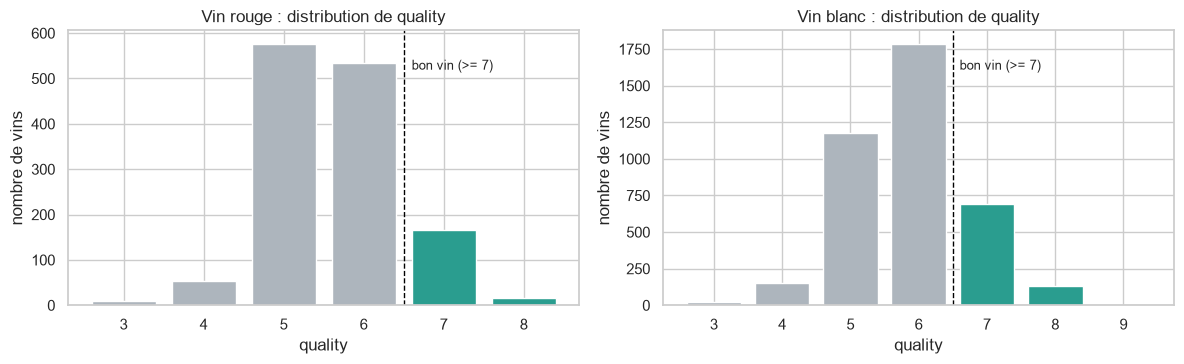

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, k in zip(axes, KINDS):
    counts = clean_data[k]["quality"].value_counts().sort_index()
    colors = ["#2a9d8f" if q >= 7 else "#adb5bd" for q in counts.index]
    ax.bar(counts.index, counts.values, color=colors)
    ax.axvline(6.5, color="black", ls="--", lw=1)
    ax.set(title=f"{LABELS[k]} : distribution de quality", xlabel="quality", ylabel="nombre de vins")
    ax.text(6.6, counts.max() * 0.9, "bon vin (>= 7)", fontsize=9)
fig.tight_layout()
savefig(fig, "quality_distribution")

**Limite :** la qualité est une médiane de notes d'experts ; les vins notés 6 et 7 sont très proches et la classe 6 est la plus nombreuse. La frontière 6/7 est donc floue, ce qui plafonne le F1 atteignable.

## 5. Découpage train/test

Découpage stratifié 80/20 (`random_state=42`) effectué dans `load_split`, juste après le nettoyage. Le test est mis de côté et **n'est plus utilisé** dans ce notebook.

In [10]:
splits = {k: load_split(k) for k in KINDS + ["both"]}
rows = []
for k, (X_tr, X_te, y_tr, y_te) in splits.items():
    assert "quality" not in X_tr.columns and "good" not in X_tr.columns
    assert abs(y_tr.mean() - y_te.mean()) < 0.01
    rows.append({"jeu": LABELS[k], "train": len(X_tr), "test": len(X_te),
                 "% bons (train)": 100 * y_tr.mean(), "% bons (test)": 100 * y_te.mean(),
                 "positifs dans le test": int(y_te.sum())})
pd.DataFrame(rows).set_index("jeu")

,train,test,% bons (train),% bons (test),positifs dans le test
jeu,,,,,
Vin rouge,1087,272,13.523,13.603,37
Vin blanc,3168,793,20.833,20.807,165
Fusionné,4256,1064,18.961,18.985,202


## 6. Déséquilibre des classes

,% bon vin,accuracy du classifieur majoritaire
Vin rouge,13.539,86.461
Vin blanc,20.828,79.172


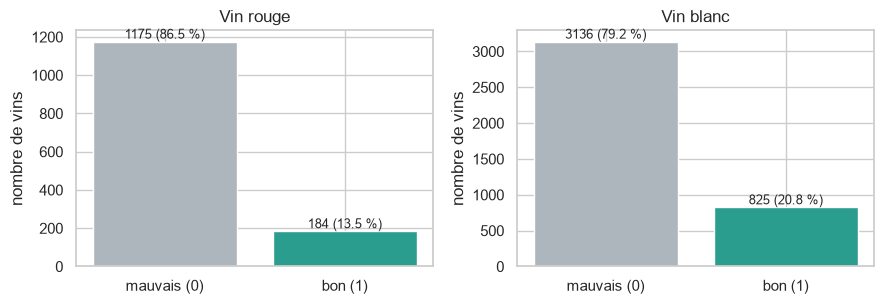

In [11]:
imb = pd.DataFrame({
    "% bon vin": {LABELS[k]: 100 * clean_data[k]["good"].mean() for k in KINDS},
    "accuracy du classifieur majoritaire": {LABELS[k]: 100 * (1 - clean_data[k]["good"].mean()) for k in KINDS},
})
display(imb)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, k in zip(axes, KINDS):
    counts = clean_data[k]["good"].value_counts().sort_index()
    ax.bar(["mauvais (0)", "bon (1)"], counts.values, color=["#adb5bd", "#2a9d8f"])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v} ({100 * v / counts.sum():.1f} %)", ha="center", va="bottom", fontsize=9)
    ax.set(title=LABELS[k], ylabel="nombre de vins")
fig.tight_layout()
savefig(fig, "target_balance")

**Décision :** avec 13,5 % (rouge) et 20,8 % (blanc) de positifs, prédire « mauvais » partout donne 86 % / 79 % d'accuracy : l'accuracy seule est trompeuse.
- découpage **stratifié** (vérifié ci-dessus) ;
- `class_weight="balanced"` par défaut pour les modèles qui l'acceptent (simple et sans fuite) ;
- évaluation par **F1, AUC et rappel**. SMOTE reste une extension.

## 7. Valeurs aberrantes

Détection par la règle IQR 1,5 (sur le train) et boxplots. **Aucune suppression** : ce sont des mesures réelles, et les bons vins sont rares et souvent atypiques.

In [12]:
def iqr_outliers(X):
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    return (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)

for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    out = iqr_outliers(X_tr)
    table = pd.DataFrame({
        "n aberrantes": out.sum(),
        "% (tous)": 100 * out.mean(),
        "% chez good=0": 100 * out[y_tr == 0].mean(),
        "% chez good=1": 100 * out[y_tr == 1].mean(),
    }).sort_values("n aberrantes", ascending=False)
    any_out = out.any(axis=1)
    print(f"\n=== {LABELS[k]} (train) : {100 * any_out.mean():.1f} % des lignes ont au moins une valeur aberrante "
          f"({100 * any_out[y_tr == 1].mean():.1f} % des bons vins) ===")
    display(table)


=== Vin rouge (train) : 25.4 % des lignes ont au moins une valeur aberrante (29.9 % des bons vins) ===


,n aberrantes,% (tous),% chez good=0,% chez good=1
residual sugar,102,9.384,8.830,12.925
chlorides,71,6.532,7.021,3.401
sulphates,45,4.140,4.043,4.762
fixed acidity,36,3.312,3.085,4.762
total sulfur dioxide,36,3.312,3.617,1.361
density,30,2.760,2.340,5.442
free sulfur dioxide,27,2.484,2.447,2.721
pH,24,2.208,2.021,3.401
volatile acidity,17,1.564,1.809,0.000
alcohol,8,0.736,0.426,2.721



=== Vin blanc (train) : 18.3 % des lignes ont au moins une valeur aberrante (10.8 % des bons vins) ===


,n aberrantes,% (tous),% chez good=0,% chez good=1
chlorides,163,5.145,6.220,1.061
citric acid,157,4.956,5.861,1.515
volatile acidity,113,3.567,4.027,1.818
sulphates,84,2.652,2.073,4.848
fixed acidity,82,2.588,2.990,1.061
pH,37,1.168,1.196,1.061
free sulfur dioxide,35,1.105,1.077,1.212
residual sugar,16,0.505,0.638,0.000
total sulfur dioxide,13,0.410,0.518,0.000
density,6,0.189,0.239,0.000


**Lecture :** environ un quart des vins rouges et un cinquième des blancs ont au moins une valeur aberrante. En rouge, les bons vins sont **plus** souvent atypiques (≈ 30 %), notamment en sucre résiduel, densité et alcool. En blanc, c'est l'inverse : les valeurs aberrantes (chlorures, acide citrique, acidité volatile) concernent surtout les mauvais vins, et sont donc informatives. Dans les deux cas, supprimer ces lignes retirerait une part importante du jeu et une partie du signal. On les conserve et on réduit plutôt leur influence par une transformation log.

**Choix des colonnes à passer en log :** variables dont l'asymétrie sur le **train** dépasse 1 en valeur absolue et qui sont strictement positives. Exclusions :
- `density` (valeurs ≈ 1 sur une plage minuscule : le log y est quasi linéaire) et `pH` (déjà une échelle logarithmique) ;
- `citric acid`, qui contient des zéros (log non défini).

On utilise `log` et non `log1p` : pour des valeurs petites comme les chlorures (≈ 0,08) ou les sulfates, log(1 + x) ≈ x et la transformation ne corrigerait presque rien. La transformation est **sans état** (aucun paramètre appris), donc sans fuite ; elle aide Naive Bayes, la régression logistique et le SVM.

In [13]:
NO_LOG = {"density", "pH"}
LOG_COLS = {}
for k in KINDS + ["both"]:
    X_tr = splits[k][0][FEATURES]
    skew = X_tr.skew()
    LOG_COLS[k] = [c for c in FEATURES if abs(skew[c]) > 1 and c not in NO_LOG and (X_tr[c] > 0).all()]

skew_table = pd.DataFrame({
    f"{LABELS[k]} avant": splits[k][0][FEATURES].skew() for k in KINDS
})
for k in KINDS:
    X_tr = splits[k][0][FEATURES].copy()
    X_tr[LOG_COLS[k]] = np.log(X_tr[LOG_COLS[k]])
    skew_table[f"{LABELS[k]} après log"] = X_tr.skew()
for k in KINDS + ["both"]:
    print(f"{LABELS[k]} : log sur {LOG_COLS[k]}")
skew_table

Vin rouge : log sur ['residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates']
Vin blanc : log sur ['volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide']
Fusionné : log sur ['fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'sulphates']


,Vin rouge avant,Vin blanc avant,Vin rouge après log,Vin blanc après log
fixed acidity,0.982,0.711,0.982,0.711
volatile acidity,0.785,1.690,0.785,0.195
citric acid,0.263,1.344,0.263,1.344
residual sugar,4.622,1.427,1.768,-0.068
chlorides,5.463,4.742,1.735,1.258
free sulfur dioxide,1.285,1.740,-0.194,-0.900
total sulfur dioxide,1.567,0.449,-0.084,0.449
density,0.079,1.479,0.079,1.479
pH,0.272,0.425,0.272,0.425
sulphates,2.364,0.949,0.986,0.949


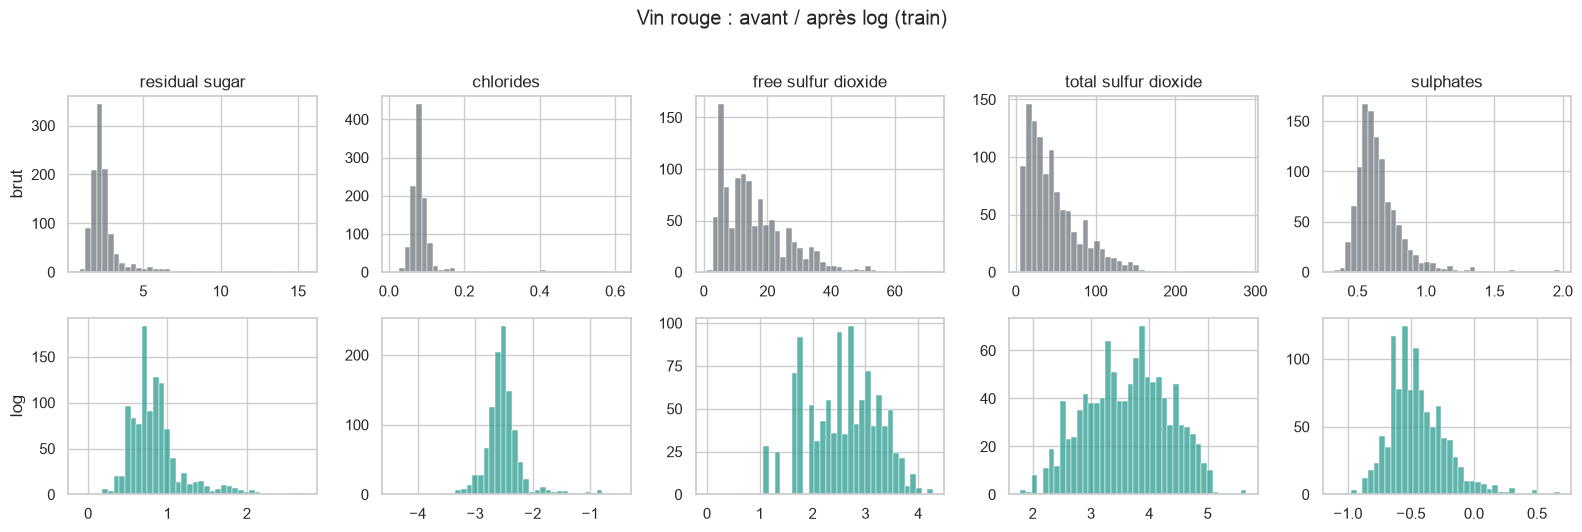

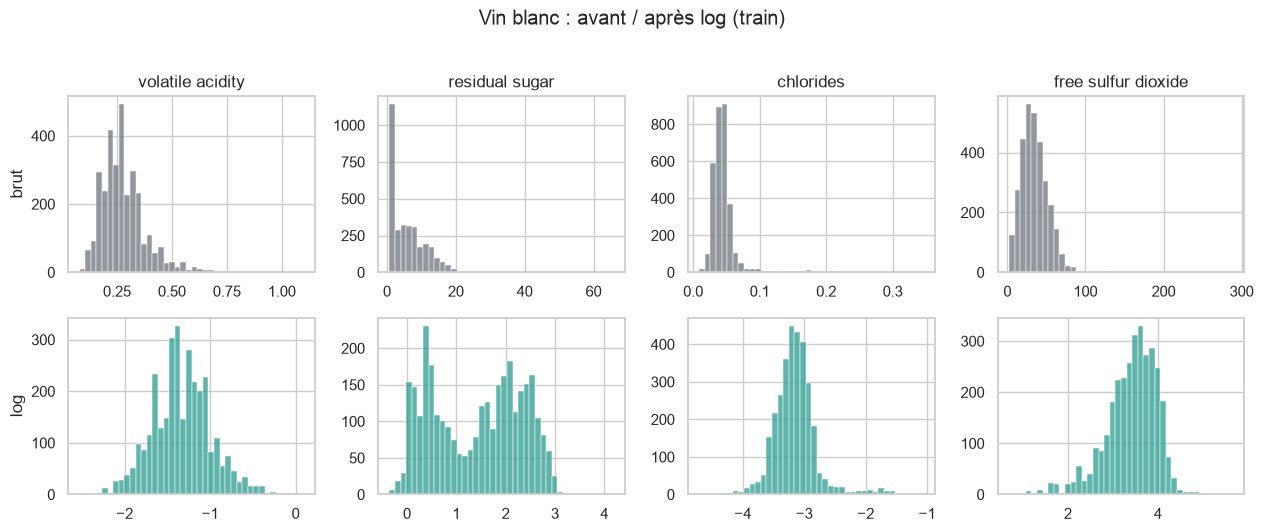

In [14]:
for k in KINDS:
    X_tr = splits[k][0]
    cols = LOG_COLS[k]
    fig, axes = plt.subplots(2, len(cols), figsize=(3.2 * len(cols), 5.2))
    for j, c in enumerate(cols):
        sns.histplot(X_tr[c], ax=axes[0, j], bins=40, color="#6c757d")
        sns.histplot(np.log(X_tr[c]), ax=axes[1, j], bins=40, color="#2a9d8f")
        axes[0, j].set(title=c, xlabel="", ylabel="brut" if j == 0 else "")
        axes[1, j].set(xlabel="", ylabel="log" if j == 0 else "")
    fig.suptitle(f"{LABELS[k]} : avant / après log (train)", y=1.02)
    fig.tight_layout()
    savefig(fig, f"log_transform_{k}")

## 8. Variables catégorielles

Les 11 variables explicatives sont numériques continues : **aucun encodage** n'est nécessaire pour les jeux séparés. Seul l'essai fusionné ajoute une colonne binaire `wine_type` (1 = rouge, 0 = blanc), qui n'introduit pas d'ordre artificiel.

In [15]:
print(splits["red"][0].dtypes.value_counts())
splits["both"][0]["wine_type"].value_counts().rename({0: "blanc", 1: "rouge"})

float64    11
Name: count, dtype: int64


wine_type
blanc    3169
rouge    1087
Name: count, dtype: int64

## 9. Corrélations

Calculées sur le **train** car elles servent à une décision (filtre de corrélation). Seuil de redondance : |r| > 0,8.

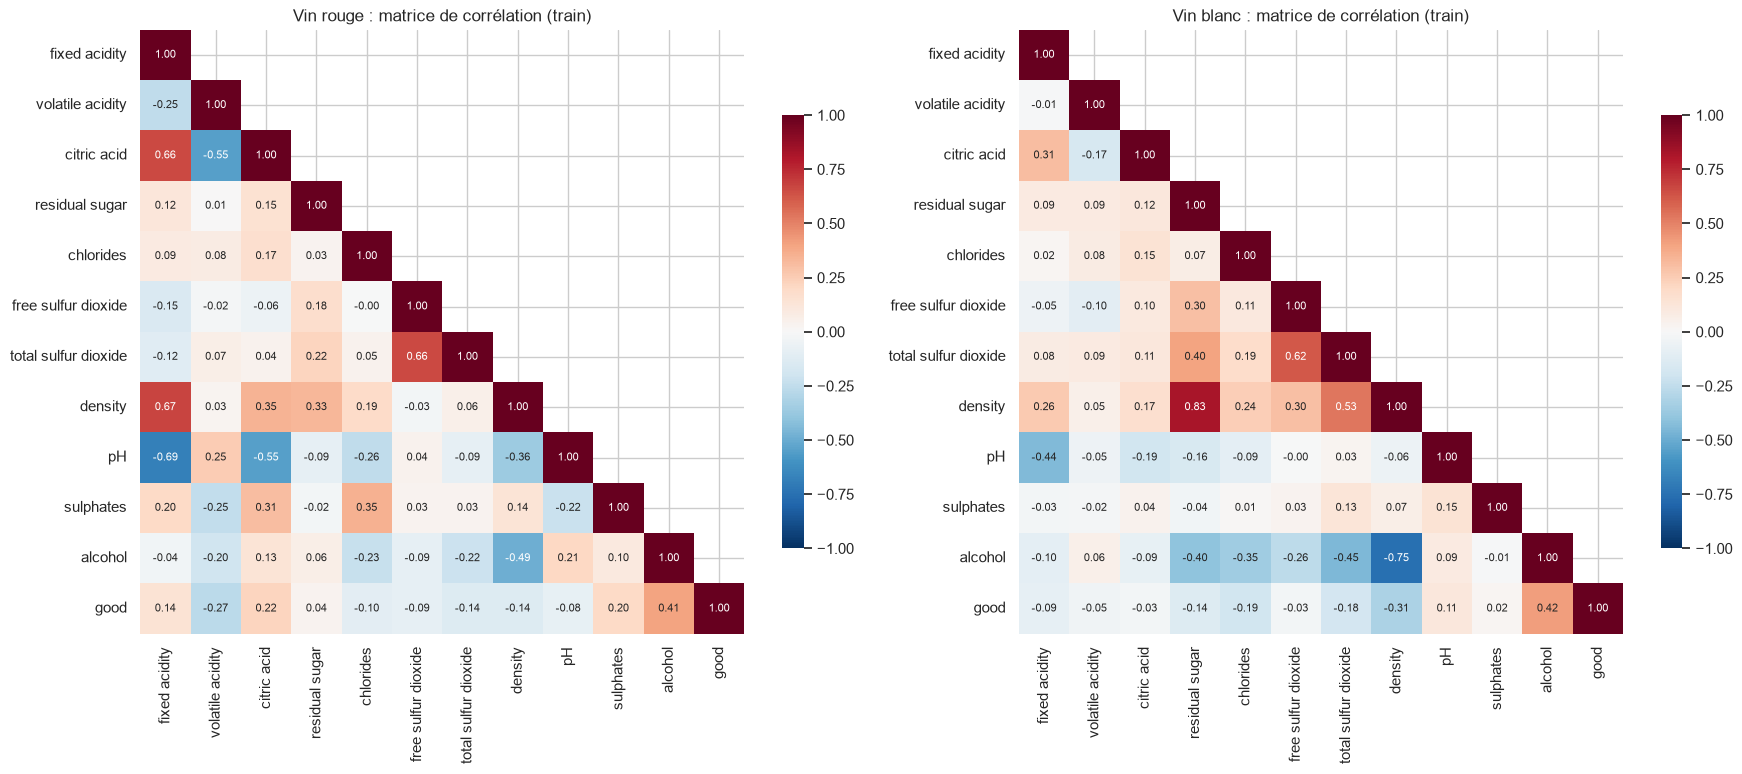

In [16]:
CORR_THRESHOLD = 0.8
corr_with_good = {}
redundant_pairs = {}

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for k in KINDS + ["both"]:
    c = splits[k][0][FEATURES].corr().abs()
    redundant_pairs[k] = [(a, b, round(float(c.loc[a, b]), 3)) for i, a in enumerate(c.columns)
                          for b in c.columns[i + 1:] if c.loc[a, b] > CORR_THRESHOLD]

for ax, k in zip(axes, KINDS):
    X_tr, _, y_tr, _ = splits[k]
    corr = X_tr.assign(good=y_tr).corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, cbar_kws={"shrink": 0.7}, annot_kws={"size": 8}, ax=ax)
    ax.set_title(f"{LABELS[k]} : matrice de corrélation (train)")
    corr_with_good[k] = corr["good"].drop("good")
fig.tight_layout()
savefig(fig, "correlation_matrix")

,Vin rouge,Vin blanc
alcohol,0.405,0.420
density,-0.140,-0.315
volatile acidity,-0.268,-0.046
citric acid,0.222,-0.027
sulphates,0.198,0.023
chlorides,-0.102,-0.189
total sulfur dioxide,-0.138,-0.181
fixed acidity,0.142,-0.088
residual sugar,0.035,-0.136
pH,-0.082,0.111


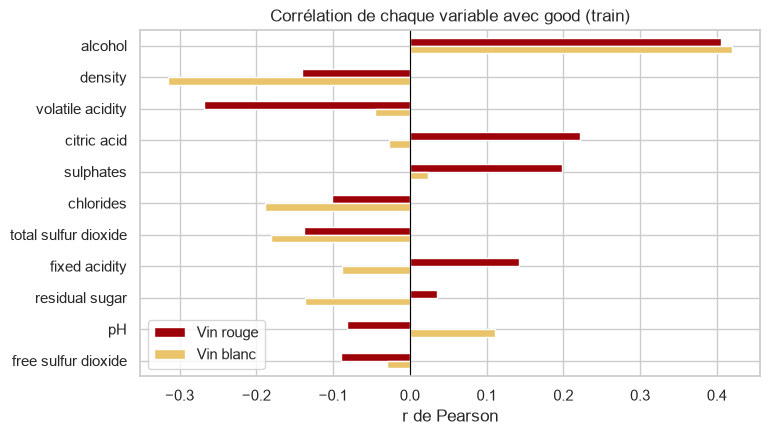

In [17]:
cg = pd.DataFrame({LABELS[k]: corr_with_good[k] for k in KINDS})
cg = cg.reindex(cg.abs().max(axis=1).sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(8, 4.5))
cg.plot.barh(ax=ax, color=["#9d0208", "#e9c46a"])
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set(title="Corrélation de chaque variable avec good (train)", xlabel="r de Pearson")
savefig(fig, "correlation_with_target")
cg

**Filtre de corrélation :** pour chaque paire au-dessus du seuil, on retire la variable la plus redondante, c'est-à-dire celle dont la corrélation absolue moyenne avec les autres variables est la plus forte (elle porte le moins d'information propre).

In [18]:
def correlation_drop_list(X, threshold=CORR_THRESHOLD):
    c = X.corr().abs()
    c = c.mask(np.eye(len(c), dtype=bool), 0.0)
    to_drop = set()
    for i, a in enumerate(c.columns):
        for b in c.columns[i + 1:]:
            if c.loc[a, b] > threshold and a not in to_drop and b not in to_drop:
                to_drop.add(a if c[a].mean() >= c[b].mean() else b)
    return sorted(to_drop)

CORR_DROP = {k: correlation_drop_list(splits[k][0][FEATURES]) for k in KINDS + ["both"]}
for k in KINDS + ["both"]:
    print(f"{LABELS[k]} : paires |r| > {CORR_THRESHOLD} = {redundant_pairs[k]} -> à retirer : {CORR_DROP[k]}")

Vin rouge : paires |r| > 0.8 = [] -> à retirer : []
Vin blanc : paires |r| > 0.8 = [('residual sugar', 'density', 0.826)] -> à retirer : ['density']
Fusionné : paires |r| > 0.8 = [] -> à retirer : []


**Lecture :**
- **Rouge :** aucune paire ne dépasse 0,8 (les plus fortes, ≈ 0,67-0,69, relient l'acidité fixe à l'acide citrique, à la densité et au pH). Le filtre ne retire rien.
- **Blanc :** `density` est très liée au sucre résiduel (r ≈ 0,82) et à l'alcool (r ≈ -0,76) : c'est la variable retirée.
- Les variables les plus liées à `good` sont l'**alcool** (r ≈ 0,4 dans les deux cas), puis l'acidité volatile, l'acide citrique et les sulfates (rouge), la densité, les chlorures et le SO₂ total (blanc). Les facteurs de qualité diffèrent selon le type, ce qui confirme l'analyse séparée.
- Ces redondances pénalisent surtout Naive Bayes (hypothèse d'indépendance) et rendent instables les coefficients de la régression logistique.

## 10. Visualisations

Graphiques purement descriptifs : ils peuvent utiliser toutes les données nettoyées (aucune décision n'en découle).

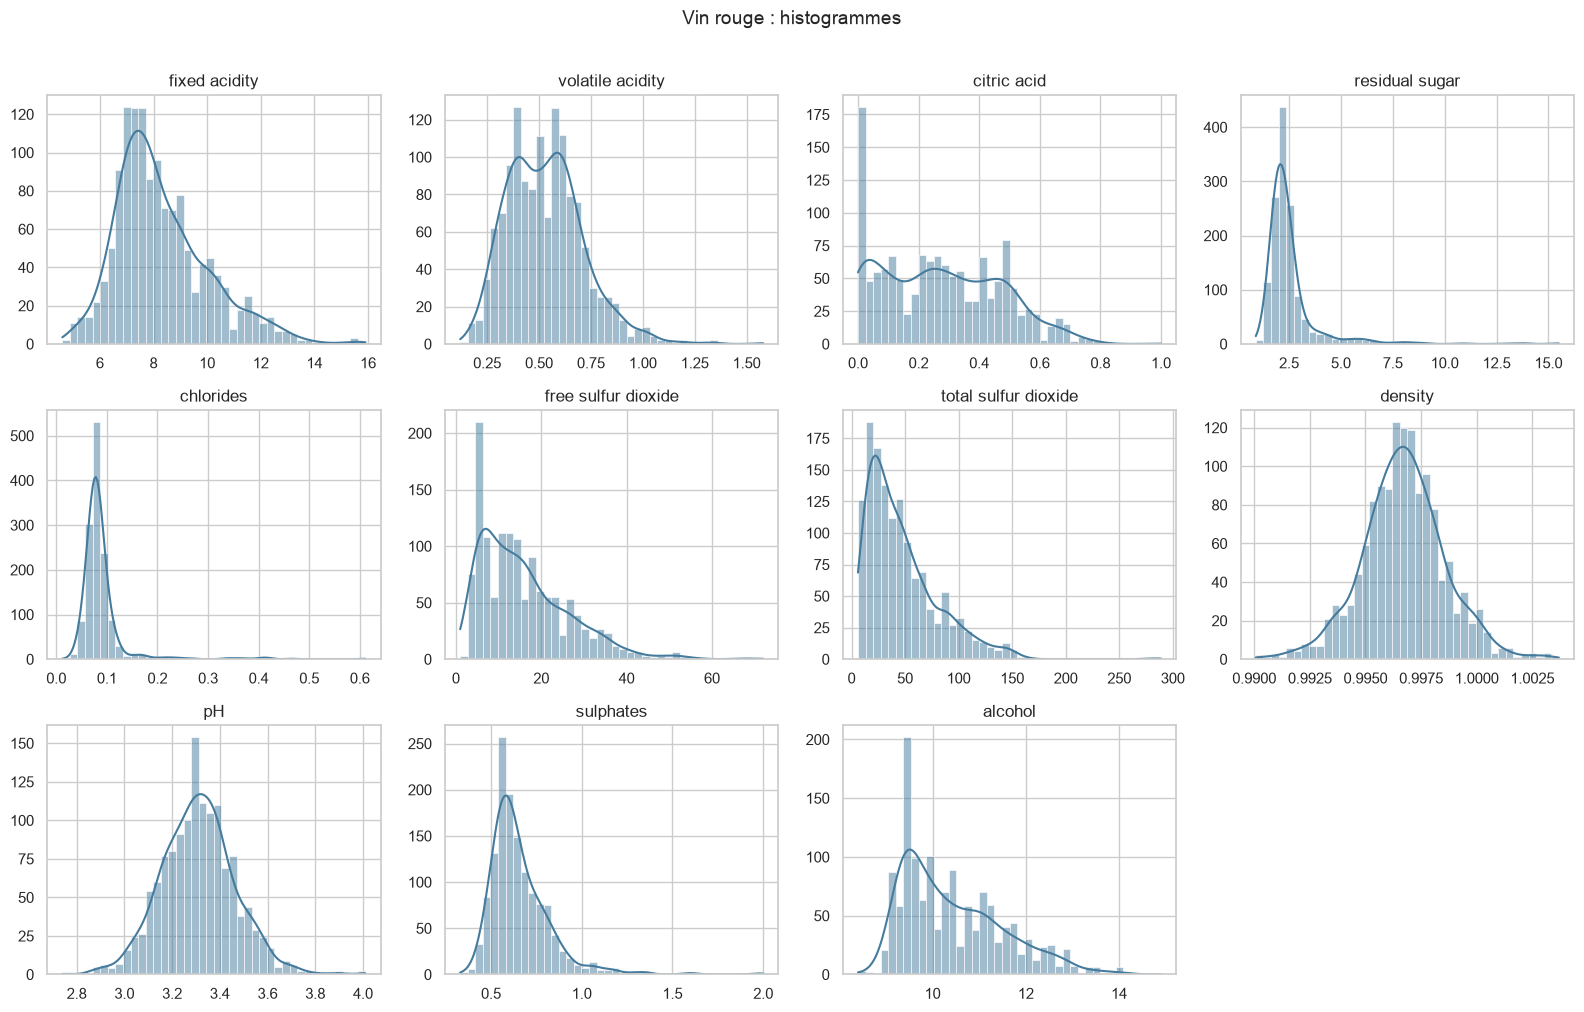

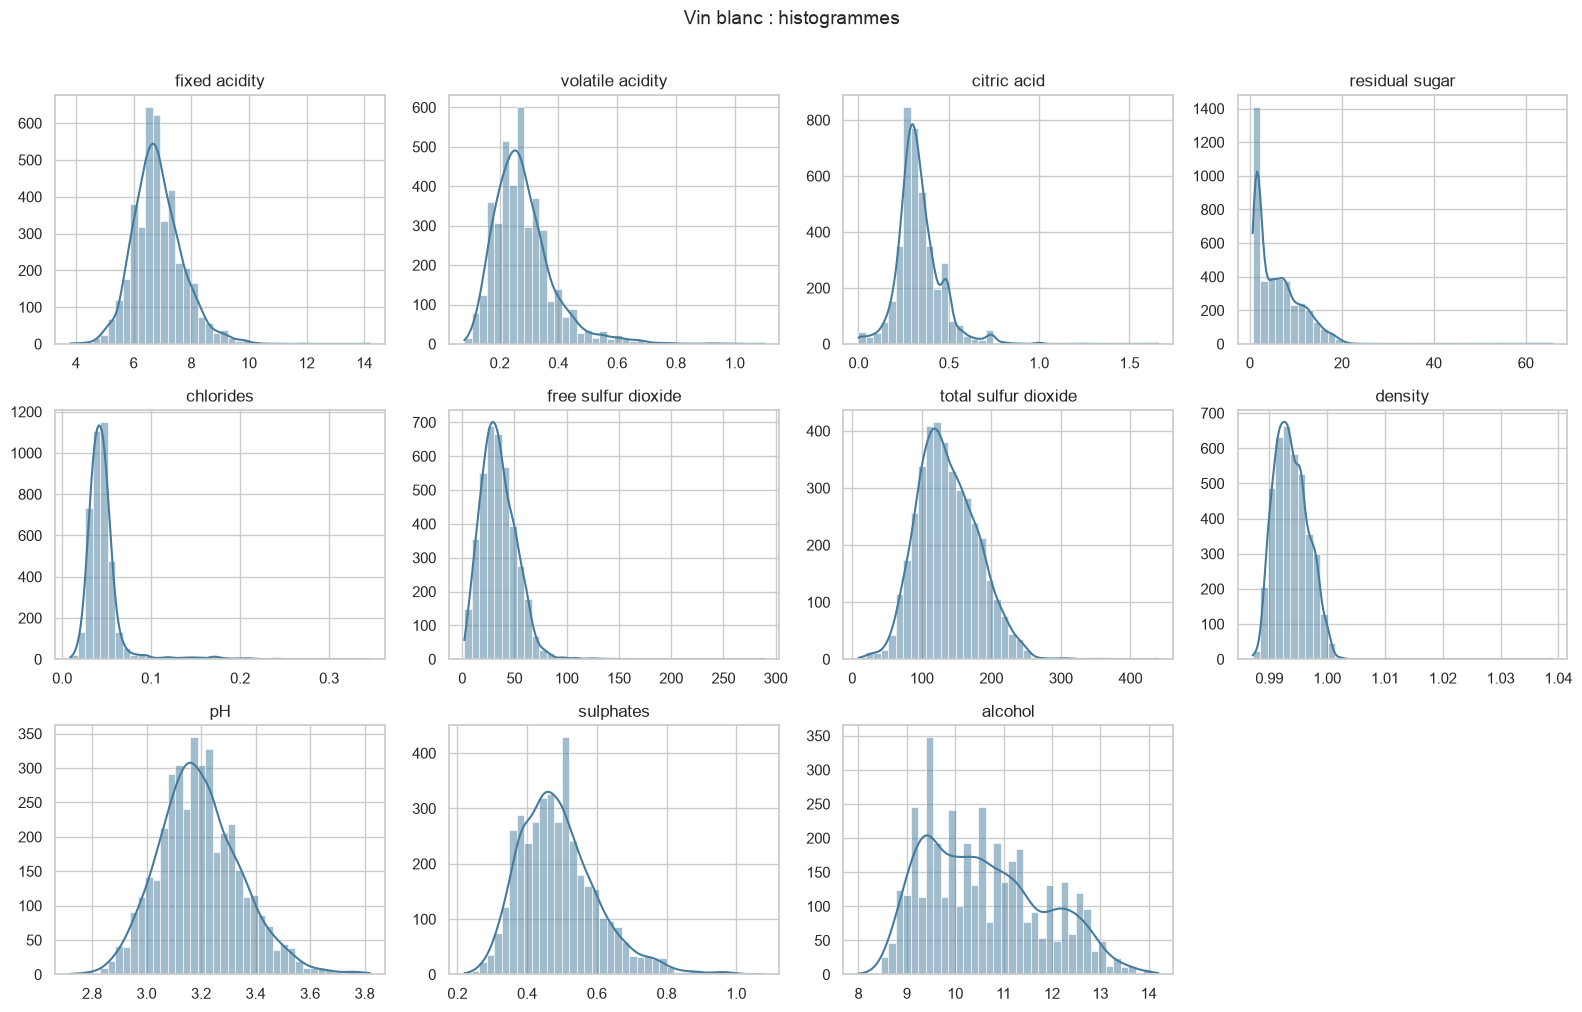

In [19]:
for k in KINDS:
    df = clean_data[k]
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    for ax, c in zip(axes.flat, FEATURES):
        sns.histplot(df[c], bins=40, kde=True, ax=ax, color="#457b9d")
        ax.set(xlabel="", ylabel="", title=c)
    axes.flat[-1].axis("off")
    fig.suptitle(f"{LABELS[k]} : histogrammes", y=1.01, fontsize=14)
    fig.tight_layout()
    savefig(fig, f"histograms_{k}")

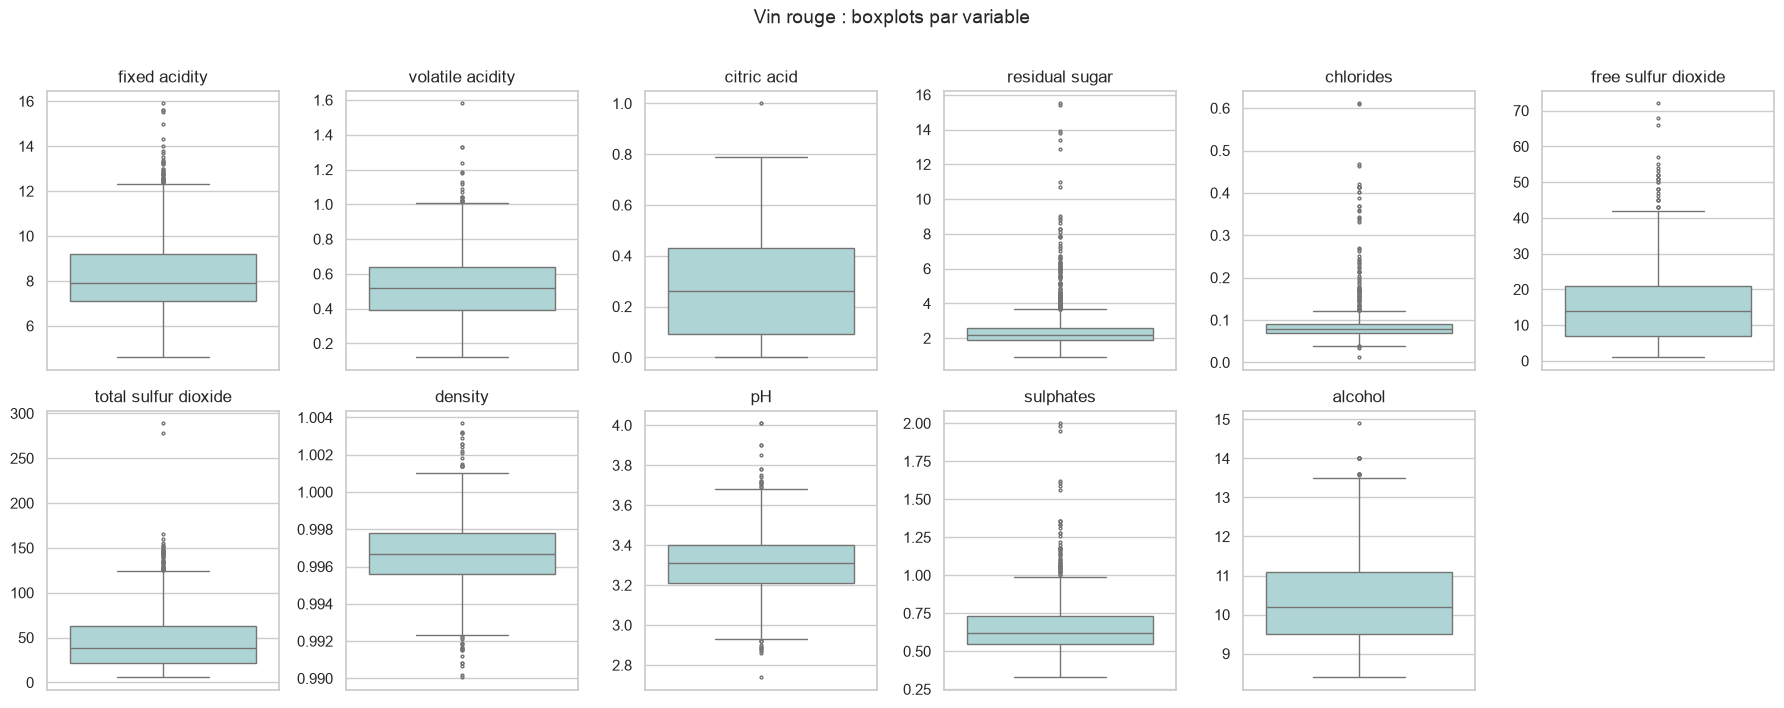

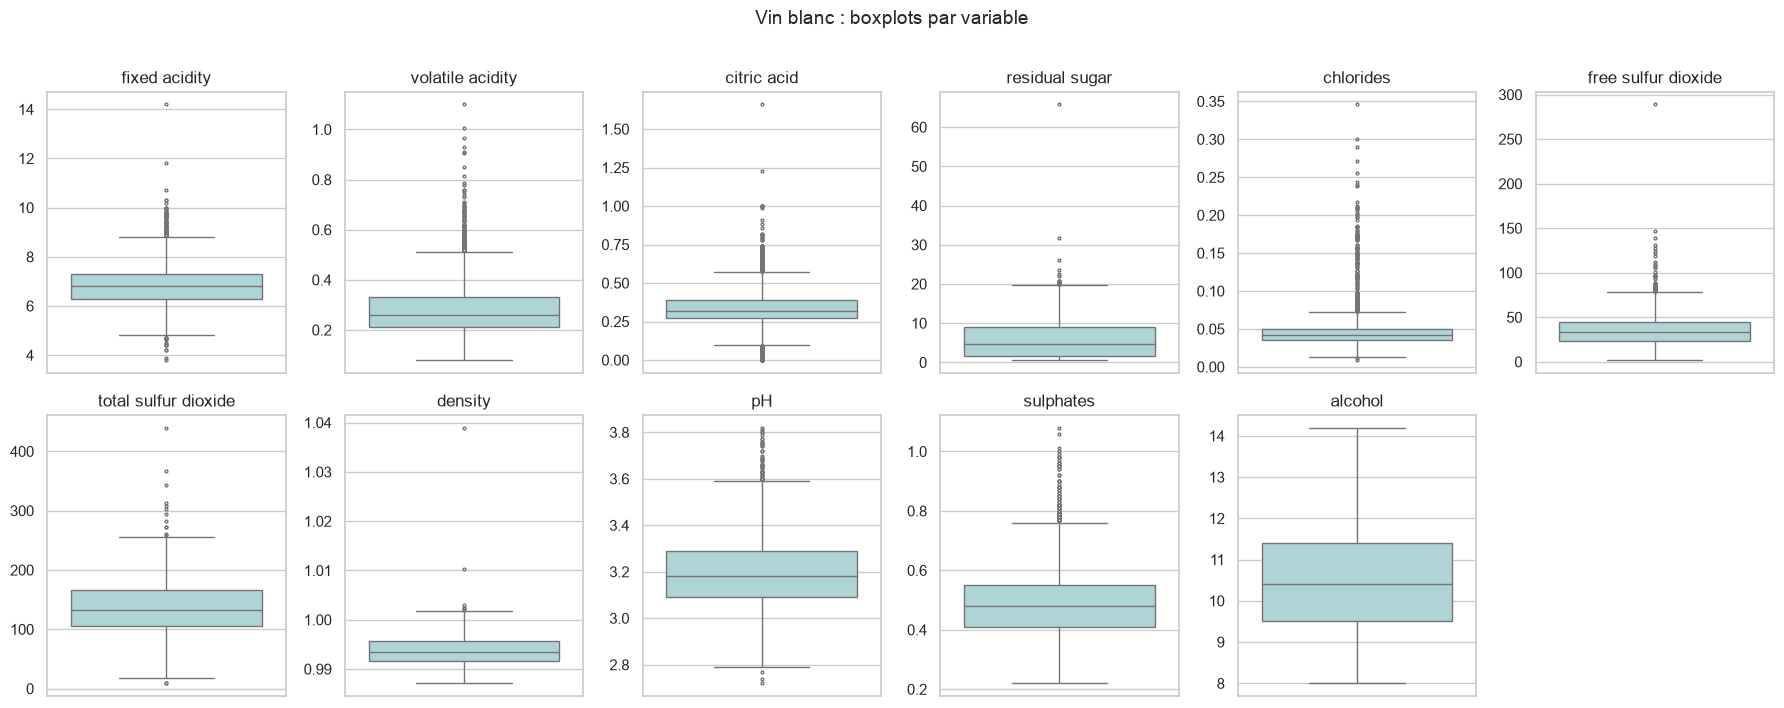

In [20]:
for k in KINDS:
    df = clean_data[k]
    fig, axes = plt.subplots(2, 6, figsize=(18, 7))
    for ax, c in zip(axes.flat, FEATURES):
        sns.boxplot(y=df[c], ax=ax, color="#a8dadc", fliersize=2)
        ax.set(title=c, ylabel="")
    axes.flat[-1].axis("off")
    fig.suptitle(f"{LABELS[k]} : boxplots par variable", y=1.01, fontsize=14)
    fig.tight_layout()
    savefig(fig, f"boxplots_{k}")

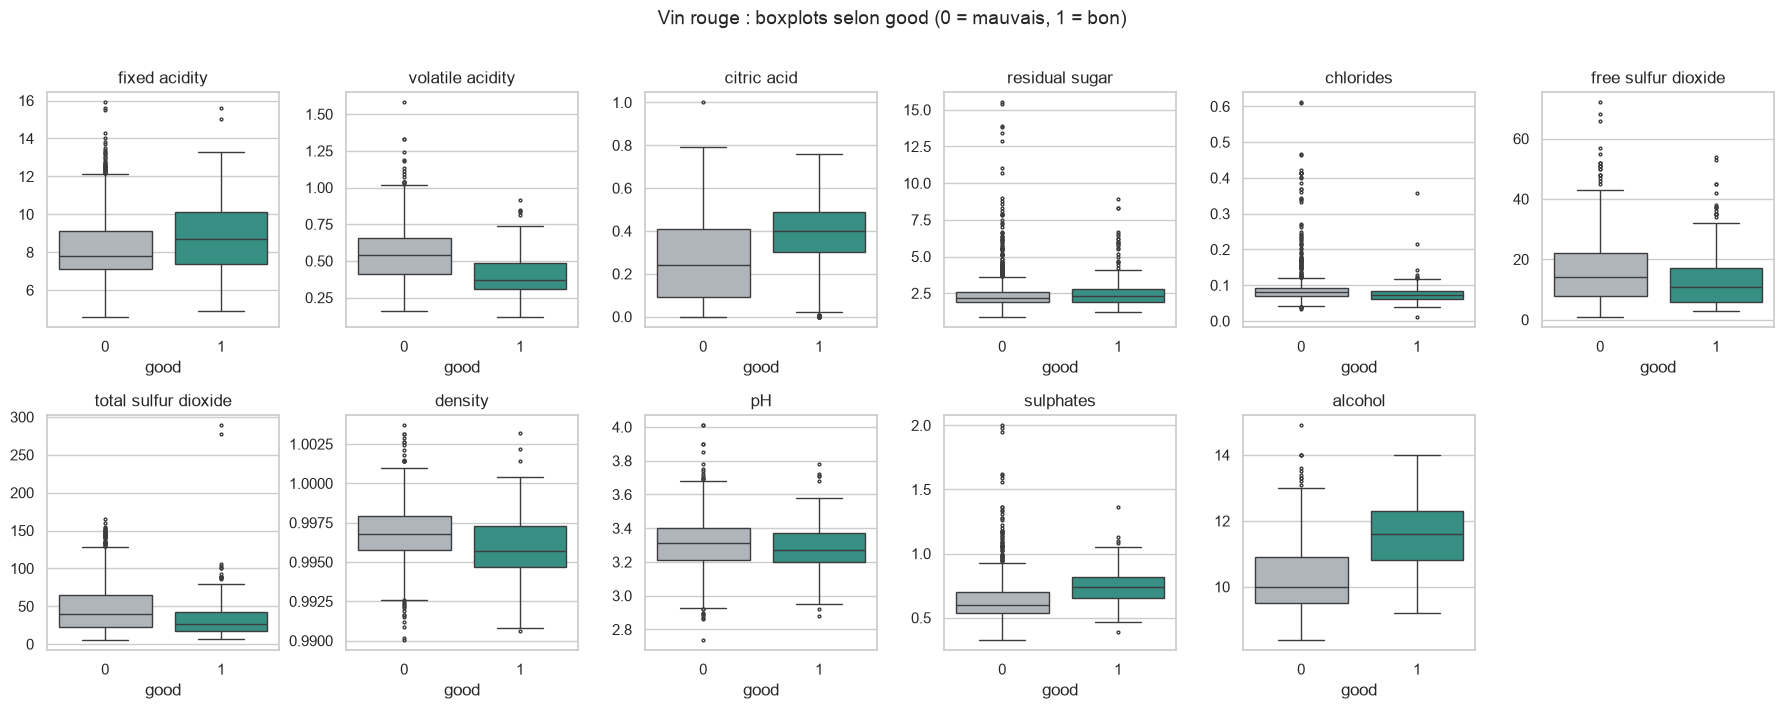

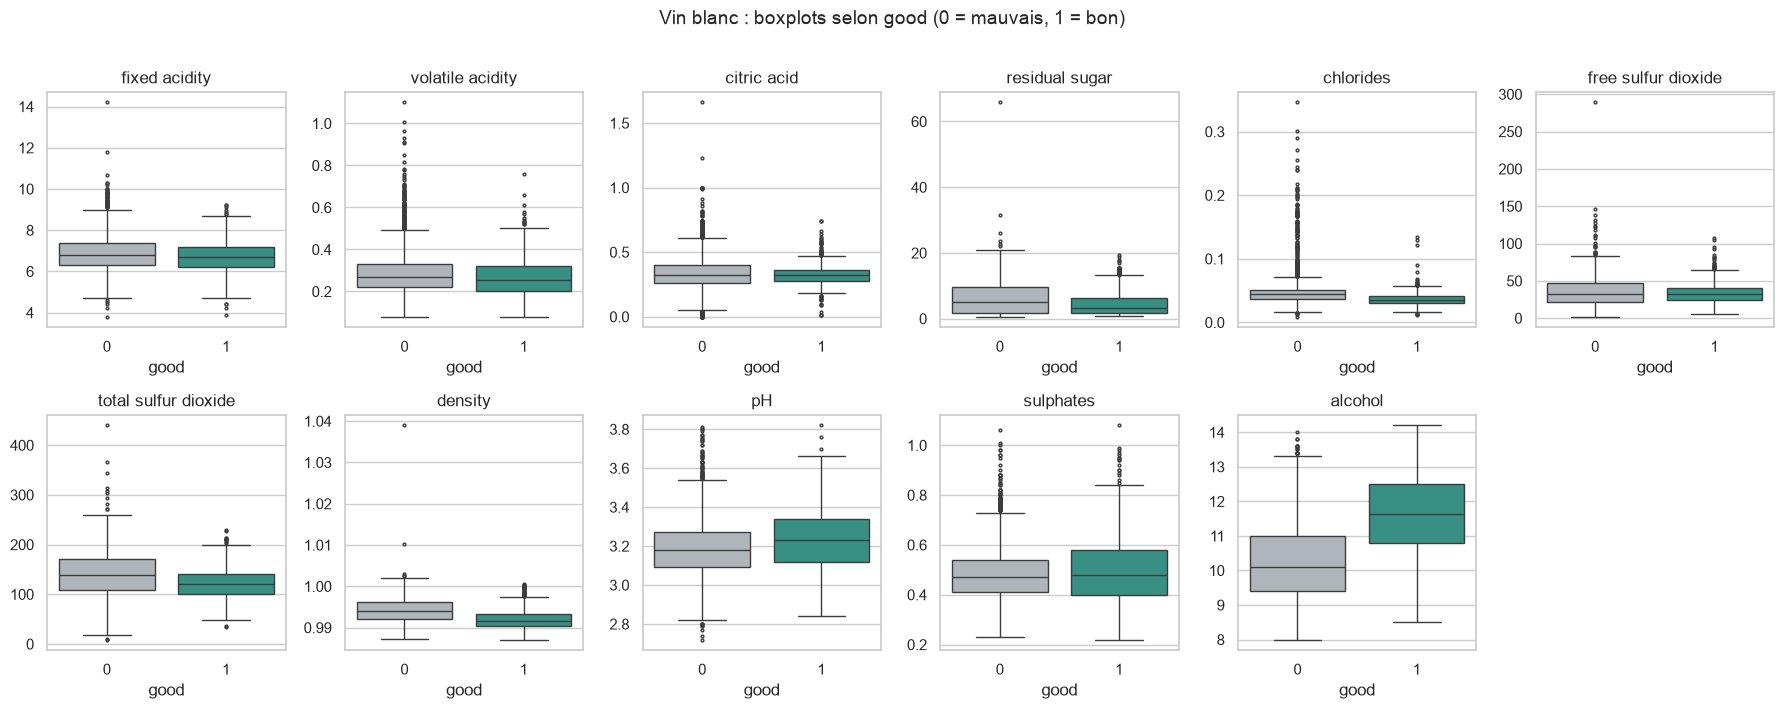

In [21]:
for k in KINDS:
    df = clean_data[k]
    fig, axes = plt.subplots(2, 6, figsize=(18, 7))
    for ax, c in zip(axes.flat, FEATURES):
        sns.boxplot(data=df, x="good", y=c, hue="good", ax=ax, palette=["#adb5bd", "#2a9d8f"],
                    legend=False, fliersize=2)
        ax.set(title=c, ylabel="", xlabel="good")
    axes.flat[-1].axis("off")
    fig.suptitle(f"{LABELS[k]} : boxplots selon good (0 = mauvais, 1 = bon)", y=1.01, fontsize=14)
    fig.tight_layout()
    savefig(fig, f"boxplots_by_good_{k}")

**Lecture :** l'alcool est la variable qui sépare le mieux les classes dans les deux types (médiane nettement plus haute chez les bons vins). En rouge, les bons vins ont moins d'acidité volatile et plus de sulfates ; en blanc, une densité et des chlorures plus faibles. Les boîtes se chevauchent largement pour les autres variables : aucune variable seule ne suffit.

## 11. Sélection de variables

Trois familles de méthodes comparées par validation croisée stratifiée 5 plis **sur le train** :

| Méthode | Famille | Où est-elle apprise ? |
|---|---|---|
| Filtre de corrélation | Filtre (redondance) | Liste fixée d'après l'analyse du train (section 9) |
| `SelectKBest` (ANOVA F, information mutuelle) | Filtre (univarié) | Dans le `Pipeline`, pli par pli |
| L1 (`SelectFromModel` + régression logistique pénalisée L1) | Embarquée | Dans le `Pipeline`, pli par pli |

Modèles de référence : régression logistique (`class_weight="balanced"`) et Naive Bayes gaussien (le plus sensible aux variables redondantes). Prétraitement commun : `log` sur les colonnes asymétriques puis `StandardScaler`.

In [22]:
def ref_models():
    return {
        "LogReg": LogisticRegression(class_weight="balanced", max_iter=2000),
        "GaussianNB": GaussianNB(),
    }


def l1_selector(C=0.1):
    return SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=C,
                                              class_weight="balanced", random_state=SEED))


mi = partial(mutual_info_classif, random_state=SEED)


def selection_pipe(kind, model, selector=None, drop_cols=()):
    steps = [("prep", make_preprocessor(LOG_COLS[kind], drop_cols=drop_cols))]
    if selector is not None:
        steps.append(("select", selector))
    steps.append(("model", model))
    return Pipeline(steps)

### 11.1 Choix de k pour `SelectKBest`

Courbe F1 / AUC en fonction de k (validation croisée sur le train).

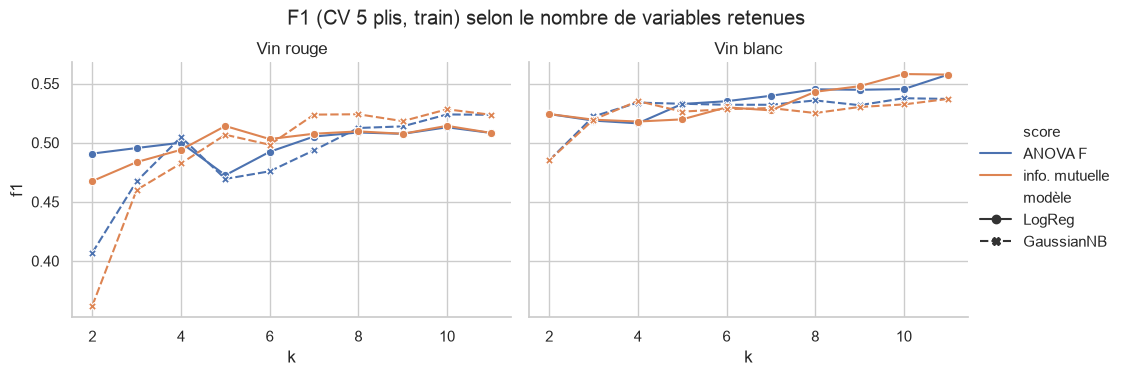

In [23]:
K_GRID = range(2, len(FEATURES) + 1)
kbest_curves = []
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    for score_name, score_func in [("ANOVA F", f_classif), ("info. mutuelle", mi)]:
        for n in K_GRID:
            for m_name, model in ref_models().items():
                s = cv_scores(selection_pipe(k, model, SelectKBest(score_func, k=n)), X_tr, y_tr)
                kbest_curves.append({"vin": LABELS[k], "score": score_name, "modèle": m_name, "k": n,
                                     "f1": s["f1"], "roc_auc": s["roc_auc"]})
kbest_curves = pd.DataFrame(kbest_curves)

g = sns.relplot(data=kbest_curves, x="k", y="f1", hue="score", style="modèle", col="vin",
                kind="line", markers=True, height=3.6, aspect=1.4)
g.set_titles("{col_name}")
g.fig.suptitle("F1 (CV 5 plis, train) selon le nombre de variables retenues", y=1.04)
savefig(g.fig, "kbest_curves")

On retient, pour chaque type de vin et chaque score, le **plus petit k dont le F1 moyen (sur les deux modèles) est à moins de 0,01 du meilleur** : même performance avec moins de variables.

In [24]:
BEST_K = {}
for (vin, score_name), grp in kbest_curves.groupby(["vin", "score"]):
    mean_f1 = grp.groupby("k")["f1"].mean()
    BEST_K[(vin, score_name)] = int(mean_f1[mean_f1 >= mean_f1.max() - 0.01].index.min())
pd.Series(BEST_K, name="k retenu").rename_axis(["vin", "score"]).unstack()

score,ANOVA F,info. mutuelle
vin,,
Vin blanc,8,9
Vin rouge,8,7


### 11.2 Comparaison des méthodes

In [25]:
selection_rows = []
selected_features = {}
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    k_f = BEST_K[(LABELS[k], "ANOVA F")]
    k_mi = BEST_K[(LABELS[k], "info. mutuelle")]
    methods = {
        "toutes les variables": dict(),
        "filtre de corrélation": dict(drop_cols=CORR_DROP[k]),
        f"SelectKBest ANOVA (k={k_f})": dict(selector=SelectKBest(f_classif, k=k_f)),
        f"SelectKBest info. mutuelle (k={k_mi})": dict(selector=SelectKBest(mi, k=k_mi)),
        "L1 (C=0.1)": dict(selector=l1_selector(0.1)),
    }
    for meth, kw in methods.items():
        for m_name, model in ref_models().items():
            pipe = selection_pipe(k, model, **kw)
            s = cv_scores(pipe, X_tr, y_tr)
            # variables retenues par la méthode, ajustée sur tout le train (pour information)
            names = pipe.fit(X_tr, y_tr)[:-1].get_feature_names_out()
            selected_features[(LABELS[k], meth)] = list(names)
            selection_rows.append({"vin": LABELS[k], "méthode": meth, "modèle": m_name, "n variables": len(names),
                                   "F1": s["f1"], "F1 std": s["f1_std"], "AUC": s["roc_auc"],
                                   "rappel": s["recall"], "précision": s["precision"]})

selection = pd.DataFrame(selection_rows)
selection.set_index(["vin", "méthode", "modèle"]).round(3)

n variables     F1  F1 std    AUC  rappel  précision
vin       méthode                          modèle                                                          
Vin rouge toutes les variables             LogReg               11  0.508   0.019  0.872   0.802      0.373
                                           GaussianNB           11  0.524   0.042  0.848   0.639      0.445
          filtre de corrélation            LogReg               11  0.508   0.019  0.872   0.802      0.373
                                           GaussianNB           11  0.524   0.042  0.848   0.639      0.445
          SelectKBest ANOVA (k=8)          LogReg                8  0.509   0.013  0.871   0.816      0.372
                                           GaussianNB            8  0.512   0.019  0.848   0.625      0.435
          SelectKBest info. mutuelle (k=7) LogReg                7  0.508   0.019  0.870   0.816      0.369
                                           GaussianNB            7  0.524   0.030  0.850   0.612      0.459
          L1 (C=0.1)                       LogReg                8  0.509   0.018  0.874   0.802      0.374
                                           GaussianNB            8  0.530   0.064  0.858   0.571      0.497
Vin blanc toutes les variables             LogReg               11  0.558   0.026  0.822   0.786      0.432
                                           GaussianNB           11  0.537   0.029  0.802   0.658      0.454
          filtre de corrélation            LogReg               10  0.564   0.026  0.817   0.789      0.439
                                           GaussianNB           10  0.525   0.026  0.809   0.595      0.471
          SelectKBest ANOVA (k=8)          LogReg                8  0.545   0.026  0.813   0.777      0.420
                                           GaussianNB            8  0.536   0.028  0.793   0.639      0.461
          SelectKBest info. mutuelle (k=9) LogReg                9  0.548   0.033  0.811   0.758      0.429
                                           GaussianNB            9  0.530   0.035  0.798   0.641      0.453
          L1 (C=0.1)                       LogReg               11  0.557   0.026  0.822   0.786      0.432
                                           GaussianNB           11  0.533   0.031  0.801   0.638      0.459

In [26]:
pivot = selection.pivot_table(index=["vin", "méthode"], columns="modèle", values=["F1", "AUC"], sort=False)
pivot.round(3)

F1               AUC           
modèle                                     LogReg GaussianNB LogReg GaussianNB
vin       méthode                                                             
Vin rouge toutes les variables              0.508      0.524  0.872      0.848
          filtre de corrélation             0.508      0.524  0.872      0.848
          SelectKBest ANOVA (k=8)           0.509      0.512  0.871      0.848
          SelectKBest info. mutuelle (k=7)  0.508      0.524  0.870      0.850
          L1 (C=0.1)                        0.509      0.530  0.874      0.858
Vin blanc toutes les variables              0.558      0.537  0.822      0.802
          filtre de corrélation             0.564      0.525  0.817      0.809
          SelectKBest ANOVA (k=8)           0.545      0.536  0.813      0.793
          L1 (C=0.1)                        0.557      0.533  0.822      0.801
          SelectKBest info. mutuelle (k=9)  0.548      0.530  0.811      0.798

In [27]:
retained = pd.DataFrame(
    {key: pd.Series(True, index=names) for key, names in selected_features.items()}
).reindex(FEATURES).fillna(False).T
retained.index.names = ["vin", "méthode"]
retained.replace({True: "x", False: ""})

fixed acidity volatile acidity citric acid residual sugar chlorides free sulfur dioxide  \
vin       méthode                                                                                                                    
Vin rouge toutes les variables                         x                x           x              x         x                   x   
          filtre de corrélation                        x                x           x              x         x                   x   
          SelectKBest ANOVA (k=8)                      x                x           x                        x                       
          SelectKBest info. mutuelle (k=7)             x                x           x                                                
          L1 (C=0.1)                                   x                x                          x         x                       
Vin blanc toutes les variables                         x                x           x              x         x                   x   
          filtre de corrélation                        x                x           x              x         x                   x   
          SelectKBest ANOVA (k=8)                      x                x                          x         x                       
          SelectKBest info. mutuelle (k=9)             x                x           x              x         x                       
          L1 (C=0.1)                                   x                x           x              x         x                   x   

                                           total sulfur dioxide density pH sulphates alcohol  
vin       méthode                                                                             
Vin rouge toutes les variables                                x       x  x         x       x  
          filtre de corrélation                               x       x  x         x       x  
          SelectKBest ANOVA (k=8)                             x       x            x       x  
          SelectKBest info. mutuelle (k=7)                    x       x            x       x  
          L1 (C=0.1)                                          x          x         x       x  
Vin blanc toutes les variables                                x       x  x         x       x  
          filtre de corrélation                               x          x         x       x  
          SelectKBest ANOVA (k=8)                             x       x  x                 x  
          SelectKBest info. mutuelle (k=9)                    x       x  x                 x  
          L1 (C=0.1)                                          x       x  x         x       x

**Lecture :**
- Avec seulement 11 variables, aucune méthode ne gagne nettement : les écarts de F1 (≈ 0,01) restent inférieurs à l'écart-type entre plis (0,02 à 0,06). Le gain est **la même performance avec moins de variables**.
- **Rouge :** la sélection L1 garde 8 variables (retire acide citrique, SO₂ libre et densité) sans perte pour la régression logistique, et c'est la meilleure configuration pour Naive Bayes (F1 ≈ 0,53, AUC ≈ 0,86). Le filtre de corrélation ne retire rien (aucune paire > 0,8).
- **Blanc :** retirer `density` (filtre de corrélation) donne le meilleur F1 logistique et améliore l'AUC de Naive Bayes, ce qui est cohérent avec la redondance densité/sucre/alcool. Avec C = 0,1, L1 ne retire aucune variable : C devra être réglé.
- Variables retenues par presque toutes les méthodes : alcool, acidité volatile, sulfates et SO₂ total (rouge) ; alcool, acidité volatile, chlorures, sucre résiduel et SO₂ total (blanc).
- **Pour la suite :** les sélecteurs à paramètres appris (`SelectKBest`, L1) sont placés **dans le `Pipeline`** et leur hyperparamètre (k, C) sera réglé avec ceux du modèle en section 2.4 ; le filtre de corrélation est une liste fixée d'après le train (`CORR_DROP`).

## 12. Effet des doublons : avec vs sans

Même pipeline k-NN (log + `StandardScaler` + k-NN, k=5), validation croisée sur le train construit **avec** puis **sans** doublons. Avec doublons, un vin peut avoir son jumeau exact dans le pli d'entraînement : son plus proche voisin est alors à distance nulle.

In [28]:
dup_rows = []
for k in KINDS:
    for dedup in (False, True):
        X_tr, _, y_tr, _ = load_split(k, dedup=dedup)
        pipe = Pipeline([("prep", make_preprocessor(LOG_COLS[k])), ("model", KNeighborsClassifier(n_neighbors=5))])
        s = cv_scores(pipe, X_tr, y_tr)
        dup_rows.append({"vin": LABELS[k], "doublons": "supprimés" if dedup else "conservés", "n train": len(X_tr),
                         "F1": s["f1"], "AUC": s["roc_auc"], "rappel": s["recall"], "accuracy": s["accuracy"]})
pd.DataFrame(dup_rows).set_index(["vin", "doublons"]).round(3)

n train     F1    AUC  rappel  accuracy
vin       doublons                                          
Vin rouge conservés     1279  0.482  0.821   0.431     0.874
          supprimés     1087  0.399  0.791   0.346     0.859
Vin blanc conservés     3918  0.555  0.828   0.512     0.823
          supprimés     3168  0.484  0.792   0.430     0.808

Les scores obtenus **avec** doublons sont plus élevés : c'est une estimation optimiste, due aux jumeaux présents de part et d'autre de la frontière train/validation, et non à un meilleur modèle. Cela justifie la suppression des doublons avant tout découpage.

## 13. StandardScaler ou RobustScaler

Comparaison sur un modèle sensible à l'échelle (k-NN) et sur la régression logistique, après `log`.

In [29]:
scaler_rows = []
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    for scaler in ("standard", "robust"):
        for m_name, model in {"LogReg": LogisticRegression(class_weight="balanced", max_iter=2000),
                              "k-NN": KNeighborsClassifier(n_neighbors=5)}.items():
            pipe = Pipeline([("prep", make_preprocessor(LOG_COLS[k], scaler=scaler)), ("model", model)])
            s = cv_scores(pipe, X_tr, y_tr)
            scaler_rows.append({"vin": LABELS[k], "modèle": m_name, "scaler": scaler,
                                "F1": s["f1"], "F1 std": s["f1_std"], "AUC": s["roc_auc"]})
scalers = pd.DataFrame(scaler_rows)
scalers.pivot_table(index=["vin", "modèle"], columns="scaler", values=["F1", "AUC"]).round(3)

AUC              F1         
scaler           robust standard robust standard
vin       modèle                                
Vin blanc LogReg  0.822    0.822  0.557    0.558
          k-NN    0.791    0.792  0.489    0.484
Vin rouge LogReg  0.872    0.872  0.506    0.508
          k-NN    0.818    0.791  0.416    0.399

Après la transformation log, les valeurs extrêmes sont déjà atténuées : les deux scalers donnent les mêmes résultats pour la régression logistique. Seul le k-NN sur le rouge profite un peu de `RobustScaler` (AUC ≈ 0,82 contre 0,79). On garde **`StandardScaler`** par défaut, et `scaler` reste un paramètre de `make_preprocessor` à inclure dans la recherche d'hyperparamètres du k-NN et du SVM.

## 14. Essai fusionné rouge + blanc

Un seul essai : jeu fusionné avec `wine_type`, découpage stratifié sur `wine_type × good`, même pipeline de référence. Pour comparer à armes égales, le modèle fusionné est aussi évalué séparément sur les vins rouges et blancs de ses plis de validation.

In [30]:
from sklearn.base import clone
from sklearn.metrics import f1_score, roc_auc_score

def ref_pipe(kind):
    return Pipeline([("prep", make_preprocessor(LOG_COLS[kind])),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=2000))])

merged_rows = []
for k in KINDS + ["both"]:
    X_tr, _, y_tr, _ = splits[k]
    s = cv_scores(ref_pipe(k), X_tr, y_tr)
    merged_rows.append({"entraîné sur": LABELS[k], "évalué sur": LABELS[k], "F1": s["f1"], "AUC": s["roc_auc"]})

# modèle fusionné, scores par type de vin sur les mêmes plis de validation
X_tr, _, y_tr, _ = splits["both"]
strat = X_tr["wine_type"].astype(str) + "_" + y_tr.astype(str)
per_type = {0: {"f1": [], "auc": []}, 1: {"f1": [], "auc": []}}
for tr, va in CV.split(X_tr, strat):
    pipe = clone(ref_pipe("both")).fit(X_tr.iloc[tr], y_tr.iloc[tr])
    for t in (0, 1):
        m = X_tr.iloc[va]["wine_type"] == t
        Xv, yv = X_tr.iloc[va][m], y_tr.iloc[va][m]
        per_type[t]["f1"].append(f1_score(yv, pipe.predict(Xv)))
        per_type[t]["auc"].append(roc_auc_score(yv, pipe.predict_proba(Xv)[:, 1]))
for t, kind in [(1, "red"), (0, "white")]:
    merged_rows.append({"entraîné sur": LABELS["both"], "évalué sur": LABELS[kind],
                        "F1": np.mean(per_type[t]["f1"]), "AUC": np.mean(per_type[t]["auc"])})

pd.DataFrame(merged_rows).set_index(["entraîné sur", "évalué sur"]).round(3)

F1    AUC
entraîné sur évalué sur              
Vin rouge    Vin rouge   0.508  0.872
Vin blanc    Vin blanc   0.558  0.822
Fusionné     Fusionné    0.538  0.828
             Vin rouge   0.516  0.860
             Vin blanc   0.539  0.815

Avec un modèle linéaire, le modèle fusionné fait la moyenne de deux populations dont les facteurs de qualité diffèrent (section 9). L'analyse principale reste donc **séparée** par type de vin ; ce tableau sert de point de comparaison dans le rapport.

## 15. Récapitulatif pour la modélisation (section 2.2)

| Élément | Choix retenu |
|---|---|
| Valeurs manquantes | Aucune, pas d'imputation |
| Doublons | Supprimés avant le découpage (240 rouges, 937 blancs) |
| Valeurs aberrantes | Conservées ; `log` sur les colonnes strictement positives d'asymétrie > 1 (hors `density`, `pH`) |
| Cible | `good = quality >= 7` ; `quality` retirée de X |
| Déséquilibre | Découpage stratifié, `class_weight="balanced"`, métriques F1 / AUC / rappel |
| Mise à l'échelle | `StandardScaler` dans le `Pipeline` (`RobustScaler` à tester pour k-NN / SVM) |
| Sélection | Gain faible ; filtre de corrélation (blanc : retire `density`), `SelectKBest` et L1 dans le `Pipeline`, k et C réglés en 2.4 |
| Portée | Analyse séparée rouge / blanc |
| Jeu de test | Non utilisé ici ; réservé à l'évaluation finale unique |

Point d'entrée pour la suite : `load_split(kind)` et `make_preprocessor(LOG_COLS[kind], ...)`, à combiner avec un modèle dans un `Pipeline`.

In [31]:
summary = pd.DataFrame({
    LABELS[k]: {"n train": len(splits[k][0]), "n test": len(splits[k][1]),
                "% bons (train)": round(100 * splits[k][2].mean(), 1),
                "colonnes log": ", ".join(LOG_COLS[k]),
                "filtre de corrélation retire": ", ".join(CORR_DROP[k]) or "-"}
    for k in KINDS + ["both"]
}).T
summary

,n train,n test,% bons (train),colonnes log,filtre de corrélation retire
Vin rouge,1087,272,13.5,"residual sugar, chlorides, free sulfur dioxide...",-
Vin blanc,3168,793,20.8,"volatile acidity, residual sugar, chlorides, f...",density
Fusionné,4256,1064,19.0,"fixed acidity, volatile acidity, residual suga...",-


# Partie 2.2 — Modélisation

Objectif : définir les modèles candidats, justifier leur choix et obtenir une **première comparaison** par validation croisée sur le train, avec les hyperparamètres par défaut. Le réglage des hyperparamètres relève de la section 2.4 ; l'évaluation finale sur le jeu de test, de la section 2.3. Le test n'est toujours **pas utilisé** ici.

## 16. Choix et justification des modèles

Les cinq familles du sujet couvrent les deux grands types de frontière de décision : **linéaire** (régression logistique, SVM linéaire, Naive Bayes gaussien) et **non linéaire** (k-NN, arbre, SVM à noyau RBF). Comparer les deux familles indique si la qualité d'un vin s'explique par une combinaison pondérée des mesures ou par des interactions et des seuils.

| Modèle | Frontière | Hypothèses / propriétés | Adaptation à nos données | Prétraitement |
|---|---|---|---|---|
| Régression logistique | Linéaire | Log-cote linéaire en les variables ; sortie probabiliste ; coefficients interprétables | Bonne référence : l'alcool seul porte déjà une grande part du signal (r ≈ 0,4). Redondance densité/sucre/alcool → coefficients instables, d'où la régularisation (C, réglé en 2.4) | log + `StandardScaler` |
| Naive Bayes gaussien | Quadratique en général, linéaire si variances égales | Variables **indépendantes** et **gaussiennes** dans chaque classe | Le log rapproche les variables asymétriques d'une gaussienne. L'indépendance est violée (densité/sucre/alcool, SO₂ libre/total) : on s'attend à une AUC un peu plus faible. Pas de `class_weight` : les a priori de classe sont estimés | log + `StandardScaler` (sans effet sur NB, gardé pour l'uniformité) |
| k-NN | Non linéaire, locale | Aucune hypothèse de forme ; des vins proches ont la même classe | Distance euclidienne → **très sensible à l'échelle** (SO₂ total ≈ 100, chlorures ≈ 0,05), d'où le scaler. Pas de `class_weight` : la classe minoritaire est désavantagée par le vote, à compenser par k et `weights` en 2.4 | log + `StandardScaler` |
| Arbre de décision | Non linéaire, par seuils | Découpages successifs sur une variable à la fois | Insensible à l'échelle et aux transformations monotones, robuste aux valeurs aberrantes ; capte des seuils et des interactions (ex. un seuil sur l'alcool, puis sur l'acidité volatile). Sans contrainte de profondeur, il **mémorise** le train | log seulement (aucun effet sur les seuils) |
| SVM linéaire | Linéaire | Maximisation de la marge (perte charnière) ; seuls les points proches de la frontière (vecteurs de support) déterminent le modèle | Même famille de frontière que la régression logistique, critère différent : permet de vérifier que le résultat ne dépend pas de la fonction de perte | log + `StandardScaler` |
| SVM RBF | Non linéaire | Marge maximale dans un espace transformé par le noyau gaussien | Capte des interactions sans les écrire ; sensible à l'échelle ; le plus coûteux (O(n²) à O(n³)), acceptable ici (≤ 3 200 lignes). `probability=True` n'est **pas** utilisé (validation croisée interne, ≈ 5 fois plus lente) : l'AUC est calculée sur `decision_function` | log + `StandardScaler` |

**Choix communs :**
- `class_weight="balanced"` pour la régression logistique, l'arbre et les deux SVM (déséquilibre, section 6) ;
- un modèle **par type de vin** (section 14) ;
- toutes les variables sont gardées ici : la sélection (k de `SelectKBest`, C de la L1, filtre de corrélation) sera réglée avec les hyperparamètres en 2.4 ;
- un **modèle de référence** (`DummyClassifier`, prédit les proportions de classes) fixe le plancher à battre.

In [32]:
import warnings

from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.model_selection import validation_curve
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

# la référence ne prédit jamais la classe positive : précision non définie, mise à 0
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)


def make_models(kind):
    """Modèles de la section 2.2 (hyperparamètres par défaut), chacun dans un Pipeline avec son prétraitement."""
    def pipe(model, scaler="standard"):
        return Pipeline([("prep", make_preprocessor(LOG_COLS[kind], scaler=scaler)), ("model", model)])

    return {
        "Référence (classe majoritaire)": pipe(DummyClassifier(strategy="prior"), scaler=None),
        "Régression logistique": pipe(LogisticRegression(class_weight="balanced", max_iter=2000)),
        "Naive Bayes": pipe(GaussianNB()),
        "k-NN": pipe(KNeighborsClassifier()),
        "Arbre de décision": pipe(DecisionTreeClassifier(class_weight="balanced", random_state=SEED), scaler=None),
        "SVM linéaire": pipe(LinearSVC(class_weight="balanced", random_state=SEED)),
        "SVM RBF": pipe(SVC(kernel="rbf", class_weight="balanced")),
    }


make_models("red")["SVM RBF"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columns', ...), ('scale', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_pa

## 17. Comparaison de base (hyperparamètres par défaut)

Validation croisée stratifiée 5 plis sur le **train** de chaque type de vin, toutes variables conservées. Le modèle de référence (`DummyClassifier`) donne le plancher : AUC = 0,5 et F1 = 0. Ces scores servent de point de départ ; le réglage (2.4) dira de combien chaque modèle progresse.

In [33]:
baseline_rows = []
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    for name, pipe in make_models(k).items():
        s = cv_scores(pipe, X_tr, y_tr)
        baseline_rows.append({"vin": LABELS[k], "modèle": name,
                              "AUC": s["roc_auc"], "AUC std": s["roc_auc_std"], "F1": s["f1"], "F1 std": s["f1_std"],
                              "rappel": s["recall"], "précision": s["precision"], "accuracy": s["accuracy"],
                              "temps d'apprentissage (ms)": 1000 * s["fit_time"]})
baseline = pd.DataFrame(baseline_rows)
baseline.set_index(["vin", "modèle"]).round(3)

AUC  AUC std     F1  F1 std  rappel  précision  accuracy  temps d'apprentissage (ms)
vin       modèle                                                                                                                
Vin rouge Référence (classe majoritaire)  0.500    0.000  0.000   0.000   0.000      0.000     0.865                       2.136
          Régression logistique           0.872    0.031  0.508   0.019   0.802      0.373     0.790                       5.713
          Naive Bayes                     0.848    0.032  0.524   0.042   0.639      0.445     0.842                       4.071
          k-NN                            0.791    0.007  0.399   0.034   0.346      0.476     0.859                       3.859
          Arbre de décision               0.649    0.028  0.399   0.054   0.380      0.421     0.845                       5.447
          SVM linéaire                    0.873    0.032  0.504   0.019   0.809      0.367     0.785                       4.688
          SVM RBF                         0.875    0.035  0.523   0.037   0.768      0.397     0.810                       9.620
Vin blanc Référence (classe majoritaire)  0.500    0.000  0.000   0.000   0.000      0.000     0.792                       2.519
          Régression logistique           0.822    0.018  0.558   0.026   0.786      0.432     0.740                       6.449
          Naive Bayes                     0.802    0.019  0.537   0.029   0.658      0.454     0.764                       4.426
          k-NN                            0.792    0.025  0.484   0.045   0.430      0.555     0.808                       4.317
          Arbre de décision               0.657    0.007  0.456   0.010   0.456      0.458     0.774                      11.604
          SVM linéaire                    0.822    0.019  0.560   0.028   0.797      0.432     0.738                       5.622
          SVM RBF                         0.831    0.019  0.565   0.033   0.795      0.438     0.744                      62.955

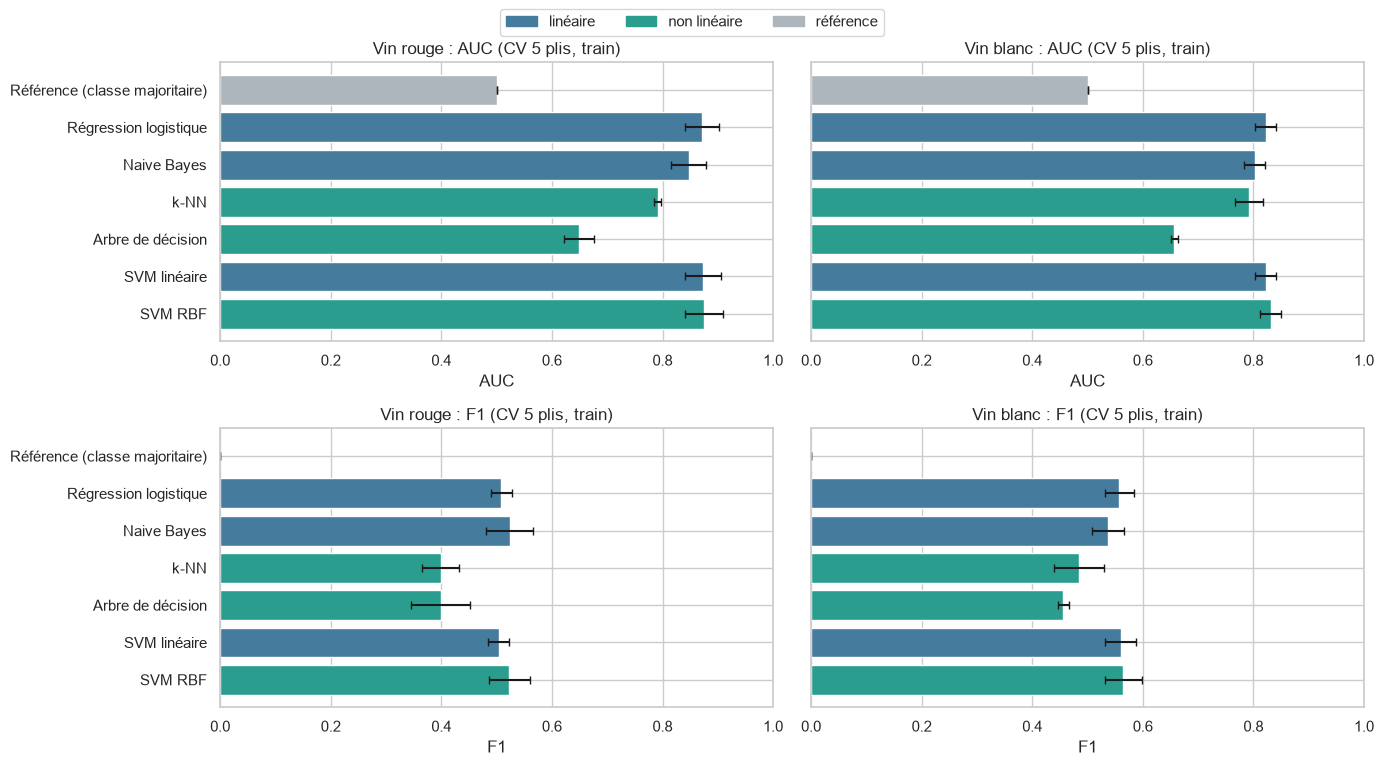

In [34]:
LINEAR = {"Régression logistique", "Naive Bayes", "SVM linéaire"}
COLORS = {"linéaire": "#457b9d", "non linéaire": "#2a9d8f", "référence": "#adb5bd"}


def family(name):
    if name.startswith("Référence"):
        return "référence"
    return "linéaire" if name in LINEAR else "non linéaire"


fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
for j, k in enumerate(KINDS):
    b = baseline[baseline["vin"] == LABELS[k]].set_index("modèle")
    for i, m in enumerate(["AUC", "F1"]):
        ax = axes[i, j]
        ax.barh(b.index, b[m], xerr=b[f"{m} std"], capsize=3, color=[COLORS[family(n)] for n in b.index])
        ax.invert_yaxis()
        ax.set(title=f"{LABELS[k]} : {m} (CV 5 plis, train)", xlabel=m, xlim=(0, 1))
        if j == 1:
            ax.set_yticklabels([])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]
fig.legend(handles, COLORS.keys(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
savefig(fig, "baseline_models")

**Lecture :**
- **Tous les modèles battent la référence** (AUC 0,5, F1 0). L'accuracy confirme qu'elle est trompeuse : la référence a la meilleure accuracy (86,5 % en rouge, 79,2 % en blanc) sans détecter un seul bon vin.
- **Les modèles linéaires sont déjà très bons :** régression logistique et SVM linéaire atteignent une AUC ≈ 0,87 (rouge) et 0,82 (blanc). Le SVM RBF fait à peine mieux (0,875 et 0,831), avec un écart inférieur à l'écart-type entre plis (0,02-0,03). Le signal est donc en grande partie **linéaire et monotone** (plus d'alcool, moins d'acidité volatile…), ce qui est cohérent avec les corrélations de la section 9.
- **Naive Bayes** est un peu en dessous en AUC (0,85 / 0,80), comme attendu avec des variables corrélées, mais il a le meilleur F1 en rouge (0,52) grâce à une précision plus élevée.
- **k-NN et arbre, avec les réglages par défaut, sont les plus faibles** (k-NN : AUC ≈ 0,79 ; arbre : ≈ 0,65). Ce n'est pas une limite de ces familles mais des valeurs par défaut inadaptées (k = 5, arbre sans limite de profondeur) : la section 18 le montre.
- **Rappel / précision :** les modèles avec `class_weight="balanced"` privilégient le rappel (≈ 0,8) au prix de la précision (≈ 0,37-0,44) ; k-NN et Naive Bayes, sans pondération, font l'inverse. Ce compromis se réglera avec le seuil de décision.
- **Coût :** tous les modèles s'entraînent en moins de 12 ms par pli, sauf le SVM RBF sur le blanc (≈ 65 ms, complexité quadratique en n). Le temps n'est donc pas un critère discriminant ici ; il ne compte que pour la taille des grilles de recherche (2.4).

## 18. Compromis biais / variance : courbes de validation

Pour les deux modèles non linéaires dont la complexité tient en un seul paramètre, on trace l'AUC sur le train et en validation croisée (train uniquement) :
- **k-NN** selon k : k petit, frontière très locale (variance élevée) ; k grand, frontière lissée (biais élevé) ;
- **arbre** selon la profondeur maximale : arbre profond, mémorisation du train (variance) ; arbre peu profond, règles trop grossières (biais).

L'écart entre les deux courbes mesure le surapprentissage.

meilleure valeur  AUC validation  AUC train
vin       modèle                                                        
Vin rouge k-NN                           25.0           0.858      0.890
          Arbre de décision               3.0           0.805      0.876
Vin blanc k-NN                           31.0           0.824      0.851
          Arbre de décision               3.0           0.786      0.804

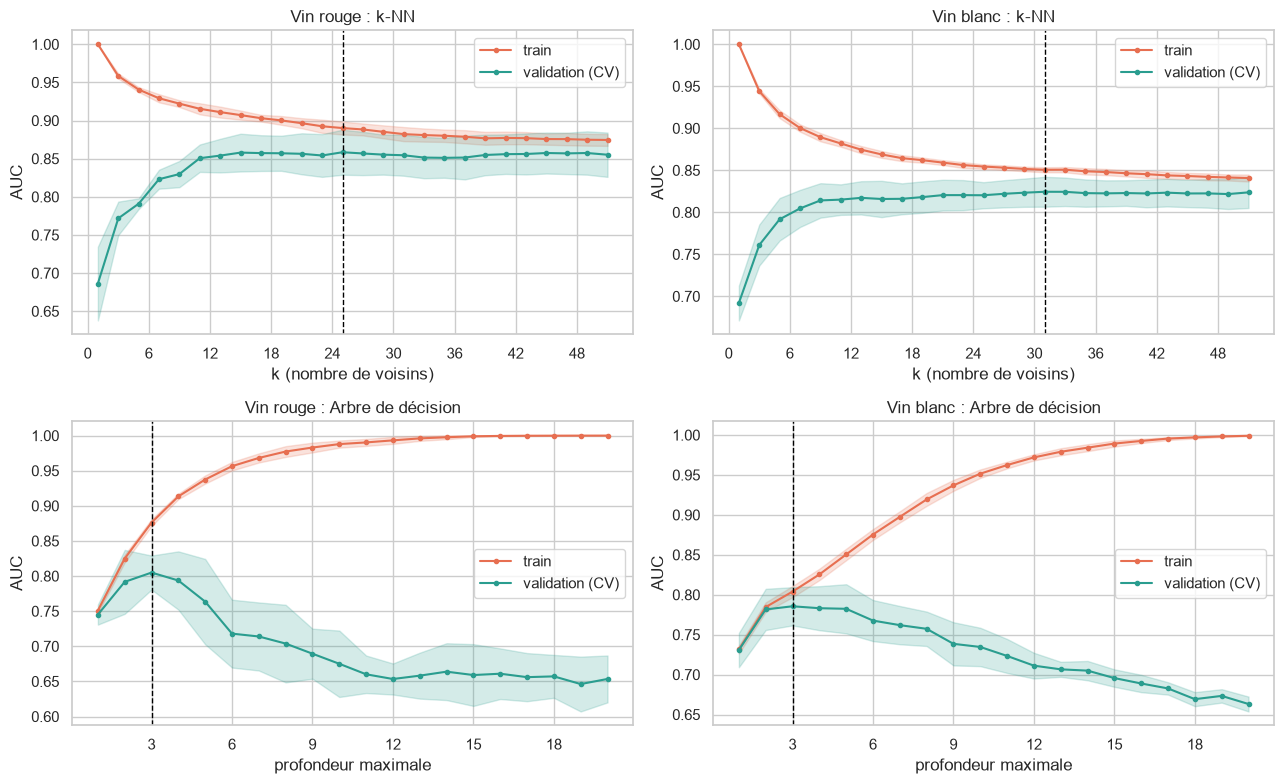

In [35]:
CURVES = {
    "k-NN": ("model__n_neighbors", list(range(1, 52, 2)), "k (nombre de voisins)"),
    "Arbre de décision": ("model__max_depth", list(range(1, 21)), "profondeur maximale"),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
curve_best = {}
for j, k in enumerate(KINDS):
    X_tr, _, y_tr, _ = splits[k]
    models = make_models(k)
    for i, (name, (param, values, label)) in enumerate(CURVES.items()):
        tr, va = validation_curve(models[name], X_tr, y_tr, param_name=param, param_range=values,
                                  cv=CV, scoring="roc_auc", n_jobs=-1)
        ax = axes[i, j]
        for scores, lab, color in [(tr, "train", "#e76f51"), (va, "validation (CV)", "#2a9d8f")]:
            m, s = scores.mean(axis=1), scores.std(axis=1)
            ax.plot(values, m, marker="o", ms=3, label=lab, color=color)
            ax.fill_between(values, m - s, m + s, alpha=0.2, color=color)
        best = int(va.mean(axis=1).argmax())
        curve_best[(LABELS[k], name)] = {"meilleure valeur": values[best], "AUC validation": va.mean(axis=1)[best],
                                         "AUC train": tr.mean(axis=1)[best]}
        ax.axvline(values[best], ls="--", color="black", lw=1)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.set(title=f"{LABELS[k]} : {name}", xlabel=label, ylabel="AUC")
        ax.legend(loc="best")
fig.tight_layout()
savefig(fig, "validation_curves")
pd.DataFrame(curve_best).T.rename_axis(["vin", "modèle"]).round(3)

**Lecture :**
- **k-NN :** avec k = 1, l'AUC train vaut 1 (chaque vin est son propre voisin) mais l'AUC de validation tombe vers 0,69 : variance maximale. Quand k augmente, les deux courbes se rapprochent ; la validation plafonne à partir de k ≈ 11-15 (meilleur k : 25 en rouge, 31 en blanc, AUC ≈ 0,86 et 0,82). La valeur par défaut k = 5 est donc nettement trop petite.
- **Arbre :** à profondeur 1-2, les scores train et validation sont bas et proches (biais). Le meilleur compromis est atteint à une **profondeur de 3** (AUC ≈ 0,81 en rouge, 0,79 en blanc). Au-delà, l'AUC train monte vers 1 pendant que la validation baisse : l'arbre apprend le bruit du train, ce qui explique le mauvais score de l'arbre non contraint à la section 17.
- Ces valeurs donnent les **plages de recherche** de la section 2.4. Le choix définitif se fera avec les autres hyperparamètres (`weights`, `min_samples_leaf`, `ccp_alpha`).

## 19. Récapitulatif pour l'évaluation et le réglage (sections 2.3 et 2.4)

| Modèle | Constat en 2.2 | Réglage prévu en 2.4 | Recherche |
|---|---|---|---|
| Régression logistique | Parmi les meilleurs, très rapide | `C` (échelle log), L1 / L2 via `l1_ratio`, sélection de variables | Grid Search |
| Naive Bayes | Un peu en dessous des modèles linéaires, meilleur F1 que la LogReg sur le rouge | `var_smoothing`, sélection (filtre de corrélation, `SelectKBest`) | Grid Search |
| k-NN | Médiocre avec k = 5, rattrape les linéaires avec k ≈ 25-31 | `n_neighbors`, `weights`, `p`, scaler (standard / robust, section 13) | Grid Search |
| Arbre de décision | Surapprend sans contrainte ; profondeur 3 bien meilleure | `max_depth`, `min_samples_leaf`, `ccp_alpha` (valeurs issues de `cost_complexity_pruning_path`) | Grid Search |
| SVM linéaire | Équivalent à la LogReg | `C` | Grid Search |
| SVM RBF | Meilleure AUC de peu, le plus lent | `C` × `gamma` (échelle log) | Random Search puis `HalvingRandomSearchCV` |

**Protocole retenu pour la suite :**
1. réglage par validation croisée stratifiée 5 plis **sur le train**, métrique principale **AUC** (indépendante du seuil), F1 en complément ;
2. choix du modèle final sur les scores de validation croisée (moyenne et écart-type ; si les écarts sont inférieurs à un écart-type, préférer le plus simple) ;
3. seuil de décision réglé sur les prédictions de validation croisée ;
4. **une seule** évaluation sur le jeu de test (matrice de confusion, ROC, F1, précision, rappel).

# Partie 2.3 — Évaluation des modèles

Objectif : évaluer les modèles de la section 2.2 avec les métriques demandées (accuracy, précision, rappel, F1, matrice de confusion, courbe ROC et AUC), les comparer et identifier le meilleur compromis biais / variance.

**Le jeu de test n'est toujours pas utilisé.** Conformément au protocole (section 19), il est réservé à une évaluation unique du modèle final, après le réglage des hyperparamètres (2.4). Ici, chaque métrique est calculée sur les **prédictions hors-pli** de la validation croisée stratifiée 5 plis du train : chaque vin du train est prédit une fois, par un modèle qui ne l'a pas vu pendant son apprentissage. Les fonctions écrites ici (`evaluate`, `plot_confusion`, `final_evaluation`) serviront telles quelles pour l'évaluation finale sur le test.

## 20. Prédictions hors-pli et métriques

En plus des métriques demandées, on calcule :
- la **spécificité** (part des mauvais vins bien reconnus) et la **balanced accuracy** (moyenne rappel / spécificité), insensibles au déséquilibre ;
- l'**average precision** (AP, aire sous la courbe précision-rappel) : avec 14 à 21 % de positifs, elle est plus exigeante que l'AUC, dont le plancher est 0,5 alors que celui de l'AP est le taux de positifs.

On ajoute aux six modèles de la section 2.2 un k-NN et un arbre **à la complexité choisie par les courbes de validation** (section 18), pour ne pas juger ces deux familles sur des valeurs par défaut manifestement inadaptées. Ces deux choix ont été faits sur les mêmes plis : leur score est légèrement optimiste.

Les métriques sont calculées sur l'ensemble des prédictions hors-pli regroupées ; elles diffèrent donc un peu des moyennes par pli de la section 17.

In [36]:
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
                             precision_recall_curve, precision_score, recall_score, roc_curve)
from sklearn.model_selection import cross_val_predict, learning_curve


def score_method(pipe):
    """Score continu du modèle : probabilité si disponible, sinon distance à la frontière (SVM)."""
    return "predict_proba" if hasattr(pipe, "predict_proba") else "decision_function"


def oof_predictions(pipe, X, y):
    """Prédictions hors-pli (CV 5 plis sur le train) : classe prédite au seuil par défaut et score continu."""
    method = score_method(pipe)
    score = cross_val_predict(pipe, X, y, cv=CV, method=method, n_jobs=-1)
    if method == "predict_proba":
        score = score[:, 1]
    pred = cross_val_predict(pipe, X, y, cv=CV, n_jobs=-1)
    return pred, score


def evaluate(y, y_pred, y_score):
    """Métriques de classification binaire (classe positive : bon vin)."""
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    return {
        "accuracy": accuracy_score(y, y_pred),
        "précision": precision_score(y, y_pred, zero_division=0),
        "rappel": recall_score(y, y_pred),
        "spécificité": tn / (tn + fp),
        "F1": f1_score(y, y_pred),
        "balanced accuracy": balanced_accuracy_score(y, y_pred),
        "AUC": roc_auc_score(y, y_score),
        "AP": average_precision_score(y, y_score),
        "VP": tp, "FP": fp, "FN": fn, "VN": tn,
    }


def eval_models(kind):
    """Modèles de la section 2.2, plus k-NN et arbre à la complexité retenue en section 18."""
    models = make_models(kind)
    k_best = int(curve_best[(LABELS[kind], "k-NN")]["meilleure valeur"])
    d_best = int(curve_best[(LABELS[kind], "Arbre de décision")]["meilleure valeur"])
    models[f"k-NN (k={k_best})"] = clone(models["k-NN"]).set_params(model__n_neighbors=k_best)
    models[f"Arbre (profondeur {d_best})"] = clone(models["Arbre de décision"]).set_params(model__max_depth=d_best)
    return models


OOF = {}
eval_rows = []
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    for name, pipe in eval_models(k).items():
        pred, score = oof_predictions(pipe, X_tr, y_tr)
        OOF[(k, name)] = (pred, score)
        eval_rows.append({"vin": LABELS[k], "modèle": name, **evaluate(y_tr, pred, score)})
evaluation = pd.DataFrame(eval_rows)
evaluation.set_index(["vin", "modèle"]).round(3)

accuracy  précision  rappel  spécificité     F1  balanced accuracy    AUC     AP   VP   FP   FN  \
vin       modèle                                                                                                                            
Vin rouge Référence (classe majoritaire)     0.865      0.000   0.000        1.000  0.000              0.500  0.496  0.134    0    0  147   
          Régression logistique              0.790      0.372   0.803        0.788  0.509              0.796  0.871  0.485  118  199   29   
          Naive Bayes                        0.842      0.441   0.639        0.873  0.522              0.756  0.849  0.414   94  119   53   
          k-NN                               0.859      0.472   0.347        0.939  0.400              0.643  0.791  0.393   51   57   96   
          Arbre de décision                  0.845      0.418   0.381        0.917  0.399              0.649  0.649  0.243   56   78   91   
          SVM linéaire                       0.785      0.366   0.810        0.781  0.504              0.795  0.872  0.487  119  206   28   
          SVM RBF                            0.810      0.396   0.769        0.817  0.523              0.793  0.873  0.531  113  172   34   
          k-NN (k=25)                        0.869      0.540   0.231        0.969  0.324              0.600  0.857  0.464   34   29  113   
          Arbre (profondeur 3)               0.753      0.332   0.823        0.741  0.474              0.782  0.808  0.371  121  243   26   
Vin blanc Référence (classe majoritaire)     0.792      0.000   0.000        1.000  0.000              0.500  0.500  0.208    0    0  660   
          Régression logistique              0.740      0.431   0.786        0.727  0.557              0.757  0.821  0.527  519  684  141   
          Naive Bayes                        0.764      0.454   0.658        0.791  0.537              0.725  0.803  0.504  434  523  226   
          k-NN                               0.808      0.551   0.430        0.908  0.483              0.669  0.792  0.467  284  231  376   
          Arbre de décision                  0.774      0.457   0.456        0.857  0.456              0.657  0.657  0.322  301  358  359   
          SVM linéaire                       0.738      0.431   0.797        0.723  0.559              0.760  0.821  0.530  526  695  134   
          SVM RBF                            0.744      0.437   0.795        0.730  0.564              0.763  0.831  0.514  525  676  135   
          k-NN (k=31)                        0.823      0.651   0.323        0.955  0.432              0.639  0.824  0.530  213  114  447   
          Arbre (profondeur 3)               0.698      0.389   0.788        0.674  0.521              0.731  0.788  0.437  520  818  140   

                                            VN  
vin       modèle                                
Vin rouge Référence (classe majoritaire)   940  
          Régression logistique            741  
          Naive Bayes                      821  
          k-NN                             883  
          Arbre de décision                862  
          SVM linéaire                     734  
          SVM RBF                          768  
          k-NN (k=25)                      911  
          Arbre (profondeur 3)             697  
Vin blanc Référence (classe majoritaire)  2508  
          Régression logistique           1824  
          Naive Bayes                     1985  
          k-NN                            2277  
          Arbre de décision               2150  
          SVM linéaire                    1813  
          SVM RBF                         1832  
          k-NN (k=31)                     2394  
          Arbre (profondeur 3)            1690

**Lecture :**
- La **référence** a la meilleure accuracy (86,5 % en rouge, 79,2 % en blanc) sans trouver un seul bon vin (rappel 0, F1 0) : l'accuracy n'est pas une métrique pertinente ici. Son AUC hors-pli (0,496 en rouge) n'est pas exactement 0,5 car la probabilité constante qu'elle prédit varie un peu d'un pli à l'autre.
- Trois modèles se détachent : **régression logistique, SVM linéaire et SVM RBF** (AUC ≈ 0,87 en rouge, 0,82-0,83 en blanc ; F1 ≈ 0,50-0,52 en rouge, 0,56 en blanc). Suivent le k-NN réglé (AUC 0,857 / 0,824) et Naive Bayes (0,849 / 0,803).
- Avec la complexité choisie en section 18, le **k-NN** (0,79 → 0,86 en rouge) et l'**arbre** (0,65 → 0,81) progressent nettement : leurs mauvais scores en 2.2 venaient bien des réglages par défaut.
- Le k-NN réglé montre l'écart entre **AUC** et **F1** : il classe bien les vins (AUC 0,857) mais, sans pondération des classes, il ne prédit « bon » que si la majorité de ses 25 voisins l'est. Résultat : rappel 0,23 et F1 0,32 au seuil par défaut. Le classement est bon, le seuil est mauvais.

## 21. Matrices de confusion

Chaque case donne le nombre de vins et, entre parenthèses, le pourcentage de la **ligne** (classe réelle) : la case en bas à droite est donc le rappel, celle en haut à gauche la spécificité.

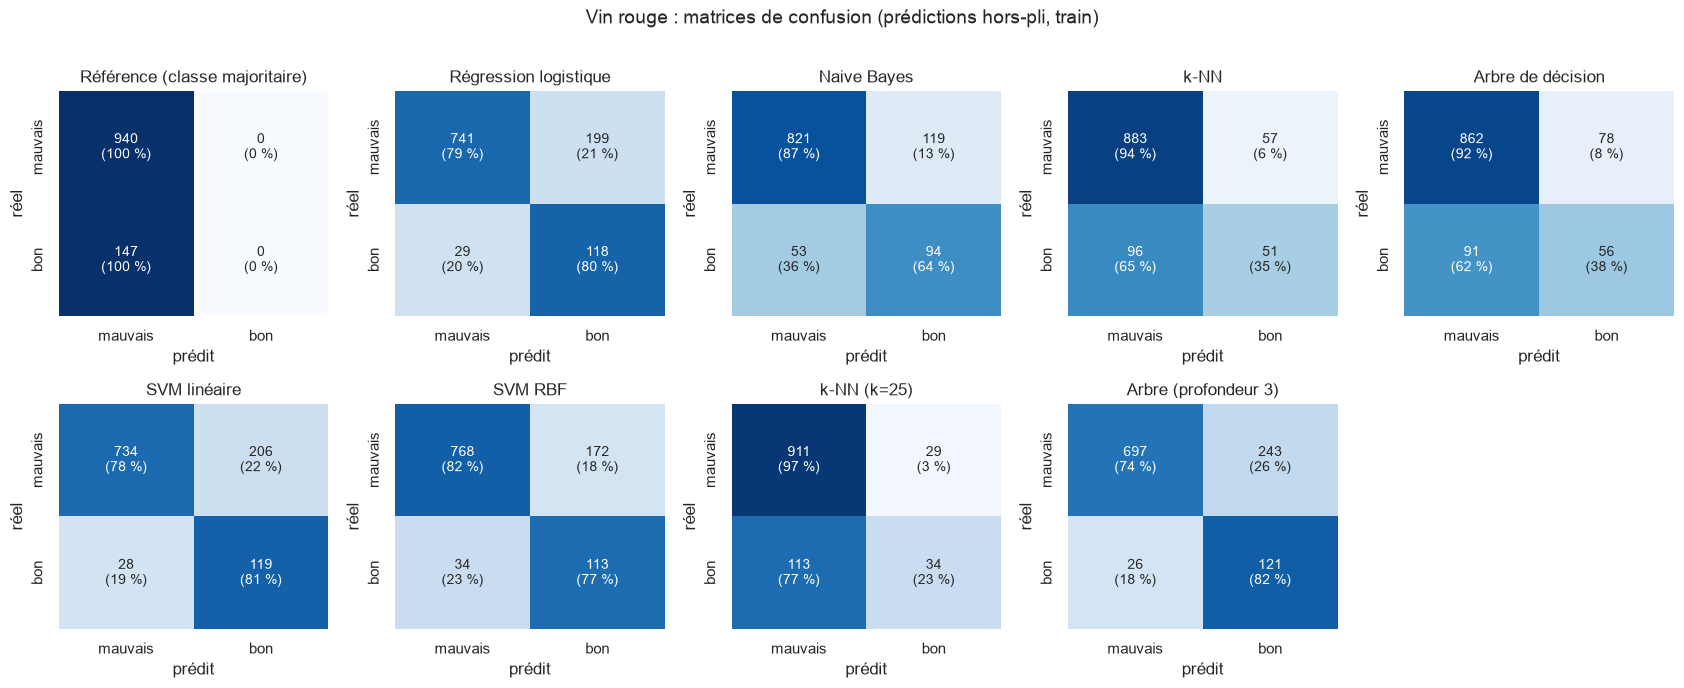

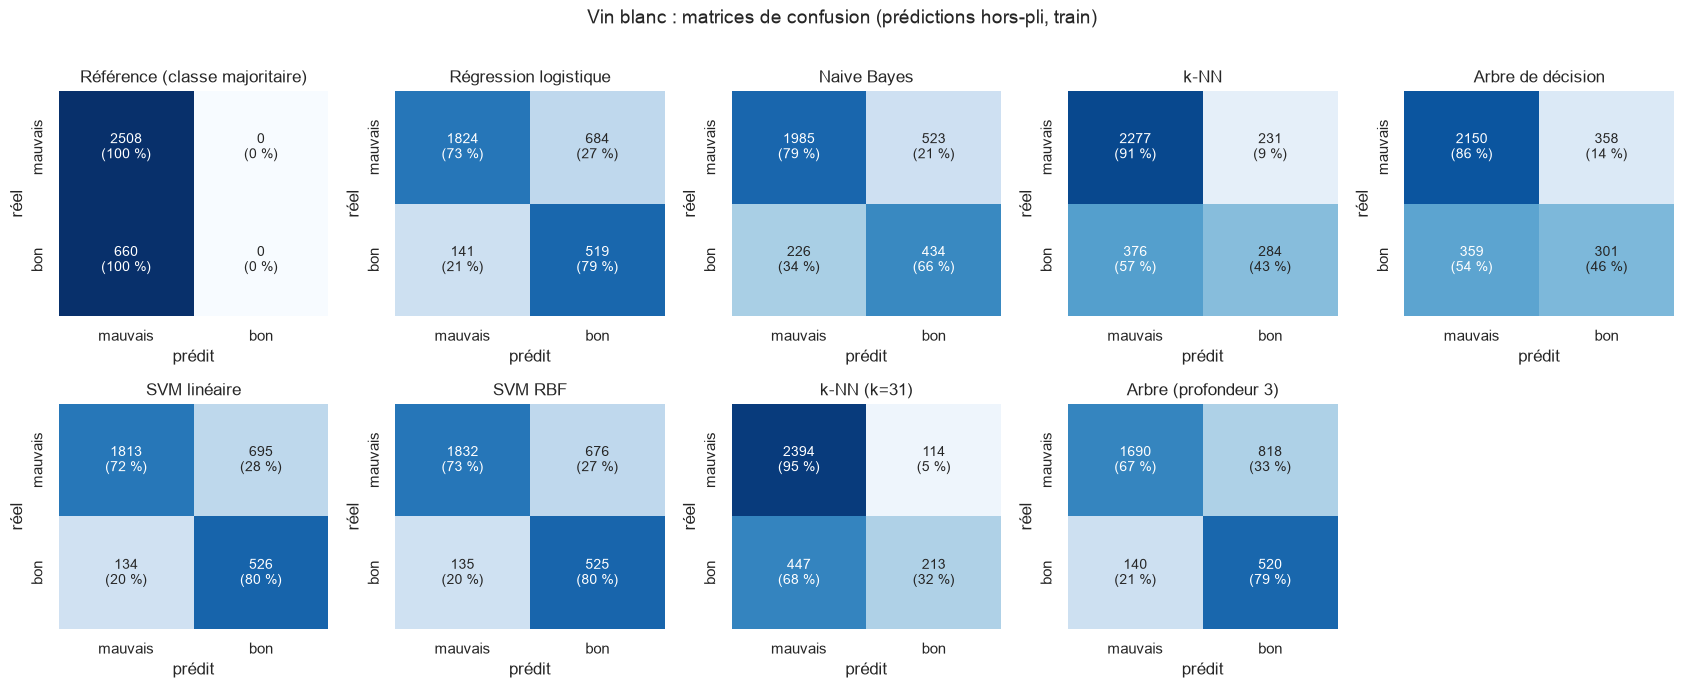

In [37]:
def plot_confusion(ax, y, y_pred, title):
    """Matrice de confusion : effectifs et pourcentage par classe réelle."""
    cm = confusion_matrix(y, y_pred)
    pct = 100 * cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{n}\n({p:.0f} %)" for n, p in zip(rn, rp)] for rn, rp in zip(cm, pct)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                xticklabels=["mauvais", "bon"], yticklabels=["mauvais", "bon"], annot_kws={"size": 10})
    ax.set(title=title, xlabel="prédit", ylabel="réel")


for k in KINDS:
    y_tr = splits[k][2]
    names = [n for (kk, n) in OOF if kk == k]
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.8))
    for ax, name in zip(axes.flat, names):
        plot_confusion(ax, y_tr, OOF[(k, name)][0], name)
    for ax in axes.flat[len(names):]:
        ax.axis("off")
    fig.suptitle(f"{LABELS[k]} : matrices de confusion (prédictions hors-pli, train)", y=1.01, fontsize=14)
    fig.tight_layout()
    savefig(fig, f"confusion_matrices_{k}")

**Lecture :**
- Les modèles avec `class_weight="balanced"` (régression logistique, SVM, arbre) trouvent environ **4 bons vins sur 5** (rappel 0,77-0,82), au prix de nombreux faux positifs : en rouge, la régression logistique annonce 199 faux bons vins pour 118 vrais (précision 0,37) ; en blanc, 684 pour 519 (précision 0,43).
- k-NN et Naive Bayes, non pondérés, font l'inverse : ils reconnaissent 87 à 97 % des mauvais vins mais manquent beaucoup de bons vins (rappel 0,23 à 0,66).
- Le bon point de fonctionnement dépend du coût des erreurs : un **faux positif** est un vin médiocre présenté comme bon, un **faux négatif** un bon vin non repéré. Le sujet ne fixe pas ces coûts : on vise l'équilibre (F1) et on règle le seuil en section 25.

## 22. Courbes ROC et AUC

La courbe ROC trace le taux de vrais positifs (rappel) contre le taux de faux positifs (1 − spécificité) pour **tous les seuils** : l'AUC mesure la capacité à classer un bon vin avant un mauvais, indépendamment du seuil. La référence (classe majoritaire) correspond à la diagonale (AUC = 0,5).

En complément, les courbes **précision-rappel** : quand les positifs sont rares, une petite hausse du taux de faux positifs représente beaucoup de fausses alertes, ce que la ROC montre mal. La ligne horizontale est le taux de positifs (plancher d'un classement aléatoire).

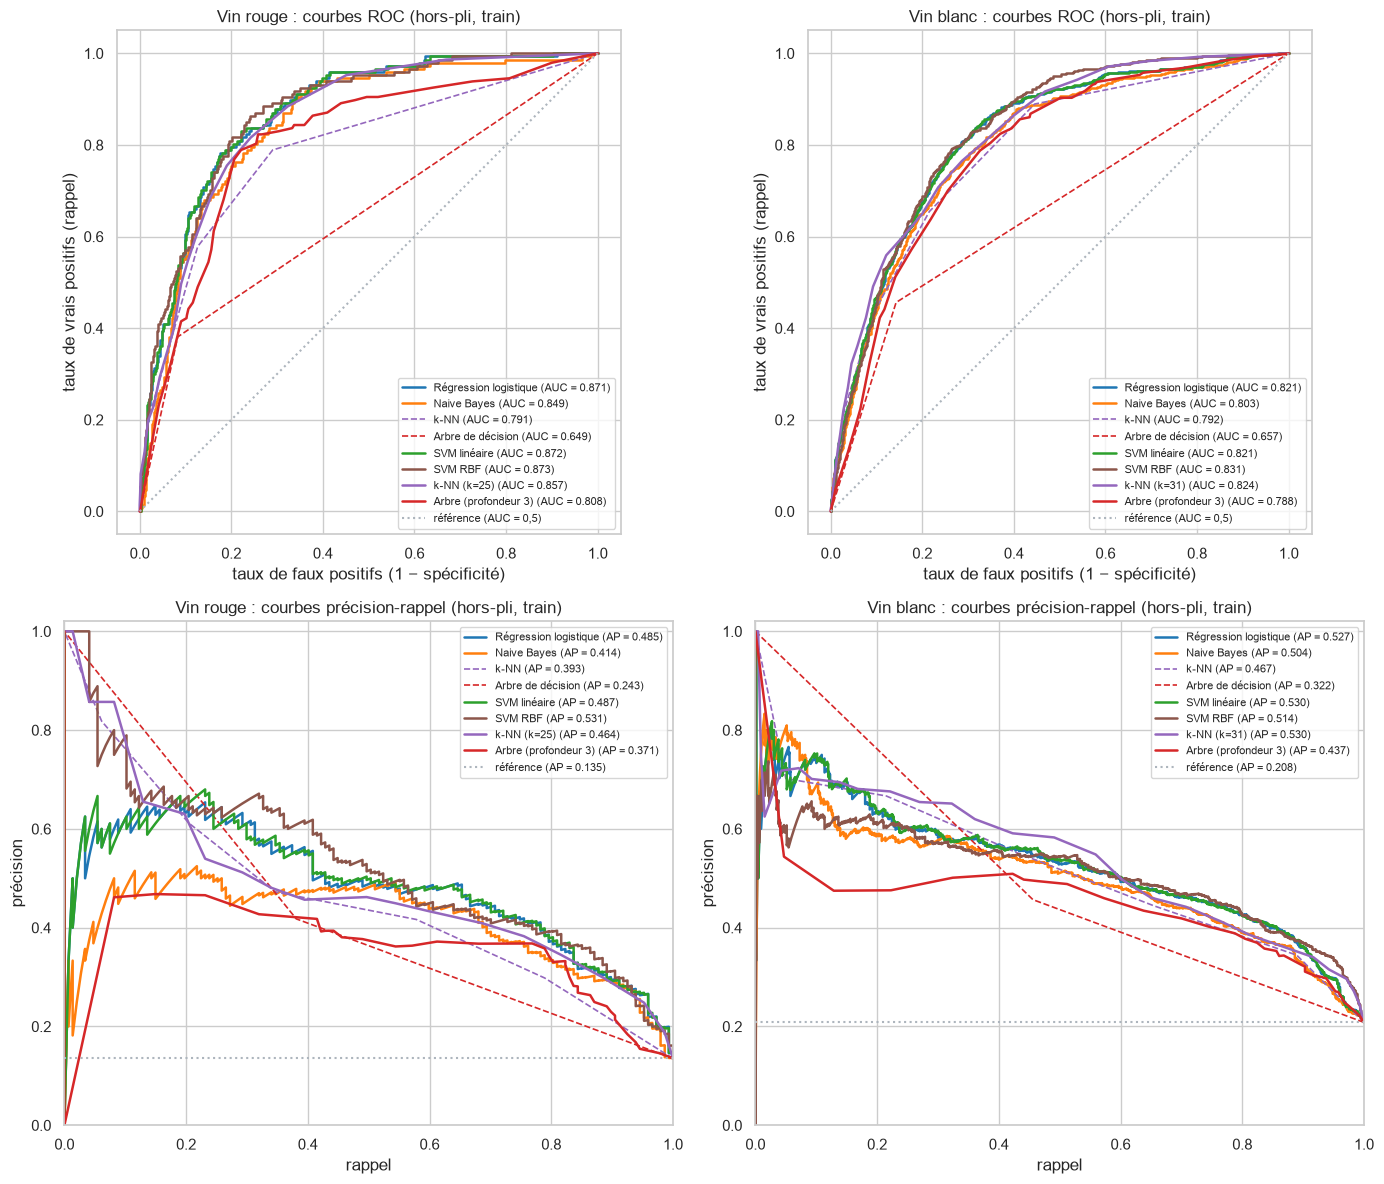

In [38]:
# familles de modèles, de la plus simple à la plus complexe (ordre réutilisé en section 25)
MODEL_FAMILIES = ["Régression logistique", "Naive Bayes", "SVM linéaire", "Arbre", "k-NN", "SVM RBF"]
FAMILY_COLORS = dict(zip(MODEL_FAMILIES, sns.color_palette("tab10")))


def model_family(name):
    return next(f for f in MODEL_FAMILIES if name.startswith(f))


def curve_style(name):
    """Une couleur par famille ; tirets pour les versions par défaut de k-NN et de l'arbre."""
    dashed = name in ("k-NN", "Arbre de décision")
    return {"color": FAMILY_COLORS[model_family(name)], "ls": "--" if dashed else "-", "lw": 1.2 if dashed else 1.8}


FAMILY_MARKERS = dict(zip(MODEL_FAMILIES, ["o", "s", "D", "v", "^", "P"]))


def point_style(name):
    """Une couleur et un marqueur par famille ; marqueur creux pour les versions par défaut de k-NN et de l'arbre."""
    color = FAMILY_COLORS[model_family(name)]
    hollow = name in ("k-NN", "Arbre de décision")
    return {"color": color, "marker": FAMILY_MARKERS[model_family(name)], "ms": 8, "ls": "",
            "mfc": "white" if hollow else color, "mec": color, "mew": 1.6}


fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for j, k in enumerate(KINDS):
    y_tr = splits[k][2]
    names = [n for (kk, n) in OOF if kk == k and not n.startswith("Référence")]
    ax_roc, ax_pr = axes[0, j], axes[1, j]
    for name in names:
        score = OOF[(k, name)][1]
        fpr, tpr, _ = roc_curve(y_tr, score)
        ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_tr, score):.3f})", **curve_style(name))
        prec, rec, _ = precision_recall_curve(y_tr, score)
        ax_pr.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_tr, score):.3f})", **curve_style(name))
    ax_roc.plot([0, 1], [0, 1], color="#adb5bd", ls=":", label="référence (AUC = 0,5)")
    ax_pr.axhline(y_tr.mean(), color="#adb5bd", ls=":", label=f"référence (AP = {y_tr.mean():.3f})")
    ax_roc.set(title=f"{LABELS[k]} : courbes ROC (hors-pli, train)", xlabel="taux de faux positifs (1 − spécificité)",
               ylabel="taux de vrais positifs (rappel)", aspect="equal")
    ax_pr.set(title=f"{LABELS[k]} : courbes précision-rappel (hors-pli, train)", xlabel="rappel",
              ylabel="précision", xlim=(0, 1), ylim=(0, 1.02))
    ax_roc.legend(loc="lower right", fontsize=8)
    ax_pr.legend(loc="upper right", fontsize=8)
fig.tight_layout()
savefig(fig, "roc_pr_curves")

**Lecture :**
- **ROC :** les courbes de la régression logistique, des deux SVM et du k-NN réglé se superposent presque partout ; les AUC ne diffèrent que de quelques millièmes. L'arbre par défaut a une « courbe » en deux segments : ses feuilles sont pures, il ne produit presque que des probabilités 0 ou 1, donc un seul point de fonctionnement. L'arbre de profondeur 3 n'a que 8 feuilles, d'où sa courbe en escalier.
- **Précision-rappel :** plus discriminante. En rouge, le SVM RBF a la meilleure AP (0,531 contre 0,485 pour la régression logistique), grâce aux vins classés les plus sûrs (zone de faible rappel). En blanc, l'ordre s'inverse : régression logistique, SVM linéaire et k-NN réglé (≈ 0,53) devancent le SVM RBF (0,514). Le classement des meilleurs modèles dépend donc de la métrique, signe que leurs écarts sont faibles.
- Pour retrouver 80 % des bons vins, la précision tombe vers 0,35 en rouge et 0,42 en blanc pour tous les modèles : plus de la moitié des vins annoncés bons ne le sont pas. C'est la limite de la frontière floue entre les notes 6 et 7 (section 4), pas d'un modèle en particulier.

## 23. Comparaison des modèles

Les écarts entre les meilleurs modèles sont petits : il faut savoir s'ils dépassent le bruit de la validation croisée. Tous les modèles étant évalués sur **les mêmes plis**, on compare l'AUC pli par pli au meilleur modèle : l'écart moyen est rapporté à l'écart-type de ces différences appariées. Un rapport inférieur à 1 signifie que l'écart n'est pas distinguable du bruit.

On récupère au passage l'AUC sur les plis d'apprentissage, utilisée à la section 24.

In [39]:
fold_rows = []
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    for name, pipe in eval_models(k).items():
        res = cross_validate(pipe, X_tr, y_tr, cv=CV, scoring=["roc_auc", "f1"], return_train_score=True, n_jobs=-1)
        for i in range(CV.get_n_splits()):
            fold_rows.append({"vin": LABELS[k], "modèle": name, "pli": i,
                              "AUC train": res["train_roc_auc"][i], "AUC validation": res["test_roc_auc"][i],
                              "F1 train": res["train_f1"][i], "F1 validation": res["test_f1"][i]})
folds = pd.DataFrame(fold_rows)

comparison_rows = []
for vin, grp in folds.groupby("vin", sort=False):
    auc = grp.pivot(index="pli", columns="modèle", values="AUC validation")
    best = auc.mean().idxmax()
    for name in auc.columns:
        diff = auc[best] - auc[name]
        comparison_rows.append({"vin": vin, "modèle": name, "AUC": auc[name].mean(), "AUC std": auc[name].std(ddof=0),
                                "écart au meilleur": diff.mean(),
                                "écart / std(écart)": diff.mean() / diff.std(ddof=0) if name != best else 0.0,
                                "plis gagnés par le meilleur": int((diff > 0).sum())})
comparison = (pd.DataFrame(comparison_rows)
              .merge(evaluation[["vin", "modèle", "F1", "rappel", "précision", "AP"]], on=["vin", "modèle"])
              .sort_values(["vin", "AUC"], ascending=[False, False]))
comparison.set_index(["vin", "modèle"]).round(3)

AUC  AUC std  écart au meilleur  écart / std(écart)  plis gagnés par le meilleur     F1  \
vin       modèle                                                                                                                      
Vin rouge SVM RBF                         0.875    0.035              0.000               0.000                            0  0.523   
          SVM linéaire                    0.873    0.032              0.002               0.093                            2  0.504   
          Régression logistique           0.872    0.031              0.003               0.190                            2  0.509   
          k-NN (k=25)                     0.858    0.030              0.016               1.102                            5  0.324   
          Naive Bayes                     0.848    0.032              0.027               1.344                            5  0.522   
          Arbre (profondeur 3)            0.805    0.024              0.070               4.743                            5  0.474   
          k-NN                            0.791    0.007              0.084               2.364                            5  0.400   
          Arbre de décision               0.649    0.028              0.226               7.962                            5  0.399   
          Référence (classe majoritaire)  0.500    0.000              0.375              10.734                            5  0.000   
Vin blanc SVM RBF                         0.831    0.019              0.000               0.000                            0  0.564   
          k-NN (k=31)                     0.824    0.018              0.007               0.761                            4  0.432   
          SVM linéaire                    0.822    0.019              0.009               1.456                            4  0.559   
          Régression logistique           0.822    0.018              0.009               1.425                            4  0.557   
          Naive Bayes                     0.802    0.019              0.029               4.542                            5  0.537   
          k-NN                            0.792    0.025              0.039               2.649                            5  0.483   
          Arbre (profondeur 3)            0.786    0.024              0.045               2.636                            5  0.521   
          Arbre de décision               0.657    0.007              0.174              12.302                            5  0.456   
          Référence (classe majoritaire)  0.500    0.000              0.331              17.737                            5  0.000   

                                          rappel  précision     AP  
vin       modèle                                                    
Vin rouge SVM RBF                          0.769      0.396  0.531  
          SVM linéaire                     0.810      0.366  0.487  
          Régression logistique            0.803      0.372  0.485  
          k-NN (k=25)                      0.231      0.540  0.464  
          Naive Bayes                      0.639      0.441  0.414  
          Arbre (profondeur 3)             0.823      0.332  0.371  
          k-NN                             0.347      0.472  0.393  
          Arbre de décision                0.381      0.418  0.243  
          Référence (classe majoritaire)   0.000      0.000  0.134  
Vin blanc SVM RBF                          0.795      0.437  0.514  
          k-NN (k=31)                      0.323      0.651  0.530  
          SVM linéaire                     0.797      0.431  0.530  
          Régression logistique            0.786      0.431  0.527  
          Naive Bayes                      0.658      0.454  0.504  
          k-NN                             0.430      0.551  0.467  
          Arbre (profondeur 3)             0.788      0.389  0.437  
          Arbre de décision                0.456      0.457  0.322  
          Référence (classe majo

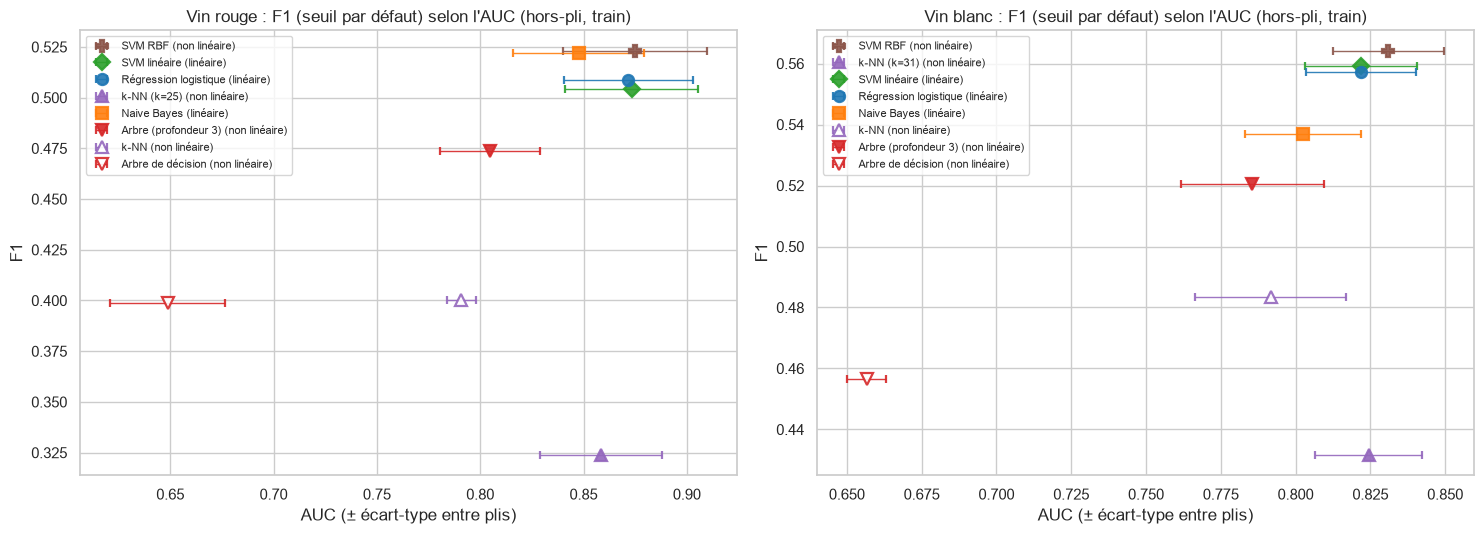

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, k in zip(axes, KINDS):
    c = comparison[(comparison["vin"] == LABELS[k]) & ~comparison["modèle"].str.startswith("Référence")]
    for _, r in c.iterrows():
        ax.errorbar(r["AUC"], r["F1"], xerr=r["AUC std"], capsize=3, elinewidth=1, alpha=0.9,
                    label=f"{r['modèle']} ({family(r['modèle'])})", **point_style(r["modèle"]))
    ax.set(title=f"{LABELS[k]} : F1 (seuil par défaut) selon l'AUC (hors-pli, train)", xlabel="AUC (± écart-type entre plis)",
           ylabel="F1")
    ax.legend(loc="best", fontsize=8)
fig.tight_layout()
savefig(fig, "model_comparison")

**Lecture :**
- **Rouge :** le SVM RBF a la meilleure AUC (0,875), mais le SVM linéaire et la régression logistique sont à 0,002-0,003, avec un rapport écart / écart-type inférieur à 0,2 : le SVM RBF ne gagne que 2 plis sur 5. **Aucune différence** entre ces trois modèles. Le k-NN réglé et Naive Bayes sont un peu en dessous (rapport 1,1-1,3, battus sur les 5 plis).
- **Blanc :** le SVM RBF (0,831) devance régression logistique et SVM linéaire de 0,009, sur 4 plis sur 5 (rapport ≈ 1,4) : un avantage **faible mais régulier**, plus petit que l'écart-type entre plis (0,019). Naive Bayes est nettement en dessous (rapport 4,5).
- **Linéaire contre non linéaire :** le meilleur modèle non linéaire gagne au plus 0,01 d'AUC. Le signal est essentiellement linéaire, comme l'annonçait la section 17.
- Au seuil par défaut, le F1 ne suit pas l'AUC (k-NN réglé : bonne AUC, F1 le plus faible). Comparer des F1 n'a de sens qu'après avoir réglé le seuil de chaque modèle.

## 24. Compromis biais / variance

Pour chaque modèle, trois indicateurs issus de la validation croisée :
- **AUC de validation** : un niveau bas avec un faible écart au train signale un **biais** (modèle trop simple) ;
- **écart train − validation** : un écart fort signale un **surapprentissage** (variance) ;
- **écart-type entre plis** : la sensibilité du score au découpage des données (variance de l'estimation).

Les **courbes d'apprentissage** complètent le diagnostic : elles montrent si ajouter des données réduirait l'écart (variance) ou si les deux courbes plafonnent ensemble (biais).

AUC train  AUC validation  std validation  écart train - validation
vin       modèle                                                                                    
Vin rouge Régression logistique      0.889           0.872           0.031                     0.017
          Naive Bayes                0.873           0.848           0.032                     0.025
          k-NN                       0.941           0.791           0.007                     0.150
          Arbre de décision          1.000           0.649           0.028                     0.351
          SVM linéaire               0.889           0.873           0.032                     0.015
          SVM RBF                    0.948           0.875           0.035                     0.073
          k-NN (k=25)                0.890           0.858           0.030                     0.032
          Arbre (profondeur 3)       0.876           0.805           0.024                     0.071
Vin blanc Régression logistique      0.825           0.822           0.018                     0.003
          Naive Bayes                0.806           0.802           0.019                     0.003
          k-NN                       0.917           0.792           0.025                     0.125
          Arbre de décision          1.000           0.657           0.007                     0.343
          SVM linéaire               0.824           0.822           0.019                     0.003
          SVM RBF                    0.886           0.831           0.019                     0.055
          k-NN (k=31)                0.851           0.824           0.018                     0.026
          Arbre (profondeur 3)       0.804           0.786           0.024                     0.018

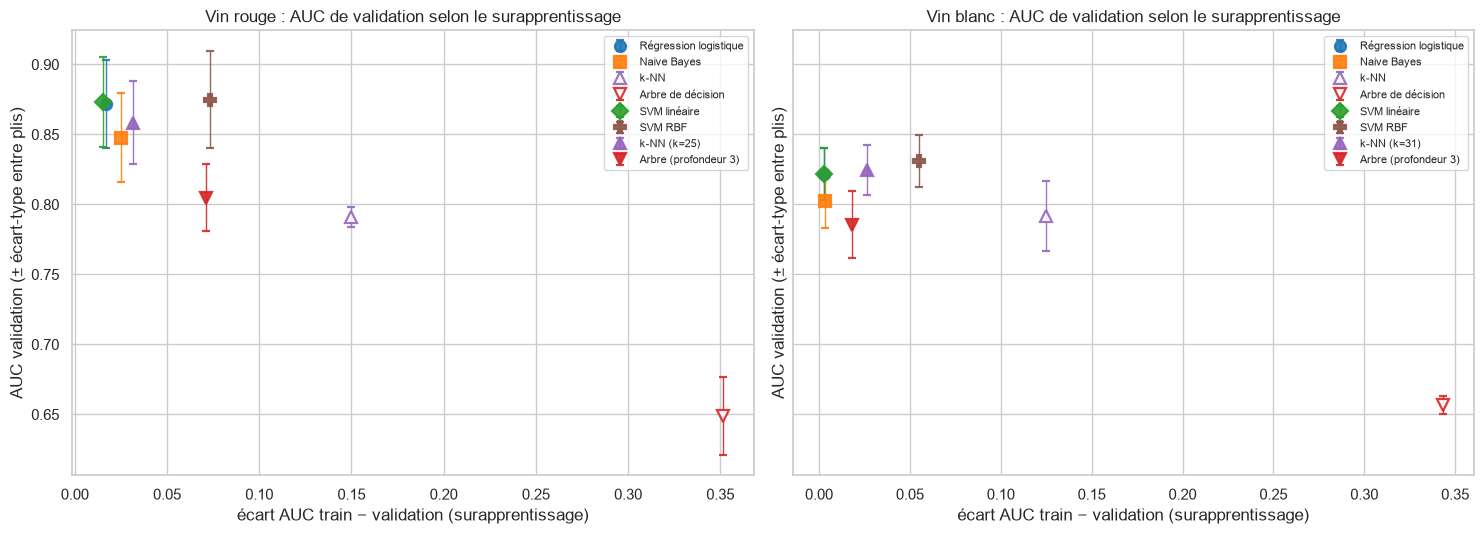

In [41]:
bias_variance = (folds.groupby(["vin", "modèle"], sort=False)
                 .agg(**{"AUC train": ("AUC train", "mean"), "AUC validation": ("AUC validation", "mean"),
                         "std validation": ("AUC validation", lambda s: s.std(ddof=0))})
                 .assign(**{"écart train - validation": lambda d: d["AUC train"] - d["AUC validation"]}))
bias_variance = bias_variance.drop(index=[i for i in bias_variance.index if i[1].startswith("Référence")])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, k in zip(axes, KINDS):
    bv = bias_variance.loc[LABELS[k]]
    for name, r in bv.iterrows():
        ax.errorbar(r["écart train - validation"], r["AUC validation"], yerr=r["std validation"], capsize=3,
                    elinewidth=1, alpha=0.9, label=name, **point_style(name))
    ax.set(title=f"{LABELS[k]} : AUC de validation selon le surapprentissage",
           xlabel="écart AUC train − validation (surapprentissage)", ylabel="AUC validation (± écart-type entre plis)")
    ax.legend(loc="best", fontsize=8)
fig.tight_layout()
savefig(fig, "bias_variance")
bias_variance.round(3)

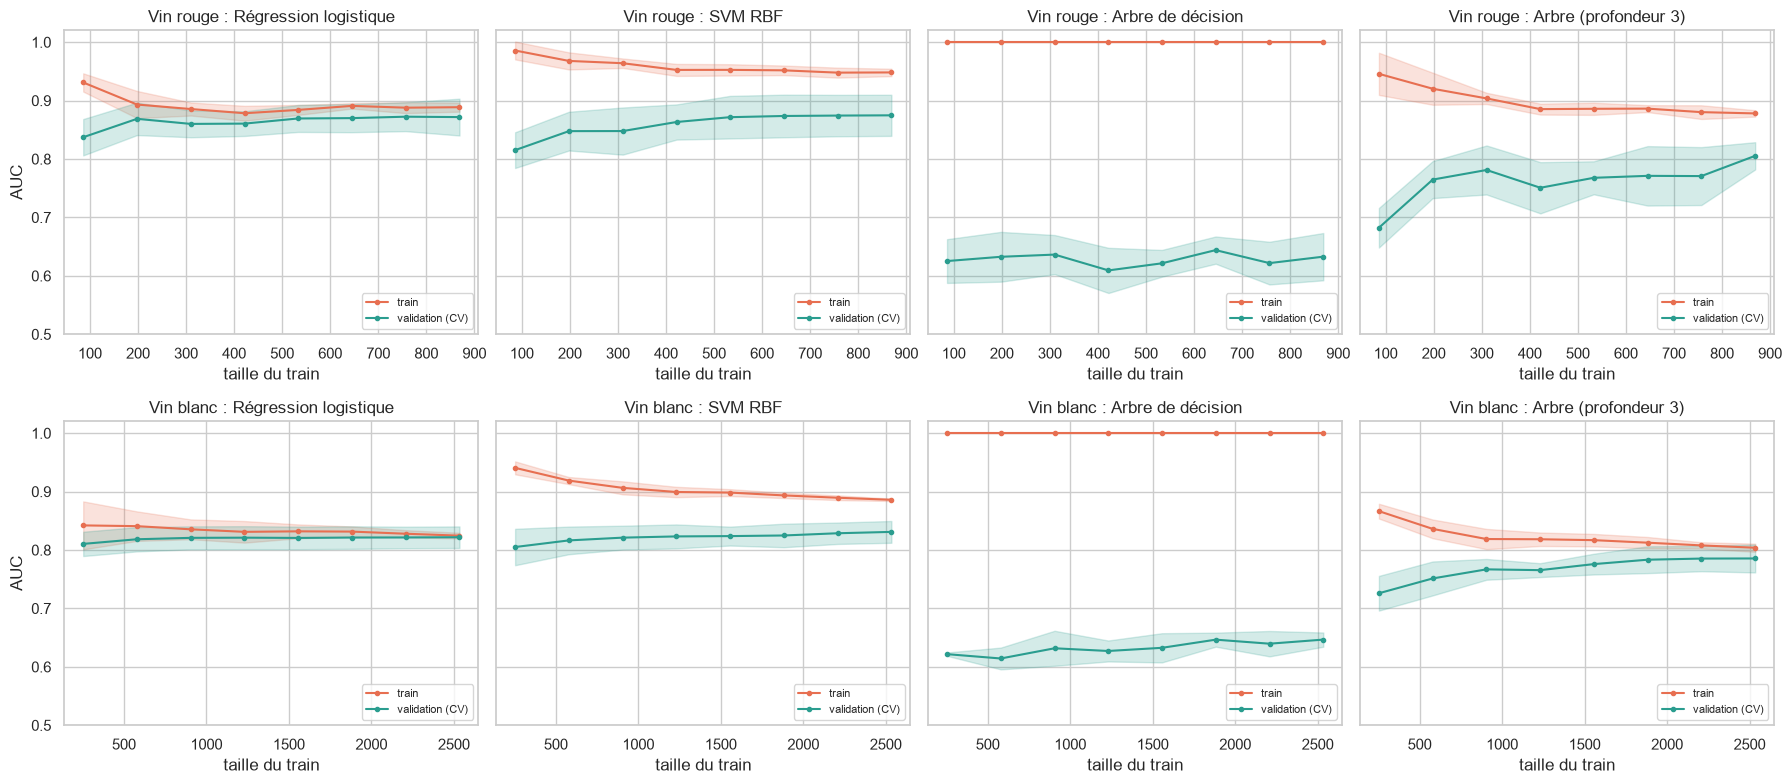

In [42]:
LC_MODELS = ["Régression logistique", "SVM RBF", "Arbre de décision"]
train_sizes = np.linspace(0.1, 1.0, 8)

fig, axes = plt.subplots(2, len(LC_MODELS) + 1, figsize=(18, 8), sharey=True)
for i, k in enumerate(KINDS):
    X_tr, _, y_tr, _ = splits[k]
    models = eval_models(k)
    d_name = next(n for n in models if n.startswith("Arbre ("))
    for j, name in enumerate(LC_MODELS + [d_name]):
        sizes, tr, va = learning_curve(models[name], X_tr, y_tr, train_sizes=train_sizes, cv=CV, scoring="roc_auc",
                                       shuffle=True, random_state=SEED, n_jobs=-1)
        ax = axes[i, j]
        for scores, lab, color in [(tr, "train", "#e76f51"), (va, "validation (CV)", "#2a9d8f")]:
            m, s = scores.mean(axis=1), scores.std(axis=1)
            ax.plot(sizes, m, marker="o", ms=3, label=lab, color=color)
            ax.fill_between(sizes, m - s, m + s, alpha=0.2, color=color)
        ax.set(title=f"{LABELS[k]} : {name}", xlabel="taille du train", ylabel="AUC" if j == 0 else "", ylim=(0.5, 1.02))
        ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
savefig(fig, "learning_curves")

**Lecture :**
- **Arbre par défaut :** AUC 1,00 sur le train contre 0,65 en validation. C'est de la **variance pure** (mémorisation), et sa courbe d'apprentissage reste plate : sans contrainte, plus de données ne l'aideraient pas. Le k-NN à k = 5 surapprend aussi (écart 0,13-0,15).
- **Régression logistique, SVM linéaire, Naive Bayes :** écart train-validation ≤ 0,025 (0,003 en blanc). Il n'y a **pas de surapprentissage** : les courbes d'apprentissage se rejoignent dès quelques centaines de vins puis plafonnent. Leur limite est le **biais** (frontière linéaire) et le bruit d'étiquette ; plus de données n'y changeraient presque rien.
- **SVM RBF :** écart 0,07 (rouge) et 0,055 (blanc), et sa courbe de validation monte encore légèrement. Un peu de variance, en échange d'un gain d'AUC non significatif ; le réglage de `C` et `gamma` (2.4) peut améliorer ce compromis.
- **Arbre de profondeur 3 :** en blanc, faible écart (0,018) mais AUC limitée à 0,79 : 8 feuilles, c'est trop grossier (**biais**). En rouge, l'écart reste de 0,07 et la validation progresse avec la taille du train : le jeu rouge est petit pour un arbre.
- **Variance de l'estimation :** l'écart-type entre plis vaut ≈ 0,03 en rouge contre ≈ 0,02 en blanc. Le test rouge (272 vins, 37 positifs) donnera donc une AUC finale incertaine d'au moins ± 0,03.
- **Meilleur compromis :** régression logistique et SVM linéaire, qui atteignent le niveau du meilleur modèle avec la variance la plus faible.

## 25. Seuil de décision

Le seuil par défaut (probabilité 0,5, ou distance 0 pour un SVM) n'a rien d'optimal avec des classes déséquilibrées et `class_weight="balanced"`. Comme prévu au protocole (section 19, point 3), on le choisit sur les **prédictions hors-pli du train**, jamais sur le test : on retient le seuil qui maximise le F1.

On l'applique au modèle retenu par la règle du protocole : **meilleure AUC moyenne, et parmi les modèles à moins d'un écart-type de celle-ci, le plus simple**. Ordre de simplicité : régression logistique, Naive Bayes, SVM linéaire, arbre, k-NN, SVM RBF (interprétabilité, nombre de paramètres, coût de prédiction).

Vin rouge : modèles à moins d'un écart-type du meilleur = ['SVM RBF', 'SVM linéaire', 'Régression logistique', 'k-NN (k=25)', 'Naive Bayes'] -> retenu : Régression logistique
Vin blanc : modèles à moins d'un écart-type du meilleur = ['SVM RBF', 'k-NN (k=31)', 'SVM linéaire', 'Régression logistique'] -> retenu : Régression logistique


accuracy  précision  rappel     F1  balanced accuracy   VP   FP   FN
vin       modèle                seuil                                                                              
Vin rouge Régression logistique défaut (0.5)      0.790      0.372   0.803  0.509              0.796  118  199   29
                                F1 max (0.73)     0.860      0.487   0.653  0.558              0.773   96  101   51
Vin blanc Régression logistique défaut (0.5)      0.740      0.431   0.786  0.557              0.757  519  684  141
                                F1 max (0.52)     0.753      0.446   0.771  0.565              0.760  509  632  151

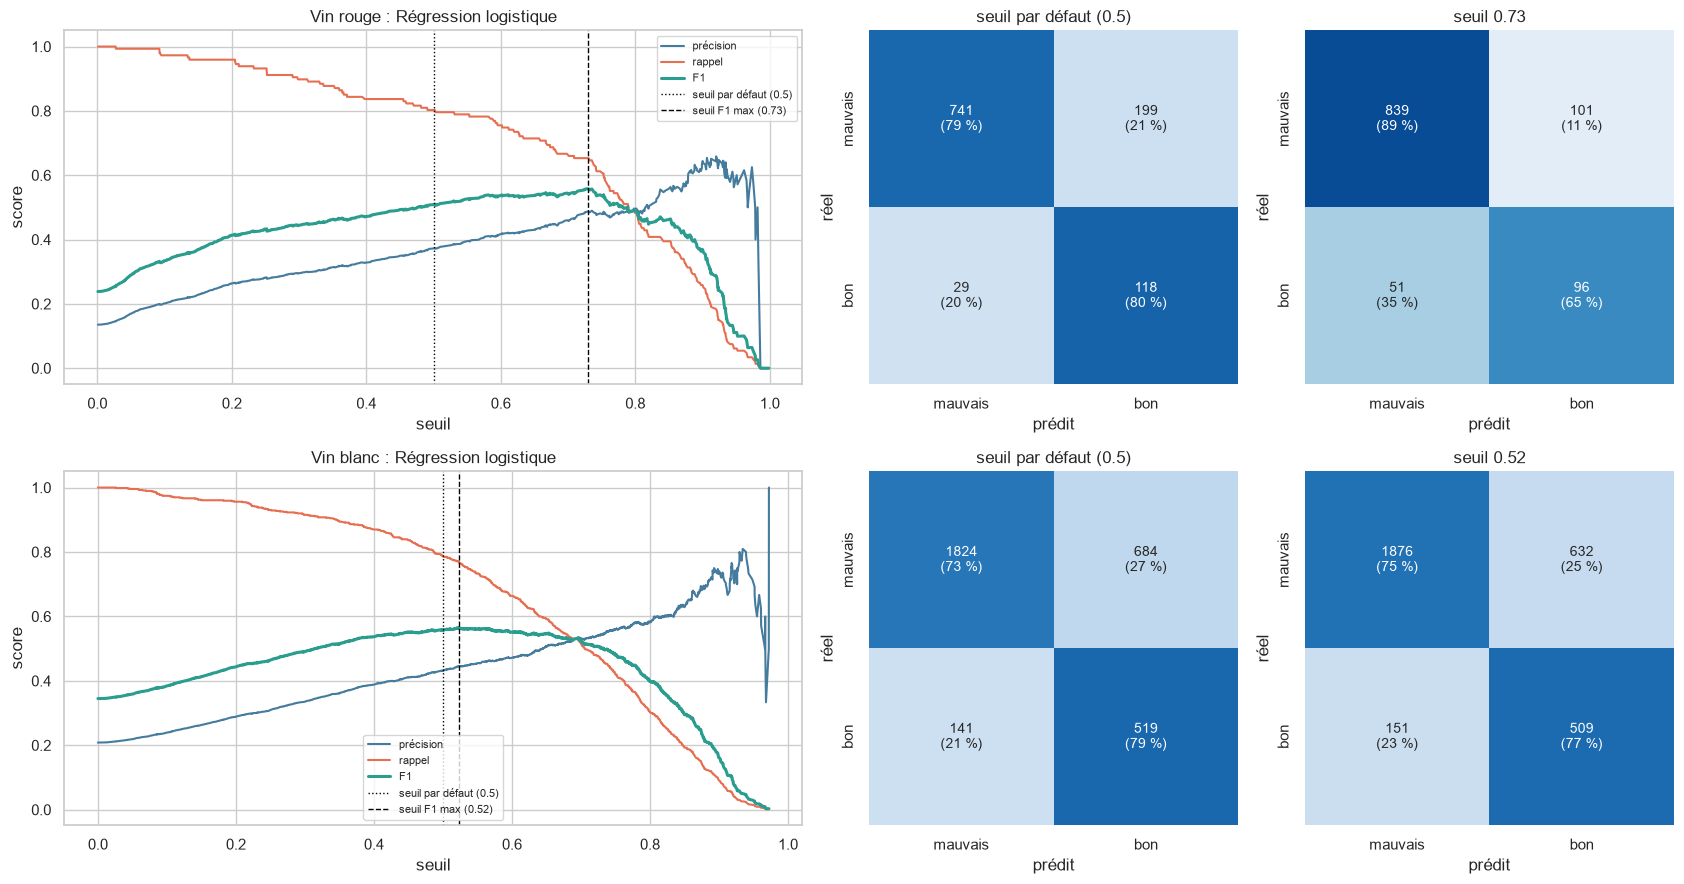

In [43]:
def select_model(comp):
    """Meilleure AUC ; parmi les modèles à moins d'un écart-type (du meilleur), le plus simple."""
    comp = comp[~comp["modèle"].str.startswith("Référence")]
    best = comp.loc[comp["AUC"].idxmax()]
    candidates = comp[comp["AUC"] >= best["AUC"] - best["AUC std"]]
    return min(candidates["modèle"], key=lambda n: MODEL_FAMILIES.index(model_family(n))), list(candidates["modèle"])


def best_f1_threshold(y, score):
    """Seuil maximisant le F1 sur des prédictions hors-pli."""
    prec, rec, thr = precision_recall_curve(y, score)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return thr[f1.argmax()], prec[:-1], rec[:-1], f1, thr


SELECTED, THRESHOLD = {}, {}
threshold_rows = []
fig, axes = plt.subplots(2, 3, figsize=(17, 9), gridspec_kw={"width_ratios": [2, 1, 1]})
for i, k in enumerate(KINDS):
    y_tr = splits[k][2]
    name, candidates = select_model(comparison[comparison["vin"] == LABELS[k]])
    SELECTED[k] = name
    pred, score = OOF[(k, name)]
    t_best, prec, rec, f1, thr = best_f1_threshold(y_tr, score)
    THRESHOLD[k] = t_best
    pred_best = (score >= t_best).astype(int)
    default_t = 0.5 if score_method(eval_models(k)[name]) == "predict_proba" else 0.0

    ax = axes[i, 0]
    ax.plot(thr, prec, label="précision", color="#457b9d")
    ax.plot(thr, rec, label="rappel", color="#e76f51")
    ax.plot(thr, f1, label="F1", color="#2a9d8f", lw=2.2)
    ax.axvline(default_t, color="black", ls=":", lw=1, label=f"seuil par défaut ({default_t:g})")
    ax.axvline(t_best, color="black", ls="--", lw=1, label=f"seuil F1 max ({t_best:.2f})")
    ax.set(title=f"{LABELS[k]} : {name}", xlabel="seuil", ylabel="score")
    ax.legend(fontsize=8)
    plot_confusion(axes[i, 1], y_tr, pred, f"seuil par défaut ({default_t:g})")
    plot_confusion(axes[i, 2], y_tr, pred_best, f"seuil {t_best:.2f}")

    for label, p in [(f"défaut ({default_t:g})", pred), (f"F1 max ({t_best:.2f})", pred_best)]:
        threshold_rows.append({"vin": LABELS[k], "modèle": name, "seuil": label,
                               **{m: v for m, v in evaluate(y_tr, p, score).items()
                                  if m in ("accuracy", "précision", "rappel", "F1", "balanced accuracy", "VP", "FP", "FN")}})
    print(f"{LABELS[k]} : modèles à moins d'un écart-type du meilleur = {candidates} -> retenu : {name}")
fig.tight_layout()
savefig(fig, "decision_threshold")
pd.DataFrame(threshold_rows).set_index(["vin", "modèle", "seuil"]).round(3)

**Lecture :**
- **Rouge :** le seuil optimal est élevé (0,73). Le F1 passe de 0,509 à 0,558 : les faux positifs sont divisés par deux (199 → 101) et la précision monte de 0,37 à 0,49, pour un rappel qui baisse de 0,80 à 0,65. Ce seuil élevé compense `class_weight="balanced"`, qui pousse les probabilités vers la classe rare.
- **Blanc :** le seuil optimal (0,52) est proche du seuil par défaut : le F1 est plat entre 0,4 et 0,65 et le gain est minime (0,557 → 0,565).
- Le seuil est choisi et évalué sur les mêmes prédictions hors-pli : le F1 obtenu est légèrement optimiste. Il sera vérifié une seule fois sur le test. Le seuil devra être **choisi à nouveau après le réglage (2.4)**, car les probabilités du modèle final changeront.

## 26. Synthèse et évaluation finale prévue

La fonction ci-dessous réalise l'**unique** évaluation sur le jeu de test : apprentissage sur tout le train, prédiction du test au seuil choisi en validation croisée, métriques, matrice de confusion et courbe ROC. Elle est **définie mais pas appelée** ici : elle le sera une seule fois, sur le modèle final issu du réglage (2.4).

In [44]:
def final_evaluation(pipe, kind, threshold=None, name="modèle final"):
    """Évaluation UNIQUE sur le jeu de test, à n'appeler qu'une fois, après la section 2.4."""
    X_tr, X_te, y_tr, y_te = splits[kind]
    pipe = clone(pipe).fit(X_tr, y_tr)
    method = score_method(pipe)
    score = getattr(pipe, method)(X_te)
    score = score[:, 1] if method == "predict_proba" else score
    pred = pipe.predict(X_te) if threshold is None else (score >= threshold).astype(int)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    plot_confusion(axes[0], y_te, pred, f"{LABELS[kind]} : {name} (test)")
    fpr, tpr, _ = roc_curve(y_te, score)
    axes[1].plot(fpr, tpr, color="#2a9d8f", label=f"AUC = {roc_auc_score(y_te, score):.3f}")
    axes[1].plot([0, 1], [0, 1], color="#adb5bd", ls=":")
    axes[1].set(title="courbe ROC (test)", xlabel="taux de faux positifs", ylabel="taux de vrais positifs", aspect="equal")
    axes[1].legend(loc="lower right")
    fig.tight_layout()
    savefig(fig, f"final_test_{kind}")
    return pd.Series(evaluate(y_te, pred, score), name=name)

In [45]:
synthesis = pd.DataFrame({
    LABELS[k]: {
        "modèle retenu (provisoire)": SELECTED[k],
        "AUC (CV)": round(comparison.set_index(["vin", "modèle"]).loc[(LABELS[k], SELECTED[k]), "AUC"], 3),
        "AUC std": round(comparison.set_index(["vin", "modèle"]).loc[(LABELS[k], SELECTED[k]), "AUC std"], 3),
        "écart train - validation": round(bias_variance.loc[(LABELS[k], SELECTED[k]), "écart train - validation"], 3),
        "seuil (F1 max, hors-pli)": round(THRESHOLD[k], 3),
        "F1 au seuil choisi (hors-pli)": round(f1_score(splits[k][2], (OOF[(k, SELECTED[k])][1] >= THRESHOLD[k]).astype(int)), 3),
        "meilleure AUC (CV)": f"{comparison[comparison['vin'] == LABELS[k]].iloc[0]['modèle']} "
                              f"({comparison[comparison['vin'] == LABELS[k]].iloc[0]['AUC']:.3f})",
    }
    for k in KINDS
})
synthesis

,Vin rouge,Vin blanc
modèle retenu (provisoire),Régression logistique,Régression logistique
AUC (CV),0.872,0.822
AUC std,0.031,0.018
écart train - validation,0.017,0.003
"seuil (F1 max, hors-pli)",0.73,0.523
F1 au seuil choisi (hors-pli),0.558,0.565
meilleure AUC (CV),SVM RBF (0.875),SVM RBF (0.831)


**Conclusion de la partie 2.3 :**
- **Modèle retenu (provisoire) : régression logistique**, pour les deux types de vin. Son AUC est à moins d'un écart-type du meilleur modèle (SVM RBF), elle ne surapprend pas, elle est interprétable et rapide, et ses probabilités permettent de régler le seuil.
- **Le SVM RBF reste candidat** pour la section 2.4 : il est devant en blanc sur 4 plis sur 5. Si le réglage de `C` et `gamma` creuse l'écart au-delà d'un écart-type, il remplacera la régression logistique.
- **Niveau atteint (hors-pli, train) :** AUC ≈ 0,87 (rouge) et 0,82 (blanc), F1 ≈ 0,56 après réglage du seuil. Le plafond vient surtout de la frontière floue entre les notes 6 et 7.
- **Suite :** régler les hyperparamètres (2.4), choisir le modèle et le seuil final par validation croisée, puis appeler `final_evaluation` **une seule fois** par type de vin.

# Partie 2.4 — Optimisation des hyperparamètres

Objectif : régler les hyperparamètres de chaque modèle par **Grid Search** et **Random Search**, évaluer les modèles optimisés par validation croisée k-fold, choisir le modèle final et son seuil, puis réaliser l'**unique** évaluation sur le jeu de test (section 33), comme prévu par le protocole de la section 19.

## 27. Protocole de réglage

- **Recherche :** `GridSearchCV` (grille exhaustive) pour les modèles dont l'espace est petit ou discret, `RandomizedSearchCV` pour le SVM RBF, dont les deux paramètres continus (`C`, `gamma`) couvrent plusieurs ordres de grandeur. Les deux sont comparés à budget égal en section 30.
- **Métrique :** AUC (`scoring="roc_auc"`), indépendante du seuil ; le seuil est réglé ensuite (section 32).
- **Validation croisée interne :** les mêmes 5 plis stratifiés du train (`CV`) qu'aux sections 11 à 25. Normalisation, log et sélection de variables sont dans le `Pipeline` : ils sont réappris dans chaque pli.
- **Validation croisée imbriquée :** le meilleur score d'une recherche (`best_score_`) est **optimiste**, car les hyperparamètres ont été choisis sur ces mêmes plis. Pour évaluer honnêtement un modèle *optimisé*, on place toute la recherche dans une seconde validation croisée 5 plis (`OUTER_CV`, autre graine) : chaque pli externe relance la recherche sur les 4/5 restants et note le modèle réglé sur un pli qu'il n'a jamais vu. Les modèles par défaut sont notés sur ces mêmes plis externes, pour une comparaison appariée.
- **Test :** toujours pas utilisé avant la section 33.

In [46]:
import time

from scipy.stats import loguniform
from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (active HalvingRandomSearchCV)
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV, ParameterGrid, RandomizedSearchCV

OUTER_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
N_ITER = 64  # budget du Random Search (même nombre de candidats que la grille 8 x 8 de la section 30)
SVM_DIST = {"model__C": loguniform(1e-2, 1e3), "model__gamma": loguniform(1e-4, 1e0)}

## 28. Espaces de recherche

Les plages viennent des sections précédentes : k-NN autour de k ≈ 25-31 et arbre peu profond (section 18), scaler standard ou robuste (section 13), sélection de variables (filtre de corrélation, `SelectKBest`, L1, section 11), `C` et `gamma` sur échelle log. Chaque modèle est un `Pipeline` `prep → select → model` dont le prétraitement (`prep`) et l'étape de sélection (`select`) font partie de la recherche.

Pour l'arbre, les valeurs candidates de `ccp_alpha` (élagage coût-complexité) sont des quantiles du chemin d'élagage calculé sur le train (`cost_complexity_pruning_path`).

In [47]:
def preps(kind):
    """Prétraitements candidats : toutes les variables, et filtre de corrélation s'il retire quelque chose (blanc)."""
    out = [make_preprocessor(LOG_COLS[kind])]
    if CORR_DROP[kind]:
        out.append(make_preprocessor(LOG_COLS[kind], drop_cols=CORR_DROP[kind]))
    return out


def tunable(kind, name):
    """Pipeline prep -> select -> model, avec le modèle (et le prétraitement) de la section 2.2."""
    base = make_models(kind)[name]
    return Pipeline([("prep", clone(base.named_steps["prep"])), ("select", "passthrough"),
                     ("model", clone(base.named_steps["model"]))])


def ccp_alphas(kind, n=4):
    X_tr, _, y_tr, _ = splits[kind]
    path = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).cost_complexity_pruning_path(X_tr, y_tr)
    alphas = path.ccp_alphas[path.ccp_alphas > 0]
    return [0.0] + [float(a) for a in np.quantile(alphas, np.linspace(0.6, 0.95, n - 1))]


def search_spaces(kind):
    """Pour chaque modèle : (type de recherche, pipeline, espace)."""
    logreg = tunable(kind, "Régression logistique")
    logreg.set_params(model__solver="liblinear", model__random_state=SEED)
    lsvc = tunable(kind, "SVM linéaire")
    lsvc.set_params(model__max_iter=20000)
    return {
        "Régression logistique": ("grid", logreg, {
            "prep": preps(kind),
            "select": ["passthrough"] + [SelectKBest(f_classif, k=n) for n in (4, 6, 8)],
            "model__C": np.logspace(-3, 2, 11),
            "model__l1_ratio": [0, 1],
        }),
        "Naive Bayes": ("grid", tunable(kind, "Naive Bayes"), {
            "prep": preps(kind),
            "select": ["passthrough"] + [SelectKBest(f_classif, k=n) for n in (4, 6, 8, 10)]
                      + [l1_selector(C) for C in (0.02, 0.05, 0.1)],
            "model__var_smoothing": np.logspace(-12, -3, 10),
        }),
        "k-NN": ("grid", tunable(kind, "k-NN"), {
            "prep__scale": [StandardScaler(), RobustScaler()],
            "model__n_neighbors": list(range(5, 62, 4)),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        }),
        "Arbre de décision": ("grid", tunable(kind, "Arbre de décision"), {
            "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
            "model__min_samples_leaf": [1, 5, 10, 20, 40],
            "model__criterion": ["gini", "entropy"],
            "model__ccp_alpha": ccp_alphas(kind),
        }),
        "SVM linéaire": ("grid", lsvc, {"model__C": np.logspace(-4, 1, 11)}),
        "SVM RBF": ("random", tunable(kind, "SVM RBF"), SVM_DIST),
    }


def make_search(method, pipe, space):
    common = dict(scoring="roc_auc", cv=CV, n_jobs=-1)
    if method == "grid":
        return GridSearchCV(pipe, space, **common)
    return RandomizedSearchCV(pipe, space, n_iter=N_ITER, random_state=SEED, **common)


def n_candidates(method, space):
    return len(ParameterGrid(space)) if method == "grid" else N_ITER


def short(v):
    """Valeur d'hyperparamètre lisible."""
    if isinstance(v, Pipeline):
        dropped = [cols for name, _, cols in v.named_steps["columns"].transformers if name == "drop"]
        return f"sans {', '.join(dropped[0])}" if dropped else "toutes"
    if isinstance(v, SelectKBest):
        return f"KBest k={v.k}"
    if isinstance(v, SelectFromModel):
        return f"L1 C={v.estimator.C}"
    if isinstance(v, (float, np.floating)):
        return f"{v:.3g}"
    return str(v).removesuffix("()")


def describe(params):
    return ", ".join(f"{k.removeprefix('model__')}={short(v)}" for k, v in params.items())


space_rows = []
for k in KINDS:
    for name, (method, _, space) in search_spaces(k).items():
        space_rows.append({"vin": LABELS[k], "modèle": name,
                           "recherche": "Grid Search" if method == "grid" else "Random Search",
                           "hyperparamètres": ", ".join(p.removeprefix("model__") for p in space),
                           "candidats": n_candidates(method, space)})
pd.DataFrame(space_rows).set_index(["vin", "modèle"])

recherche                                    hyperparamètres  candidats
vin       modèle                                                                                            
Vin rouge Régression logistique    Grid Search                          prep, select, C, l1_ratio         88
          Naive Bayes              Grid Search                        prep, select, var_smoothing         80
          k-NN                     Grid Search               prep__scale, n_neighbors, weights, p        120
          Arbre de décision        Grid Search  max_depth, min_samples_leaf, criterion, ccp_alpha        320
          SVM linéaire             Grid Search                                                  C         11
          SVM RBF                Random Search                                           C, gamma         64
Vin blanc Régression logistique    Grid Search                          prep, select, C, l1_ratio        176
          Naive Bayes              Grid Search                        prep, select, var_smoothing        160
          k-NN                     Grid Search               prep__scale, n_neighbors, weights, p        120
          Arbre de décision        Grid Search  max_depth, min_samples_leaf, criterion, ccp_alpha        320
          SVM linéaire             Grid Search                                                  C         11
          SVM RBF                Random Search                                           C, gamma         64

## 29. Réglage et validation croisée imbriquée

Pour chaque type de vin et chaque modèle :
1. la recherche est lancée sur **tout le train** (5 plis internes) : meilleurs hyperparamètres et `best_score_` ;
2. la même recherche est relancée dans chacun des 5 plis externes (`OUTER_CV`) : **AUC imbriquée**, estimation non biaisée du modèle optimisé ;
3. le modèle par défaut (section 2.2) est noté sur les mêmes plis externes : le **gain** du réglage est mesuré pli par pli.

In [48]:
def tune(kind, name):
    method, pipe, space = search_spaces(kind)[name]
    X_tr, _, y_tr, _ = splits[kind]
    search = make_search(method, pipe, space)
    t0 = time.perf_counter()
    search.fit(X_tr, y_tr)
    duration = time.perf_counter() - t0
    nested = cross_validate(make_search(method, pipe, space), X_tr, y_tr, cv=OUTER_CV, scoring=["roc_auc", "f1"])
    default = cross_validate(make_models(kind)[name], X_tr, y_tr, cv=OUTER_CV, scoring=["roc_auc", "f1"], n_jobs=-1)
    return {"method": method, "search": search, "time": duration,
            "outer_auc": nested["test_roc_auc"], "outer_f1": nested["test_f1"],
            "default_auc": default["test_roc_auc"], "default_f1": default["test_f1"]}


TUNED = {}
for k in KINDS:
    for name in search_spaces(k):
        TUNED[(k, name)] = tune(k, name)

tuning_rows = []
for (k, name), r in TUNED.items():
    gain = r["outer_auc"] - r["default_auc"]
    tuning_rows.append({
        "vin": LABELS[k], "modèle": name, "recherche": "Grid" if r["method"] == "grid" else "Random",
        "AUC défaut": r["default_auc"].mean(), "AUC interne (best_score_)": r["search"].best_score_,
        "AUC": r["outer_auc"].mean(), "AUC std": r["outer_auc"].std(),
        "gain AUC": gain.mean(), "plis améliorés": int((gain > 0).sum()),
        "F1 défaut": r["default_f1"].mean(), "F1": r["outer_f1"].mean(),
        "temps recherche (s)": r["time"], "meilleurs paramètres": describe(r["search"].best_params_),
    })
tuning = pd.DataFrame(tuning_rows)
assert (tuning["AUC"] > 0.6).all()
with pd.option_context("display.max_colwidth", 120):
    display(tuning.set_index(["vin", "modèle"]).round(3))

recherche  AUC défaut  AUC interne (best_score_)    AUC  AUC std  gain AUC  plis améliorés  F1 défaut  \
vin       modèle                                                                                                                        
Vin rouge Régression logistique      Grid       0.877                      0.876  0.874    0.031    -0.003               2      0.519   
          Naive Bayes                Grid       0.860                      0.860  0.863    0.044     0.003               4      0.536   
          k-NN                       Grid       0.810                      0.880  0.867    0.030     0.057               5      0.450   
          Arbre de décision          Grid       0.636                      0.841  0.822    0.032     0.185               5      0.366   
          SVM linéaire               Grid       0.877                      0.877  0.875    0.032    -0.002               2      0.512   
          SVM RBF                  Random       0.868                      0.880  0.860    0.048    -0.007               2      0.518   
Vin blanc Régression logistique      Grid       0.820                      0.822  0.820    0.028    -0.000               3      0.562   
          Naive Bayes                Grid       0.802                      0.809  0.803    0.019     0.001               3      0.539   
          k-NN                       Grid       0.791                      0.835  0.831    0.025     0.040               5      0.485   
          Arbre de décision          Grid       0.652                      0.795  0.785    0.026     0.133               5      0.448   
          SVM linéaire               Grid       0.820                      0.822  0.820    0.029    -0.000               0      0.558   
          SVM RBF                  Random       0.832                      0.834  0.831    0.029    -0.001               3      0.552   

                                    F1  temps recherche (s)                                                    meilleurs paramètres  
vin       modèle                                                                                                                     
Vin rouge Régression logistique  0.499                0.714                   C=0.0316, l1_ratio=0, prep=toutes, select=passthrough  
          Naive Bayes            0.529                0.613                      var_smoothing=1e-12, prep=toutes, select=L1 C=0.05  
          k-NN                   0.366                0.962         n_neighbors=21, p=1, weights=distance, prep__scale=RobustScaler  
          Arbre de décision      0.453                2.049  ccp_alpha=0.00281, criterion=entropy, max_depth=6, min_samples_leaf=20  
          SVM linéaire           0.490                0.107                                                               C=0.00316  
          SVM RBF                0.514                1.021                                                   C=4.11, gamma=0.00513  
Vin blanc Régression logistique  0.561                1.644                     C=31.6, l1_ratio=0, prep=toutes, select=passthrough  
          Naive Bayes            0.507                1.400              var_smoothing=0.001, prep=sans density, select=passthrough  
          k-NN                   0.427                2.112       n_neighbors=33, p=2, weights=distance, prep__scale=StandardScaler  
          Arbre de décision      0.522                2.905      ccp_alpha=0.0011, criterion=gini, max_depth=5, min_samples_leaf=40  
          SVM linéaire           0.557                0.124                                                                   C=0.1  
          SVM RBF                0.551                6.727                                                   C=26.4, gamma=0.00576

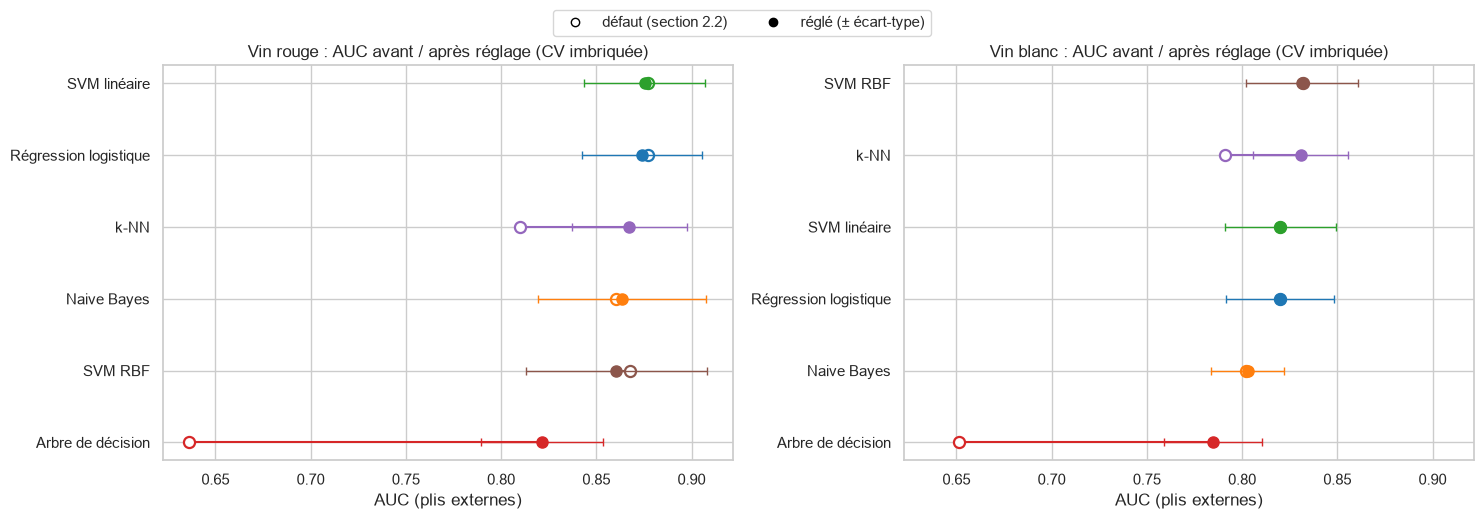

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, k in zip(axes, KINDS):
    t = tuning[tuning["vin"] == LABELS[k]].sort_values("AUC")
    y = np.arange(len(t))
    for yi, (_, r) in zip(y, t.iterrows()):
        color = FAMILY_COLORS[model_family(r["modèle"])]
        ax.plot([r["AUC défaut"], r["AUC"]], [yi, yi], color=color, lw=1.5)
        ax.plot(r["AUC défaut"], yi, "o", mfc="white", mec=color, mew=1.6, ms=8)
        ax.errorbar(r["AUC"], yi, xerr=r["AUC std"], fmt="o", color=color, ms=8, capsize=3, elinewidth=1)
    ax.set_yticks(y, t["modèle"])
    ax.set(title=f"{LABELS[k]} : AUC avant / après réglage (CV imbriquée)", xlabel="AUC (plis externes)")
handles = [plt.Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="défaut (section 2.2)"),
           plt.Line2D([], [], marker="o", ls="", color="black", label="réglé (± écart-type)")]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()
savefig(fig, "tuning_gain")

**Lecture :**
- **Modèles linéaires : le réglage n'apporte rien.** Régression logistique, SVM linéaire et Naive Bayes restent à ± 0,003 d'AUC de leur version par défaut (0,874-0,875 en rouge, 0,820 en blanc), avec autant de plis améliorés que dégradés. Leurs valeurs par défaut étaient déjà sur le plateau (voir le profil de `C` en section 30) ; la sélection de variables n'est retenue que pour Naive Bayes (L1 en rouge, retrait de `density` en blanc), pour un gain négligeable.
- **k-NN et arbre : gain net et régulier.** k-NN : +0,057 (rouge) et +0,040 (blanc), sur les 5 plis externes ; arbre : +0,185 et +0,133. Les réglages retenus confirment la section 18 : k = 21-33 voisins pondérés par la distance, arbre de profondeur 5-6 mais freiné par `min_samples_leaf` (20-40) et l'élagage `ccp_alpha`. Le k-NN réglé rejoint les modèles linéaires (0,867 / 0,831) ; l'arbre reste derrière (0,822 / 0,785).
- **SVM RBF :** aucun gain mesurable (−0,007 / −0,001). En rouge, son `best_score_` (0,880) dépasse de 0,02 son AUC imbriquée (0,860), avec l'écart-type le plus élevé (0,048) : sur 1 087 vins, choisir `C` et `gamma` sur les mêmes plis surestime le score. C'est exactement ce que la validation croisée imbriquée corrige.
- **Optimisme de `best_score_` :** l'écart interne − imbriqué va de 0 à 0,02 ; il est le plus fort pour les modèles aux grands espaces de recherche (arbre, k-NN, SVM RBF).
- **F1 au seuil par défaut :** il baisse pour certains modèles réglés (k-NN, LogReg en rouge) alors que l'AUC est stable, car la recherche optimise l'AUC et non le seuil. Le seuil est réglé en section 32.

## 30. Grid Search, Random Search et Halving sur le SVM RBF

Le SVM RBF a deux hyperparamètres continus. On compare, **à budget égal (64 candidats)** :
- **Grid Search** : grille 8 × 8 régulière en échelle log (`C` de 10⁻² à 10³, `gamma` de 10⁻⁴ à 1) ;
- **Random Search** : 64 tirages log-uniformes sur les mêmes plages (la recherche de la section 29) ;
- **Halving Random Search** (`HalvingRandomSearchCV`) : 64 candidats évalués d'abord sur 150 vins du train ; seule la meilleure moitié passe à l'étape suivante, avec 2 fois plus de données, jusqu'à utiliser tout le train. (Partir de moins de vins laisserait des plis sans aucun bon vin.)

La carte montre l'AUC de la grille ; les points sont les tirages aléatoires (même échelle de couleur).

In [50]:
C_GRID, G_GRID = np.logspace(-2, 3, 8), np.logspace(-4, 0, 8)
svm_rows, svm_searches = [], {}
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    pipe = tunable(k, "SVM RBF")
    searches = {
        "Grid Search (8 x 8)": GridSearchCV(pipe, {"model__C": C_GRID, "model__gamma": G_GRID},
                                            scoring="roc_auc", cv=CV, n_jobs=-1),
        "Halving Random Search": HalvingRandomSearchCV(pipe, SVM_DIST, n_candidates=N_ITER, factor=2,
                                                       min_resources=150, scoring="roc_auc", cv=CV,
                                                       random_state=SEED, n_jobs=-1),
    }
    for meth, s in searches.items():
        t0 = time.perf_counter()
        s.fit(X_tr, y_tr)
        svm_searches[(k, meth)] = (s, time.perf_counter() - t0)
    svm_searches[(k, "Random Search (64)")] = (TUNED[(k, "SVM RBF")]["search"], TUNED[(k, "SVM RBF")]["time"])
    for meth in ["Grid Search (8 x 8)", "Random Search (64)", "Halving Random Search"]:
        s, dt = svm_searches[(k, meth)]
        n_fits = len(s.cv_results_["params"]) * CV.get_n_splits()
        svm_rows.append({"vin": LABELS[k], "méthode": meth, "évaluations (candidat x pli)": n_fits,
                         "meilleure AUC (CV interne)": s.best_score_,
                         "C": s.best_params_["model__C"], "gamma": s.best_params_["model__gamma"], "temps (s)": dt})
svm_compare = pd.DataFrame(svm_rows)
svm_compare.set_index(["vin", "méthode"]).round(4)

évaluations (candidat x pli)  meilleure AUC (CV interne)        C      gamma  temps (s)
vin       méthode                                                                                                       
Vin rouge Grid Search (8 x 8)                             320                       0.880    1.389  1.930e-02      1.173
          Random Search (64)                              320                       0.880    4.108  5.100e-03      1.020
          Halving Random Search                           560                       0.856  145.282  7.000e-04      1.441
Vin blanc Grid Search (8 x 8)                             320                       0.835   37.276  5.200e-03      7.618
          Random Search (64)                              320                       0.834   26.373  5.800e-03      6.727
          Halving Random Search                           620                       0.830    4.108  5.100e-03      2.431

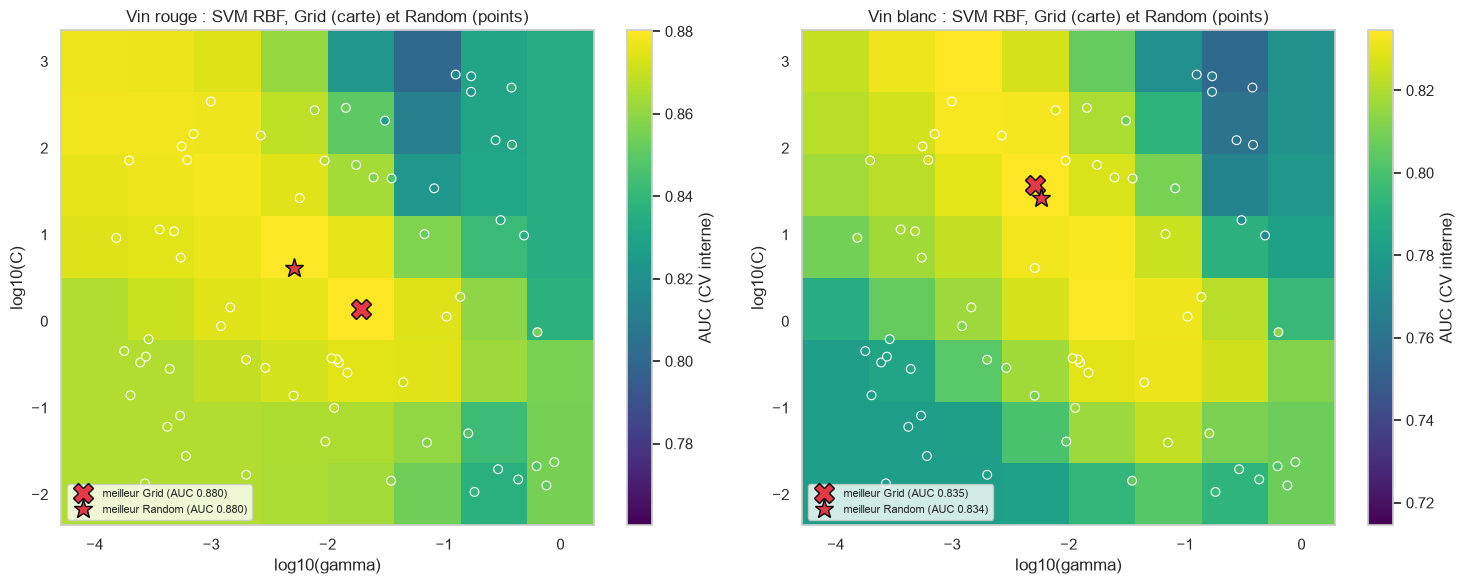

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, k in zip(axes, KINDS):
    grid, _ = svm_searches[(k, "Grid Search (8 x 8)")]
    rnd, _ = svm_searches[(k, "Random Search (64)")]
    auc = grid.cv_results_["mean_test_score"].reshape(len(C_GRID), len(G_GRID))
    vmin = auc.max() - 0.12
    mesh = ax.pcolormesh(np.log10(G_GRID), np.log10(C_GRID), auc, shading="nearest", cmap="viridis",
                         vmin=vmin, vmax=auc.max())
    rp = rnd.cv_results_["params"]
    ax.scatter([np.log10(p["model__gamma"]) for p in rp], [np.log10(p["model__C"]) for p in rp],
               c=rnd.cv_results_["mean_test_score"], cmap="viridis", vmin=vmin, vmax=auc.max(),
               edgecolors="white", linewidths=0.8, s=40)
    for s, marker, lab in [(grid, "X", "meilleur Grid"), (rnd, "*", "meilleur Random")]:
        bp = s.best_params_
        ax.plot(np.log10(bp["model__gamma"]), np.log10(bp["model__C"]), marker, color="#e63946", ms=14,
                mec="black", label=f"{lab} (AUC {s.best_score_:.3f})")
    fig.colorbar(mesh, ax=ax, label="AUC (CV interne)")
    ax.set(title=f"{LABELS[k]} : SVM RBF, Grid (carte) et Random (points)", xlabel="log10(gamma)", ylabel="log10(C)")
    ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
savefig(fig, "svm_grid_vs_random")

**Lecture :**
- **Grid et Random Search trouvent la même AUC** à budget égal : 0,880 / 0,880 en rouge, 0,835 / 0,834 en blanc, pour le même temps (320 apprentissages chacun). Leurs meilleurs points sont différents (rouge : C = 1,4 et gamma = 0,019 pour la grille, C = 4,1 et gamma = 0,005 pour le Random Search) mais tous deux sur la **même crête** jaune : quand gamma diminue (frontière plus lisse), il faut un C plus grand. La zone optimale est large, d'où l'égalité.
- Le Random Search essaie **64 valeurs distinctes** de chaque paramètre contre 8 pour la grille : sur un espace continu, il explore mieux chaque dimension pour le même coût. C'est pourquoi on l'a retenu pour le SVM RBF.
- Les deux méthodes choisissent un gamma faible (≈ 0,005-0,02, contre 1/11 ≈ 0,09 pour `gamma="scale"`) : une frontière **presque linéaire**, cohérente avec la section 23.
- **Halving Random Search :** 2,4 s contre 7-8 s en blanc, soit 3 fois plus rapide, pour une AUC proche (0,830). En rouge, il n'apporte rien (jeu trop petit pour en profiter) et son meilleur score (0,856) est mesuré sur 600 vins seulement à la dernière étape, donc pas directement comparable. Il devient intéressant quand le jeu de données ou l'espace de recherche grandissent.

**Profil de la grille de la régression logistique.** AUC (CV interne) en fonction de `C`, toutes variables, pour les pénalités L2 (`l1_ratio=0`) et L1 (`l1_ratio=1`) : il montre à partir de quelle force de régularisation le score se dégrade.

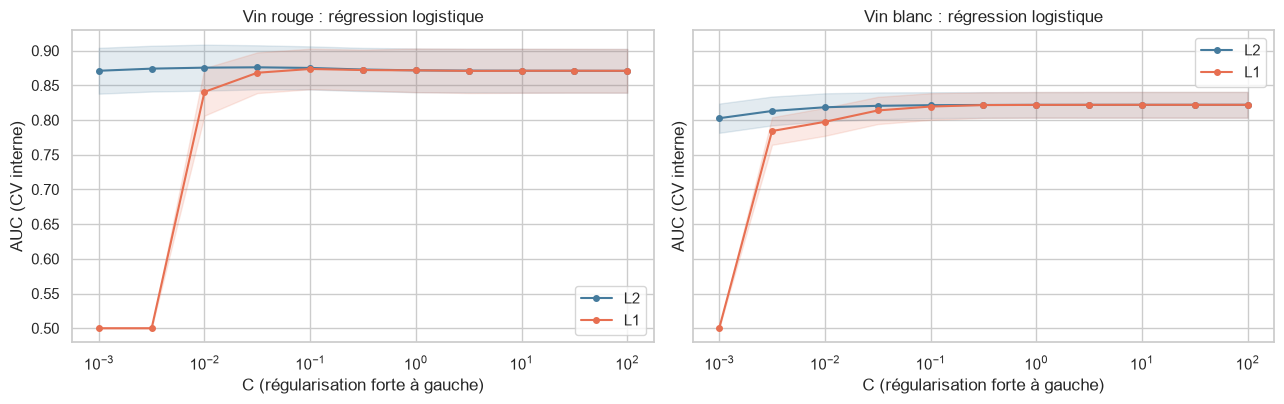

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, k in zip(axes, KINDS):
    res = TUNED[(k, "Régression logistique")]["search"].cv_results_
    df = pd.DataFrame({"C": [p["model__C"] for p in res["params"]],
                       "l1_ratio": [p["model__l1_ratio"] for p in res["params"]],
                       "prep": [short(p["prep"]) for p in res["params"]],
                       "select": [short(p["select"]) for p in res["params"]],
                       "auc": res["mean_test_score"], "std": res["std_test_score"]})
    df = df[(df["prep"] == "toutes") & (df["select"] == "passthrough")]
    for l1, color, lab in [(0, "#457b9d", "L2"), (1, "#e76f51", "L1")]:
        d = df[df["l1_ratio"] == l1].sort_values("C")
        ax.plot(d["C"], d["auc"], marker="o", ms=4, color=color, label=lab)
        ax.fill_between(d["C"], d["auc"] - d["std"], d["auc"] + d["std"], color=color, alpha=0.15)
    ax.set(xscale="log", title=f"{LABELS[k]} : régression logistique", xlabel="C (régularisation forte à gauche)",
           ylabel="AUC (CV interne)")
    ax.legend()
fig.tight_layout()
savefig(fig, "logreg_C_profile")

**Lecture :** avec la pénalité L2, l'AUC est **plate** de C = 10⁻³ à 10² (≈ 0,87 en rouge, 0,82 en blanc) : avec 11 variables et plus de 1 000 vins, la régression logistique ne surapprend pas et la régularisation ne change presque rien. La pénalité L1 s'effondre pour C ≤ 3·10⁻³ : tous les coefficients sont mis à zéro et le modèle devient constant (AUC 0,5). Les valeurs choisies (C = 0,03 en rouge, 31,6 en blanc) sont très différentes mais toutes deux sur le plateau : cet écart n'a pas de signification.

## 31. Biais / variance après réglage

Même diagnostic qu'à la section 24 (AUC train et validation sur les plis `CV`), pour les modèles réglés. Les points creux sont les modèles par défaut (section 24), les points pleins les modèles réglés. L'AUC de validation est ici un peu optimiste (hyperparamètres choisis sur ces plis) ; l'intérêt est l'**écart** train − validation.

AUC train  AUC validation  std validation  écart train - validation  écart avant réglage  \
vin       modèle                                                                                                            
Vin rouge Régression logistique      0.887           0.876           0.032                     0.011                0.017   
          Naive Bayes                0.881           0.860           0.033                     0.021                0.025   
          k-NN                       1.000           0.880           0.021                     0.120                0.150   
          Arbre de décision          0.926           0.841           0.035                     0.085                0.351   
          SVM linéaire               0.887           0.877           0.032                     0.010                0.015   
          SVM RBF                    0.894           0.880           0.030                     0.014                0.073   
Vin blanc Régression logistique      0.825           0.822           0.019                     0.003                0.003   
          Naive Bayes                0.811           0.809           0.019                     0.003                0.003   
          k-NN                       1.000           0.835           0.018                     0.165                0.125   
          Arbre de décision          0.840           0.795           0.021                     0.045                0.343   
          SVM linéaire               0.824           0.822           0.019                     0.002                0.003   
          SVM RBF                    0.850           0.834           0.023                     0.016                0.055   

                                 AUC validation avant réglage  
vin       modèle                                               
Vin rouge Régression logistique                         0.872  
          Naive Bayes                                   0.848  
          k-NN                                          0.791  
          Arbre de décision                             0.649  
          SVM linéaire                                  0.873  
          SVM RBF                                       0.875  
Vin blanc Régression logistique                         0.822  
          Naive Bayes                                   0.802  
          k-NN                                          0.792  
          Arbre de décision                             0.657  
          SVM linéaire                                  0.822  
          SVM RBF                                       0.831

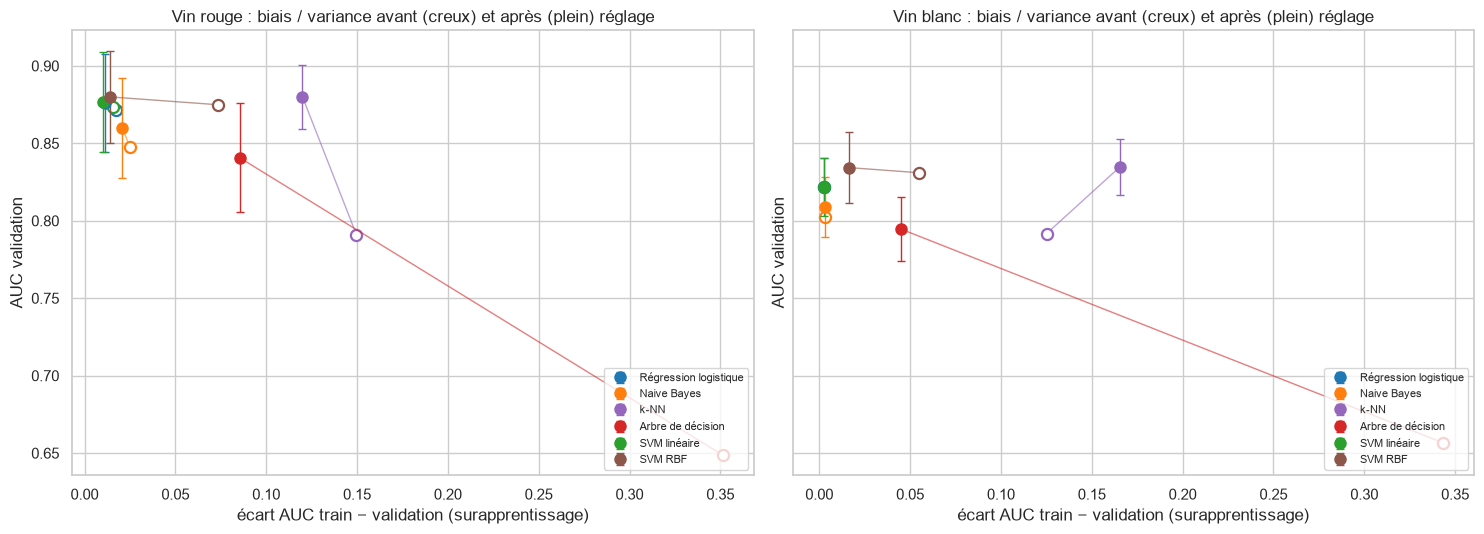

In [53]:
bv_rows = []
for (k, name), r in TUNED.items():
    X_tr, _, y_tr, _ = splits[k]
    res = cross_validate(r["search"].best_estimator_, X_tr, y_tr, cv=CV, scoring="roc_auc",
                         return_train_score=True, n_jobs=-1)
    before = bias_variance.loc[(LABELS[k], name)]
    bv_rows.append({"vin": LABELS[k], "modèle": name,
                    "AUC train": res["train_score"].mean(), "AUC validation": res["test_score"].mean(),
                    "std validation": res["test_score"].std(),
                    "écart train - validation": res["train_score"].mean() - res["test_score"].mean(),
                    "écart avant réglage": before["écart train - validation"],
                    "AUC validation avant réglage": before["AUC validation"]})
bv_tuned = pd.DataFrame(bv_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, k in zip(axes, KINDS):
    for _, r in bv_tuned[bv_tuned["vin"] == LABELS[k]].iterrows():
        color = FAMILY_COLORS[model_family(r["modèle"])]
        ax.plot([r["écart avant réglage"], r["écart train - validation"]],
                [r["AUC validation avant réglage"], r["AUC validation"]], color=color, lw=1, alpha=0.6)
        ax.plot(r["écart avant réglage"], r["AUC validation avant réglage"], "o", mfc="white", mec=color, mew=1.6, ms=8)
        ax.errorbar(r["écart train - validation"], r["AUC validation"], yerr=r["std validation"], fmt="o",
                    color=color, ms=8, capsize=3, elinewidth=1, label=r["modèle"])
    ax.set(title=f"{LABELS[k]} : biais / variance avant (creux) et après (plein) réglage",
           xlabel="écart AUC train − validation (surapprentissage)", ylabel="AUC validation")
    ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
savefig(fig, "bias_variance_tuned")
bv_tuned.set_index(["vin", "modèle"]).round(3)

**Lecture :**
- **Arbre :** l'écart train − validation passe de 0,35 à 0,085 (rouge) et de 0,34 à 0,045 (blanc). `min_samples_leaf` et l'élagage ont supprimé l'essentiel du surapprentissage, et l'AUC de validation gagne 0,14 à 0,19.
- **SVM RBF :** l'écart passe de 0,073 à 0,014 en rouge et de 0,055 à 0,016 en blanc, pour la même AUC de validation. Le réglage a choisi un modèle plus lisse, qui obtient le même score avec **moins de variance** : au niveau des modèles linéaires.
- **k-NN :** l'AUC train vaut 1 parce que les voisins sont pondérés par la distance : chaque vin du train est son propre voisin, à distance nulle. Cet écart (0,12-0,17) est un artefact de `weights="distance"`, pas un signe de mauvaise généralisation : l'AUC de validation est passée de 0,79 à 0,84-0,88.
- **Modèles linéaires :** inchangés (écart ≤ 0,02). Leur limite reste le biais, que le réglage ne peut pas corriger.

## 32. Choix du modèle final et du seuil

Même règle qu'en section 25, appliquée aux **AUC imbriquées** des modèles réglés : meilleure AUC moyenne, puis, parmi les modèles à moins d'un écart-type de celle-ci, le plus simple. Le modèle retenu est le meilleur estimateur de sa recherche, réappris sur tout le train.

Comme annoncé en section 25, le seuil est **choisi à nouveau** sur les prédictions hors-pli (plis `CV`) du modèle réglé, en maximisant le F1.

In [54]:
FINAL_NAME, FINAL_MODEL, FINAL_THRESHOLD, FINAL_OOF = {}, {}, {}, {}
final_rows = []
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    name, candidates = select_model(tuning[tuning["vin"] == LABELS[k]])
    pipe = TUNED[(k, name)]["search"].best_estimator_
    pred, score = oof_predictions(pipe, X_tr, y_tr)
    t_best = best_f1_threshold(y_tr, score)[0]
    FINAL_NAME[k], FINAL_MODEL[k], FINAL_THRESHOLD[k], FINAL_OOF[k] = name, pipe, t_best, score
    pred_best = (score >= t_best).astype(int)
    final_rows.append({
        "vin": LABELS[k], "modèle retenu": name, "candidats (à 1 écart-type)": ", ".join(candidates),
        "paramètres": describe(TUNED[(k, name)]["search"].best_params_),
        "AUC imbriquée": tuning.set_index(["vin", "modèle"]).loc[(LABELS[k], name), "AUC"],
        "seuil (F1 max)": t_best, "seuil en 2.3": THRESHOLD[k],
        "F1 hors-pli, seuil par défaut": f1_score(y_tr, pred), "F1 hors-pli, seuil choisi": f1_score(y_tr, pred_best),
        "précision": precision_score(y_tr, pred_best), "rappel": recall_score(y_tr, pred_best),
    })
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(final_rows).set_index("vin").T)

vin,Vin rouge,Vin blanc
modèle retenu,Régression logistique,Régression logistique
candidats (à 1 écart-type),"Régression logistique, Naive Bayes, k-NN, SVM linéaire, SVM RBF","Régression logistique, Naive Bayes, k-NN, SVM linéaire, SVM RBF"
paramètres,"C=0.0316, l1_ratio=0, prep=toutes, select=passthrough","C=31.6, l1_ratio=0, prep=toutes, select=passthrough"
AUC imbriquée,0.874,0.82
seuil (F1 max),0.691,0.537
seuil en 2.3,0.73,0.523
"F1 hors-pli, seuil par défaut",0.497,0.558
"F1 hors-pli, seuil choisi",0.554,0.564
précision,0.462,0.451
rappel,0.694,0.753


**Lecture :**
- La règle désigne à nouveau la **régression logistique** pour les deux types de vin. Après réglage, tous les modèles sauf l'arbre sont à moins d'un écart-type du meilleur : aucun ne se détache, et la régression logistique est la plus simple.
- **Rouge :** C = 0,03 (régularisation L2 forte), toutes les variables. Le seuil optimal est de 0,69 (0,73 en 2.3) : le F1 hors-pli passe de 0,50 à 0,55, avec une précision de 0,46 et un rappel de 0,69.
- **Blanc :** C = 31,6 (presque pas de régularisation), toutes les variables. Seuil de 0,54, proche du défaut : F1 de 0,56, rappel 0,75, précision 0,45.
- Le seuil est choisi sur les mêmes plis que les hyperparamètres : le F1 hors-pli est légèrement optimiste. Le test dira s'il tient.

## 33. Évaluation finale sur le jeu de test

Appel **unique** de `final_evaluation` (section 26) pour chaque type de vin : le modèle retenu est réappris sur tout le train avec ses hyperparamètres réglés, puis le test est prédit au seuil choisi en section 32. Aucune décision n'est prise après cette étape. Les scores hors-pli du train sont rappelés pour comparaison.

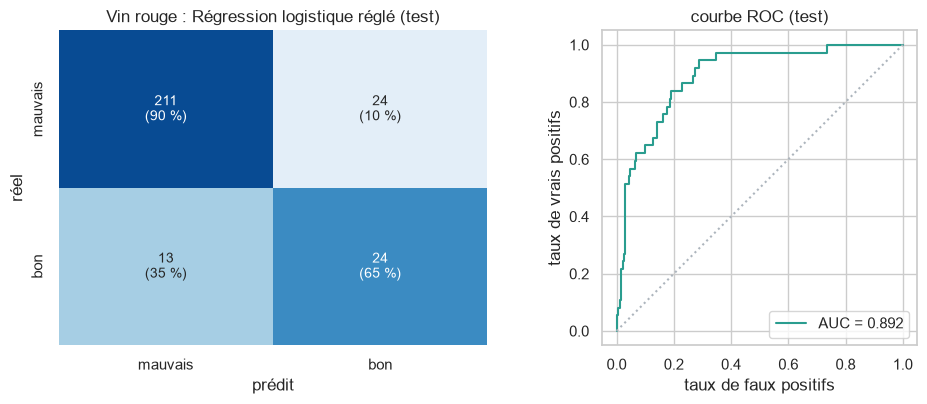

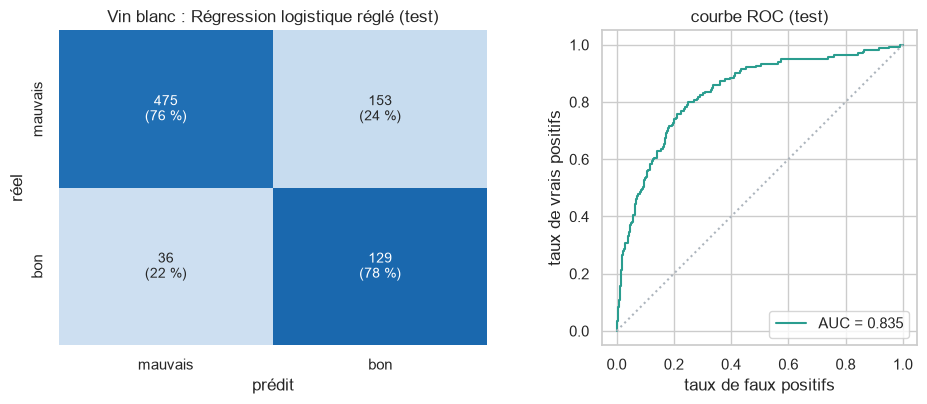

Vin rouge                    Vin blanc         
                  CV hors-pli (train)     test CV hors-pli (train)     test
accuracy                        0.849    0.864               0.758    0.762
précision                       0.462    0.500               0.451    0.457
rappel                          0.694    0.649               0.753    0.782
spécificité                     0.873    0.898               0.759    0.756
F1                              0.554    0.565               0.564    0.577
balanced accuracy               0.784    0.773               0.756    0.769
AUC                             0.875    0.892               0.821    0.835
AP                              0.493    0.569               0.527    0.589
VP                            102.000   24.000             497.000  129.000
FP                            119.000   24.000             604.000  153.000
FN                             45.000   13.000             163.000   36.000
VN                            821.000  211.000            1904.000  475.000

In [55]:
test_results = {}
for k in KINDS:
    X_tr, _, y_tr, _ = splits[k]
    name = FINAL_NAME[k]
    test = final_evaluation(FINAL_MODEL[k], k, FINAL_THRESHOLD[k], name=f"{name} réglé")
    cv = pd.Series(evaluate(y_tr, (FINAL_OOF[k] >= FINAL_THRESHOLD[k]).astype(int), FINAL_OOF[k]))
    test_results[(LABELS[k], "CV hors-pli (train)")] = cv
    test_results[(LABELS[k], "test")] = test
    plt.show()
final_table = pd.DataFrame(test_results)
final_table.round(3)

**Lecture :**
- **Rouge :** AUC 0,892 sur le test (0,875 en CV), F1 0,565 (0,554). Le modèle trouve 24 des 37 bons vins (rappel 0,65) et la moitié des vins annoncés bons le sont vraiment (précision 0,50).
- **Blanc :** AUC 0,835 (0,821 en CV), F1 0,577 (0,564) ; 129 bons vins trouvés sur 165 (rappel 0,78), précision 0,46.
- Les scores de test sont **légèrement meilleurs** que ceux de la validation croisée, et dans la marge d'incertitude annoncée (± 0,03 d'AUC en rouge, ± 0,02 en blanc, section 24). Il n'y a donc **aucun signe de surapprentissage du réglage** : les estimations par validation croisée étaient fiables. Le test rouge ne contient que 37 bons vins : un seul vin de plus ou de moins change le rappel de 2,7 points, ces chiffres sont à lire avec cette marge.
- Ces résultats sont définitifs : aucun choix n'est modifié après cette évaluation.

## 34. Conclusion de la partie 2.4

- **Grid Search** pour les espaces discrets ou petits (5 modèles), **Random Search** pour le SVM RBF ; à budget égal, les deux trouvent la même AUC, le Random Search explorant mieux les paramètres continus. Le **Halving** divise le temps par 3 sur le blanc pour un score proche.
- **Évaluation par validation croisée imbriquée** (5 × 5 plis) : elle corrige l'optimisme de `best_score_` (jusqu'à 0,02 d'AUC pour le SVM RBF rouge).
- **Le réglage profite surtout aux modèles non linéaires mal réglés par défaut** (arbre +0,13 à +0,19 d'AUC, k-NN +0,04 à +0,06) et réduit fortement leur surapprentissage. Il n'apporte rien aux modèles linéaires, déjà sur leur plateau.
- **Modèle final : régression logistique réglée** (rouge : C = 0,03 ; blanc : C = 31,6 ; pénalité L2, toutes les variables), avec un seuil réglé en validation croisée (0,69 / 0,54).
- **Performance sur le test (évaluation unique) :** AUC 0,892 et F1 0,565 en rouge, AUC 0,835 et F1 0,577 en blanc, en accord avec la validation croisée. Le plafond reste la frontière floue entre les notes 6 et 7, pas le choix ni le réglage du modèle.